# GELAR RASA 2026 ? EDA, preprocessing, modeling, dan submission

Notebook tunggal memuat pemeriksaan 1.920 foto train dan 480 foto test, EDA, preprocessing, pengelompokan kategori, validasi berdasarkan source group, lalu membuat kandidat submission 001?004 dan 008. Kandidat 008 memakai descriptor DINOv3 image-only dan One-vs-Rest RBF SVM yang dilatih pada train eligible.

Kategori train adalah hasil pipeline peserta dan belum ground truth resmi. Evaluasi terhadap kategori turunan hanya diagnostik; bukan Accuracy semantik resmi. Test hanya dipakai untuk ekstraksi fitur tetap dan inferensi pada tahap submission train-only. Sel adaptasi pseudo-label test tidak dijalankan.


In [1]:
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from collections import Counter
import os, sys, json, hashlib, time, platform, html
import importlib.metadata as metadata
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import imagehash
import cv2
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML

STARTED = time.time()
SEED = 20261106
np.random.seed(SEED)
CLASSES = ['glass', 'paper', 'electronic', 'metal', 'plastic', 'cardboard', 'textile', 'foodwaste']
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = Path(os.environ['GELAR_PROJECT_ROOT']).resolve() if 'GELAR_PROJECT_ROOT' in os.environ else next(
    (p for p in candidates if (p / 'data/Dataset DSC GelarRasa 2026').exists()), Path.cwd())
DATA = Path(os.environ.get('GELAR_DATA_DIR', str(ROOT / 'data'))).resolve()
RAW = DATA / 'Dataset DSC GelarRasa 2026'
MAX_WORKERS = min(4, os.cpu_count() or 1)
PROCESSED = ROOT / 'data/processed'
PROFILE_HOME = PROCESSED
PROFILE_HOME.mkdir(parents=True, exist_ok=True)
INPUT_PATH = DATA / 'preprocessing_inputs.npz'
assert INPUT_PATH.is_file(), 'Input snapshot preprocessing belum tersedia.'

def digest(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''): h.update(block)
    return h.hexdigest()

def relative(path):
    path = Path(path).resolve()
    try: return path.relative_to(ROOT).as_posix()
    except ValueError: return str(path)

def resolve(path):
    path = Path(path)
    return path if path.is_absolute() else ROOT / path

def rgb_image(path):
    with Image.open(path) as source:
        im = ImageOps.exif_transpose(source)
        if 'A' in im.getbands() or 'transparency' in im.info:
            rgba = im.convert('RGBA')
            im = Image.alpha_composite(Image.new('RGBA', rgba.size, (255, 255, 255, 255)), rgba)
        return im.convert('RGB').copy()


import re

FIGURES = ROOT / 'final-submit/reports'
FINAL_OUTPUT = ROOT / 'final-submit/output'
FIGURES.mkdir(parents=True, exist_ok=True)
FINAL_OUTPUT.mkdir(parents=True, exist_ok=True)
figure_exports = []

def publish_figure():
    figure = plt.gcf()
    title = figure._suptitle.get_text() if figure._suptitle else ' '.join(ax.get_title() for ax in figure.axes[:3])
    stem = re.sub(r'[^a-z0-9]+', '_', title.lower()).strip('_')[:85] or 'visualisasi_eda'
    path = FIGURES / f'{len(figure_exports) + 1:02d}_{stem}.png'
    figure.savefig(path, dpi=130, bbox_inches='tight')
    figure_exports.append({'path': relative(path), 'title': title, 'sha256': digest(path)})
    plt.show()
    plt.close(figure)


def gallery(frame, title, pathcol='source_path', limit=12, columns=4, caption=None):
    frame = frame.head(limit)
    if frame.empty:
        display(Markdown(title + ': tidak ada contoh pada kondisi ini.')); return
    rows = int(np.ceil(len(frame) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(3 * columns, 2.8 * rows), squeeze=False, dpi=85)
    for ax in axes.flat: ax.axis('off')
    for ax, row in zip(axes.flat, frame.to_dict('records')):
        im = rgb_image(resolve(row[pathcol])); im.thumbnail((300, 260))
        ax.imshow(im)
        label = caption(row) if caption else f"{row.get('split', '')} {row.get('image_id', row.get('sample_id', ''))}"
        ax.set_title(label, fontsize=9)
    fig.suptitle(title, fontsize=13); fig.tight_layout(); publish_figure()

environment = {'python': sys.version, 'platform': platform.platform(), 'seed': SEED,
               'packages': {p: metadata.version(p) for p in ['numpy', 'pandas', 'Pillow', 'ImageHash', 'opencv-python', 'matplotlib']}}
print('Root:', ROOT)
print('Data:', RAW)
print('Interpreter:', sys.executable)
print('Lingkup: EDA, preprocessing, validasi, training, dan submission')
display(pd.Series(environment['packages'], name='versi pustaka'))

Root: D:\lomba\NSC UB\GELAR-RASA
Data: D:\lomba\NSC UB\GELAR-RASA\data\Dataset DSC GelarRasa 2026
Interpreter: D:\lomba\NSC UB\GELAR-RASA\.venv\Scripts\python.exe
Lingkup: EDA, preprocessing, validasi, training, dan submission


numpy               2.2.6
pandas              2.3.3
Pillow             12.2.0
ImageHash           4.3.2
opencv-python    5.0.0.93
matplotlib         3.10.8
Name: versi pustaka, dtype: object

## 1. Inventaris data dan integritas ID

Train dibaca dari file langsung di folder train, sehingga salinan pada subfolder tidak dihitung dua kali. Urutan test dibentuk dari ID numerik nama file di folder test dataset. Kekurangan, kelebihan atau ID ganda menghentikan pemrosesan.

In [2]:
EXTENSIONS = {'.jpg', '.jpeg', '.png', '.webp', '.bmp', '.tif', '.tiff'}
records = []
for split, width in [('train', 4), ('test', 3)]:
    directory = RAW / split
    files = sorted([p for p in directory.iterdir() if p.is_file() and p.suffix.lower() in EXTENSIONS], key=lambda p: int(p.stem))
    for path in files:
        assert path.stem.isdigit()
        image_id = str(int(path.stem)).zfill(width)
        records.append({'key': f'{split}:{image_id}', 'split': split, 'image_id': image_id,
                        'filename': path.name, 'source_path': relative(path)})
inventory = pd.DataFrame(records)
assert inventory.key.is_unique
assert inventory.groupby('split').size().to_dict() == {'test': 480, 'train': 1920}
assert set(inventory.loc[inventory.split.eq('train'), 'image_id']) == {f'{i:04d}' for i in range(1, 1921)}
test_order = sorted(inventory.loc[inventory.split.eq('test'), 'image_id'].astype(str).tolist(), key=int)
assert len(test_order) == len(set(test_order)) == 480
assert set(test_order) == set(inventory.loc[inventory.split.eq('test'), 'image_id'])
with ThreadPoolExecutor(MAX_WORKERS) as pool:
    inventory['source_sha256'] = list(pool.map(lambda p: digest(resolve(p)), inventory.source_path))
display(inventory.groupby('split').agg(gambar=('key', 'size'), ID_unik=('image_id', 'nunique')))
print('File dalam subfolder train tidak dienumerasi sebagai sampel tambahan.')

,gambar,ID_unik
split,,
test,480,480
train,1920,1920


File dalam subfolder train tidak dienumerasi sebagai sampel tambahan.


## 2. Profil piksel, format, ukuran, dan kualitas

Seluruh file didekode. Orientasi EXIF diterapkan sekali, transparansi dikompositkan pada putih, lalu RGB. Hash byte berbeda makna dari hash piksel terdekode. Brightness/contrast/saturation memakai rentang 0–1. Entropy, Laplacian dan edge fraction dihitung pada tampilan maksimal 256 piksel dengan rasio tetap.

Nilai Laplacian rendah dapat berasal dari permukaan polos; nilai ini tidak otomatis berarti gambar buruk. Ambang kualitas berikut hanya indikator EDA, tanpa penghapusan otomatis. Cache hanya digunakan bila ID dan seluruh hash byte sumber identik.

In [3]:
def profile_one(row):
    record = dict(row)
    try:
        path = resolve(row['source_path'])
        with Image.open(path) as source:
            record.update(source_format=source.format, source_mode=source.mode,
                          original_width=source.width, original_height=source.height,
                          exif_orientation=int(source.getexif().get(274, 1)),
                          has_alpha=('A' in source.getbands() or 'transparency' in source.info),
                          n_frames=int(getattr(source, 'n_frames', 1)))
        im = rgb_image(path)
        small = ImageOps.contain(im, (256, 256), method=Image.Resampling.LANCZOS)
        gray = np.asarray(small.convert('L'))
        rgb = np.asarray(small).astype(np.float32) / 255
        probabilities = np.bincount(gray.ravel(), minlength=256).astype(float) / gray.size
        probabilities = probabilities[probabilities > 0]
        record.update(byte_size=path.stat().st_size, width=im.width, height=im.height,
                      aspect_ratio=im.width / im.height, megapixels=im.width * im.height / 1e6,
                      pixel_sha256=hashlib.sha256(im.tobytes()).hexdigest(),
                      brightness=float(gray.mean() / 255), contrast=float(gray.std() / 255),
                      saturation=float(np.asarray(small.convert('HSV'))[:, :, 1].mean() / 255),
                      entropy_bits=float(-(probabilities * np.log2(probabilities)).sum()),
                      laplacian_variance_256=float(cv2.Laplacian(gray, cv2.CV_64F).var()),
                      edge_fraction=float((cv2.Canny(gray, 100, 200) > 0).mean()),
                      dark_fraction=float((gray < 13).mean()), bright_fraction=float((gray > 242).mean()),
                      phash=str(imagehash.phash(im)), phash_hflip=str(imagehash.phash(ImageOps.mirror(im))),
                      phash_vflip=str(imagehash.phash(ImageOps.flip(im))), dhash=str(imagehash.dhash(im)),
                      decode_status='ok', decode_error='')
    except Exception as exc:
        record.update(decode_status='error', decode_error=repr(exc))
    return record

with ThreadPoolExecutor(MAX_WORKERS) as pool:
    profile = pd.DataFrame(pool.map(profile_one, inventory.to_dict('records')))
failures = profile[profile.decode_status.ne('ok')]
display(failures)
assert len(profile) == 2400 and failures.empty, 'Ada sumber gagal decode; pemrosesan dihentikan.'
print('Seluruh 2.400 gambar diprofilkan dari sumber pada run ini.')

display(profile.groupby(['split', 'source_format', 'source_mode']).size().rename('jumlah').reset_index())
display(profile.groupby('split')[['width', 'height', 'aspect_ratio', 'megapixels', 'byte_size']].describe().round(3))
display(profile.groupby(['split', 'width', 'height']).size().rename('jumlah').reset_index().sort_values('jumlah', ascending=False).head(20))

,key,split,image_id,filename,source_path,source_sha256,source_format,source_mode,original_width,original_height,...,laplacian_variance_256,edge_fraction,dark_fraction,bright_fraction,phash,phash_hflip,phash_vflip,dhash,decode_status,decode_error


Seluruh 2.400 gambar diprofilkan dari sumber pada run ini.


,split,source_format,source_mode,jumlah
0,test,JPEG,RGB,479
1,test,PNG,RGB,1
2,train,JPEG,RGB,1918
3,train,PNG,P,1
4,train,PNG,RGBA,1


width                                                        height  \
        count     mean      std    min    25%    50%    75%     max   count   
split                                                                         
test    480.0  500.269  162.473  129.0  416.0  416.0  640.0  1600.0   480.0   
train  1920.0  549.182  259.502  100.0  416.0  509.0  640.0  2605.0  1920.0   

                ... megapixels        byte_size                                \
          mean  ...        75%    max     count       mean        std     min   
split           ...                                                             
test   479.754  ...       0.41  1.867     480.0  32772.173  54329.621  3114.0   
train  545.208  ...       0.41  9.145    1920.0  42886.840  89056.203  2132.0   

                                               
            25%      50%       75%        max  
split                                          
test   14518.25  22512.5  37670.75   885324.0  
train  15925.50  24924.5  42983.50  2689277.0  

[2 rows x 40 columns]

,split,width,height,jumlah
169,train,640,640,700
144,train,416,416,579
25,test,416,416,240
31,test,640,640,136
132,train,400,533,74
168,train,640,480,74
210,train,1599,1599,57
111,train,320,320,56
72,train,225,225,39
133,train,400,534,36


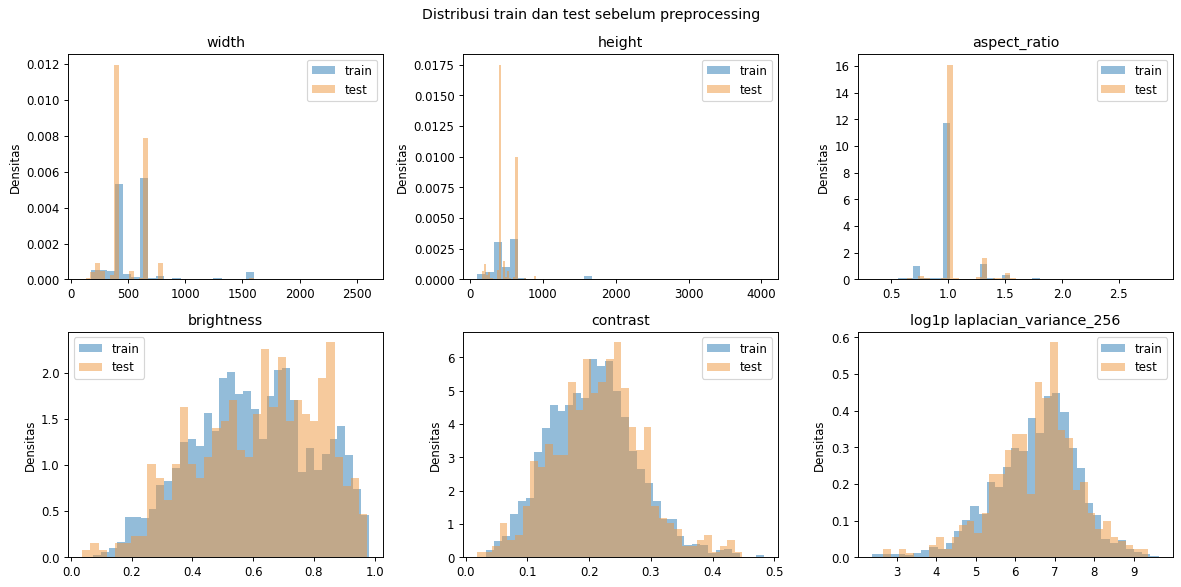

low_sharpness        53.647638
high_edge_density     0.276302
low_brightness        0.204253
high_brightness       0.943374
Name: ambang deskriptif dari train, dtype: float64

,low_sharpness_indicator,dense_edges_indicator,extreme_brightness_indicator
split,,,
test,8,6,16
train,39,39,78


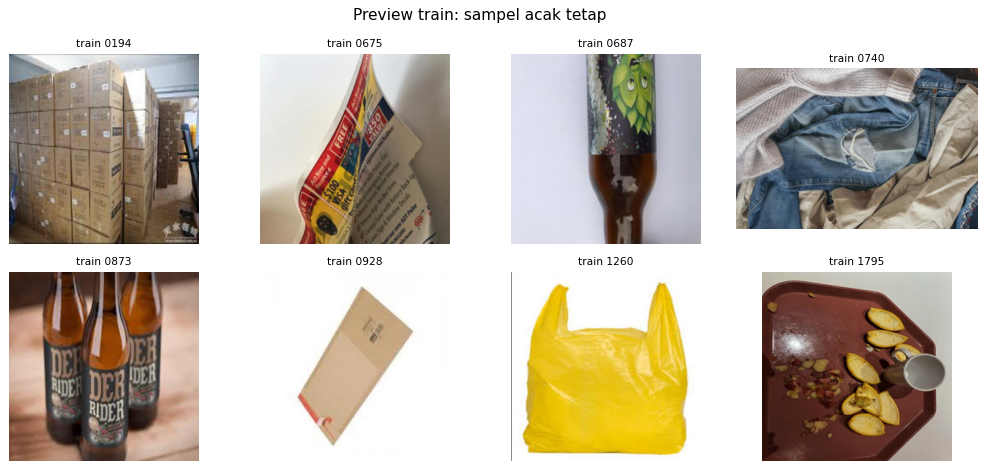

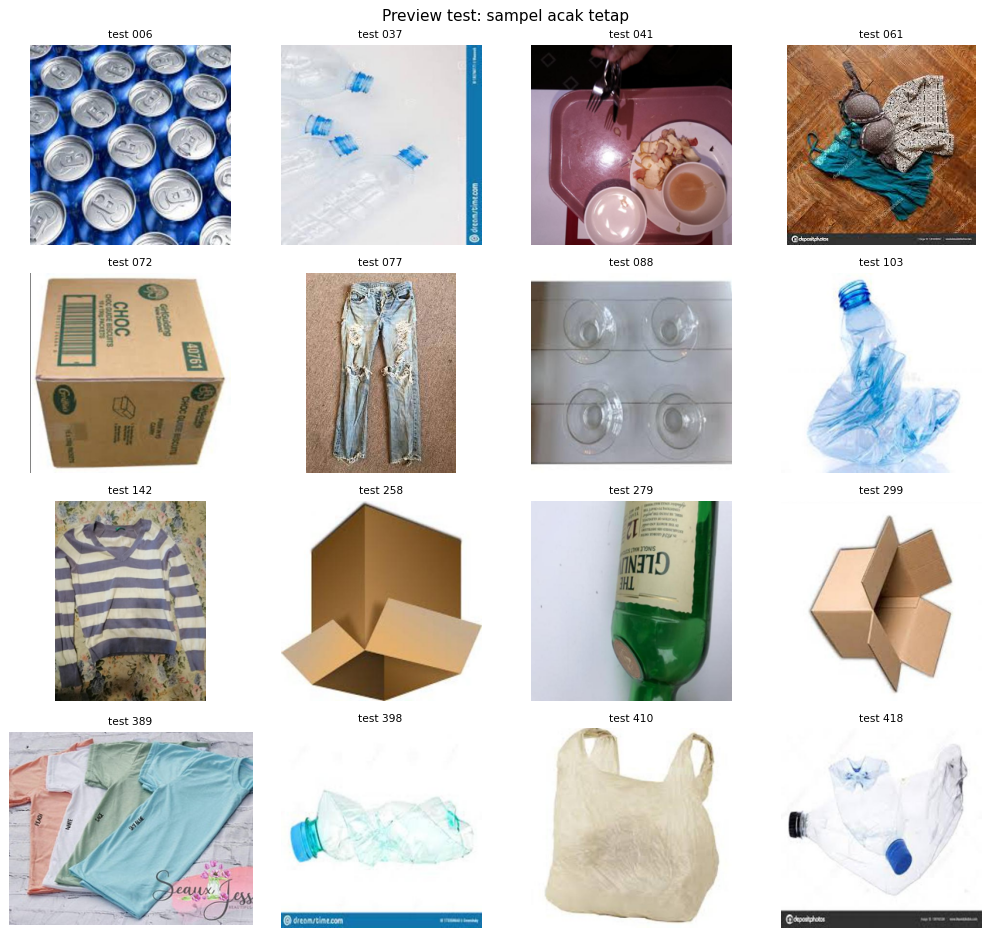

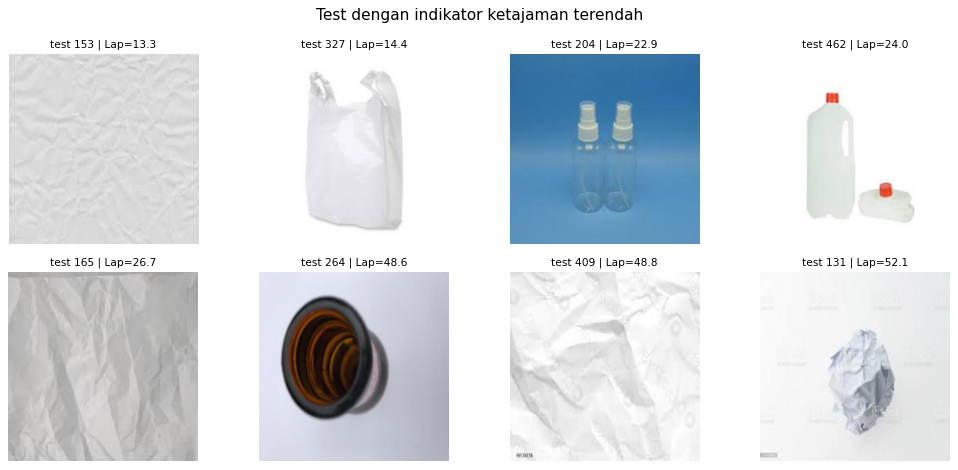

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), dpi=85)
for ax, column in zip(axes.flat, ['width', 'height', 'aspect_ratio', 'brightness', 'contrast', 'laplacian_variance_256']):
    for split, color in [('train', '#287bb5'), ('test', '#ef963d')]:
        values = profile.loc[profile.split.eq(split), column]
        values = np.log1p(values) if column == 'laplacian_variance_256' else values
        ax.hist(values, bins=35, alpha=.5, density=True, label=split, color=color)
    ax.set_title(('log1p ' if column == 'laplacian_variance_256' else '') + column)
    ax.set_ylabel('Densitas'); ax.legend()
fig.suptitle('Distribusi train dan test sebelum preprocessing'); fig.tight_layout(); publish_figure()

train_profile = profile[profile.split.eq('train')]
thresholds = {'low_sharpness': float(train_profile.laplacian_variance_256.quantile(.02)),
              'high_edge_density': float(train_profile.edge_fraction.quantile(.98)),
              'low_brightness': float(train_profile.brightness.quantile(.02)),
              'high_brightness': float(train_profile.brightness.quantile(.98))}
profile['low_sharpness_indicator'] = profile.laplacian_variance_256.le(thresholds['low_sharpness'])
profile['dense_edges_indicator'] = profile.edge_fraction.ge(thresholds['high_edge_density'])
profile['extreme_brightness_indicator'] = profile.brightness.le(thresholds['low_brightness']) | profile.brightness.ge(thresholds['high_brightness'])
display(pd.Series(thresholds, name='ambang deskriptif dari train'))
display(profile.groupby('split')[['low_sharpness_indicator', 'dense_edges_indicator', 'extreme_brightness_indicator']].sum())
gallery(profile[profile.split.eq('train')].sample(8, random_state=SEED).sort_values('image_id'), 'Preview train: sampel acak tetap', limit=8)
gallery(profile[profile.split.eq('test')].sample(16, random_state=SEED).sort_values('image_id'), 'Preview test: sampel acak tetap', limit=16)
gallery(profile[profile.split.eq('test')].nsmallest(8, 'laplacian_variance_256'), 'Test dengan indikator ketajaman terendah', limit=8,
        caption=lambda r: f"test {r['image_id']} | Lap={r['laplacian_variance_256']:.1f}")

## 3. Duplikat dan kemiripan train–test

Duplikat byte dan piksel diperiksa secara terpisah. Kesamaan piksel mensyaratkan ukuran yang sama. Pencarian pHash membandingkan setiap test dengan **seluruh train**, memakai minimum jarak Hamming pada tiga orientasi train: asli, horizontal flip, dan vertical flip. Ini bukan pencarian rotasi penuh atau bukti kesamaan bahan.

Ukuran identik dan pHash kecil hanya petunjuk; keduanya tidak menjadi label test. Pasangan terdekat diekspor untuk seluruh 480 test, disertai kesamaan ukuran dan hash piksel. Data test tidak dimasukkan ke train.

Anggota kelompok duplikat byte: **8**; piksel: **8**.

,key,width,height,pixel_sha256
847,train:0848,640,640,1f93428a09c7e418b8dcc24f2c813a41450e0ee3dd0976...
1716,train:1717,640,640,1f93428a09c7e418b8dcc24f2c813a41450e0ee3dd0976...
1961,test:042,640,640,fbef0ca5c3569f5528e55db389a951a2a8e3549eddc382...
1820,train:1821,640,640,fbef0ca5c3569f5528e55db389a951a2a8e3549eddc382...
2120,test:201,674,900,4bc0f7e4a1d9c5df21e890193293c9cea8c65a67793a93...
1134,train:1135,674,900,4bc0f7e4a1d9c5df21e890193293c9cea8c65a67793a93...
1936,test:017,800,533,8bb5e5af2d21ba8963e2d50a1043aa528b0396ee36ea71...
1045,train:1046,800,533,8bb5e5af2d21ba8963e2d50a1043aa528b0396ee36ea71...


count    480.000000
mean      14.354167
std        4.211474
min        0.000000
25%       14.000000
50%       16.000000
75%       16.000000
max       20.000000
Name: phash_hamming, dtype: float64

,test_id,train_id,rank,phash_hamming,same_native_size,same_decoded_pixels,test_width,test_height,train_width,train_height,test_path,train_path
48,017,1046,1,0,True,True,800,533,800,533,data/Dataset DSC GelarRasa 2026/test/017.jpg,data/Dataset DSC GelarRasa 2026/train/1046.jpg
78,027,1874,1,0,False,False,416,416,277,182,data/Dataset DSC GelarRasa 2026/test/027.jpg,data/Dataset DSC GelarRasa 2026/train/1874.jpg
123,042,1821,1,0,True,True,640,640,640,640,data/Dataset DSC GelarRasa 2026/test/042.jpg,data/Dataset DSC GelarRasa 2026/train/1821.jpg
198,067,0271,1,0,True,False,640,640,640,640,data/Dataset DSC GelarRasa 2026/test/067.jpg,data/Dataset DSC GelarRasa 2026/train/0271.jpg
207,070,0682,1,0,False,False,201,251,416,416,data/Dataset DSC GelarRasa 2026/test/070.jpg,data/Dataset DSC GelarRasa 2026/train/0682.jpg
222,075,1726,1,0,False,False,640,640,259,194,data/Dataset DSC GelarRasa 2026/test/075.jpg,data/Dataset DSC GelarRasa 2026/train/1726.jpg
360,121,1754,1,0,False,False,416,416,640,640,data/Dataset DSC GelarRasa 2026/test/121.jpg,data/Dataset DSC GelarRasa 2026/train/1754.jpg
468,157,0012,1,0,True,False,640,640,640,640,data/Dataset DSC GelarRasa 2026/test/157.jpg,data/Dataset DSC GelarRasa 2026/train/0012.jpg
519,174,0210,1,0,False,False,416,416,640,640,data/Dataset DSC GelarRasa 2026/test/174.jpg,data/Dataset DSC GelarRasa 2026/train/0210.jpg
600,201,1135,1,0,True,True,674,900,674,900,data/Dataset DSC GelarRasa 2026/test/201.jpg,data/Dataset DSC GelarRasa 2026/train/1135.jpg


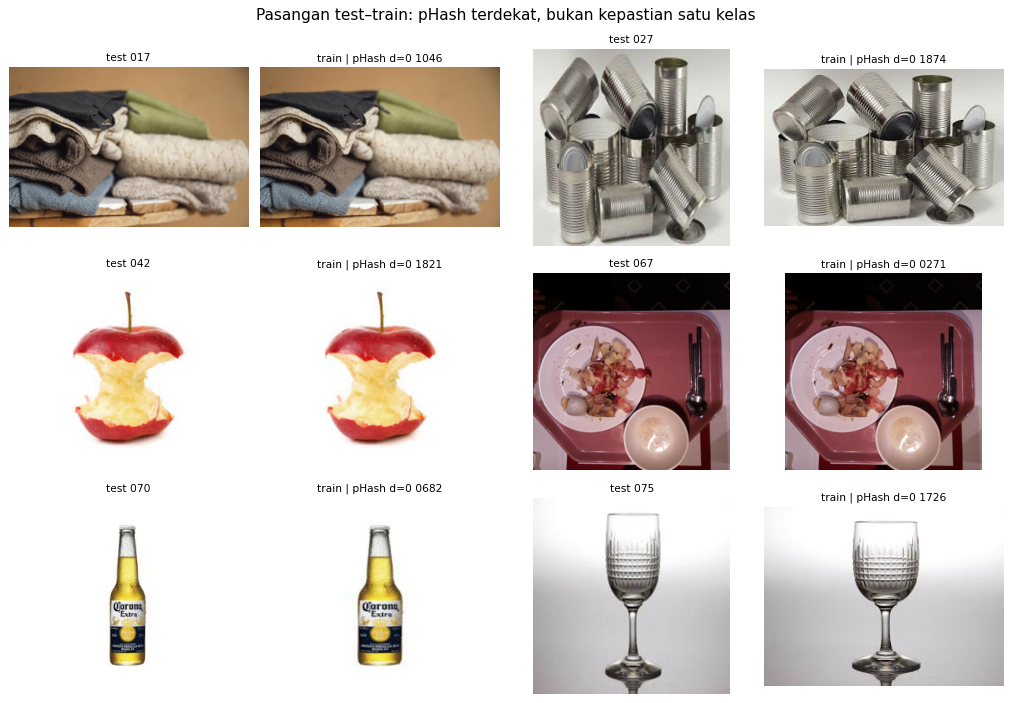

In [5]:
byte_duplicates = profile[profile.duplicated('source_sha256', keep=False)].sort_values(['source_sha256', 'key'])
pixel_cols = ['width', 'height', 'pixel_sha256']
pixel_duplicates = profile[profile.duplicated(pixel_cols, keep=False)].sort_values(pixel_cols + ['key'])
display(Markdown(f'Anggota kelompok duplikat byte: **{len(byte_duplicates)}**; piksel: **{len(pixel_duplicates)}**.'))
display(pixel_duplicates[['key', 'width', 'height', 'pixel_sha256']])

tr = profile[profile.split.eq('train')].reset_index(drop=True)
te = profile[profile.split.eq('test')].reset_index(drop=True)
train_hashes = [[int(r[c], 16) for c in ['phash', 'phash_hflip', 'phash_vflip']] for r in tr.to_dict('records')]
nearest_rows = []
for query in te.to_dict('records'):
    q = int(query['phash'], 16)
    distances = np.array([min((q ^ h).bit_count() for h in variants) for variants in train_hashes], dtype=np.int16)
    for rank, position in enumerate(np.argsort(distances, kind='stable')[:3], 1):
        candidate = tr.iloc[position]
        same_size = query['width'] == candidate.width and query['height'] == candidate.height
        nearest_rows.append({'test_id': query['image_id'], 'train_id': candidate.image_id, 'rank': rank,
                             'phash_hamming': int(distances[position]), 'same_native_size': bool(same_size),
                             'same_decoded_pixels': bool(same_size and query['pixel_sha256'] == candidate.pixel_sha256),
                             'test_width': query['width'], 'test_height': query['height'],
                             'train_width': candidate.width, 'train_height': candidate.height,
                             'test_path': query['source_path'], 'train_path': candidate.source_path})
nearest = pd.DataFrame(nearest_rows)
assert nearest.test_id.nunique() == 480 and len(nearest) == 1440
display(nearest[nearest['rank'].eq(1)].phash_hamming.describe())
display(nearest.sort_values(['phash_hamming', 'test_id', 'rank']).head(15))
best = nearest[nearest['rank'].eq(1)].sort_values(['phash_hamming', 'test_id']).head(6)
paired = []
for row in best.to_dict('records'):
    paired += [{'image_id': row['test_id'], 'split': 'test', 'source_path': row['test_path'], 'note': 'test'},
               {'image_id': row['train_id'], 'split': 'train', 'source_path': row['train_path'], 'note': f"train | pHash d={row['phash_hamming']}"}]
gallery(pd.DataFrame(paired), 'Pasangan test–train: pHash terdekat, bukan kepastian satu kelas', limit=12,
        caption=lambda r: f"{r['note']} {r['image_id']}")

## 4. Input kategori algoritmis dan integritas sumber

Snapshot memuat kategori foto utuh dari proses sebelumnya. Penyempurnaan memakai representasi objek dan material serta source group terpisah. Tahap classifier/graph dan cluster dilanjutkan dengan head neural yang diadaptasi pada train: loss ordinary cross-entropy untuk acuan manusia dan generalized cross-entropy untuk target otomatis. Tahap terbaru menambahkan representasi ViT image-only, kNN yang dipilih berdasarkan diagnostik acuan, dan label propagation train-only. Perubahan harus didukung beberapa bank fitur dan graph, bukan keputusan manual per ID. Seluruh skor tetap belum terkalibrasi. Kategori acuan manusia dicatat secara eksplisit. Test tidak dipakai dalam fit. Penahanan noise terbaru berlaku untuk training classifier berikutnya; assignment historis dalam snapshot tidak dihitung ulang pada run ini.

Sel ini memeriksa kecocokan ID dan hash sumber; tidak melatih ulang proses tersebut atau menganggap assignment sebagai ground truth. Skor adalah skor program, dukungan keluarga, atau indikator asal review manusia; bukan probabilitas terkalibrasi. Jumlah acuan manusia, sisa kapasitas dan kategorinya ditampilkan terpisah, maksimal lima foto sumber per kategori. Foto 1215 termasuk acuan cardboard yang dinyatakan tim, bukan perubahan otomatis yang disamarkan. Setiap tahap memiliki kriteria penerimaan tersendiri. Tahap classifier historis memeriksa dua pembobotan prior; tahap kNN memakai persetujuan bank fitur serta pemeriksaan kedekatan, dengan graph train-only pada tahap yang memakainya. Tahap pseudo-acuan saat ini dapat memakai kategori program terdahulu sebagai target lemah; konsistensi antarpseudo-label tidak menjadi validasi kebenaran kategori yang independen. Metode aktif dan kriterianya tercatat pada metadata snapshot; kriteria historis tidak diklaim sebagai pengujian ulang tahap terbaru. Perbaikan ontology pencahayaan memakai nama sumber yang spesifik dan pemeriksaan flip. Foto yang ditahan dipisahkan dari folder train final saat materialisasi. Crop dinilai terpisah pada tahap materialisasi.

,acuan_manusia_per_kategori,batas_per_kategori,sisa_kapasitas
assigned_class,,,
glass,5,5,0
paper,5,5,0
electronic,5,5,0
metal,3,5,2
plastic,5,5,0
cardboard,5,5,0
textile,5,5,0
foodwaste,4,5,1


Metode snapshot: unchanged_frozen_residual_router_batch_continuation_v1


split,test,train
predicted_class,,
glass,57,249
paper,47,232
electronic,60,203
metal,65,234
plastic,60,252
cardboard,57,258
textile,68,309
foodwaste,66,183


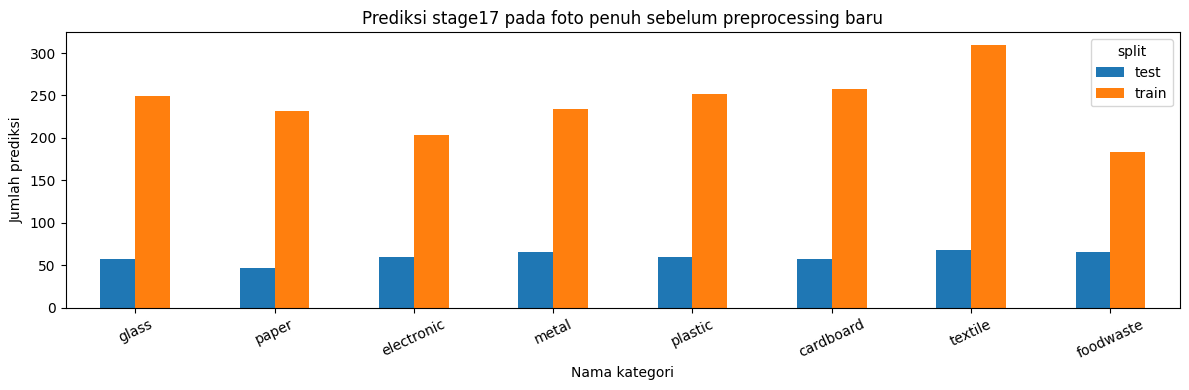

,gambar,flag_tinjau,confidence_margin_rendah,konflik_sumber_saja
split,,,,
test,480,126,25,101
train,1920,651,413,270


Flag tinjau adalah diagnostik; bukan jumlah gambar tanpa kategori atau jumlah salah terverifikasi.


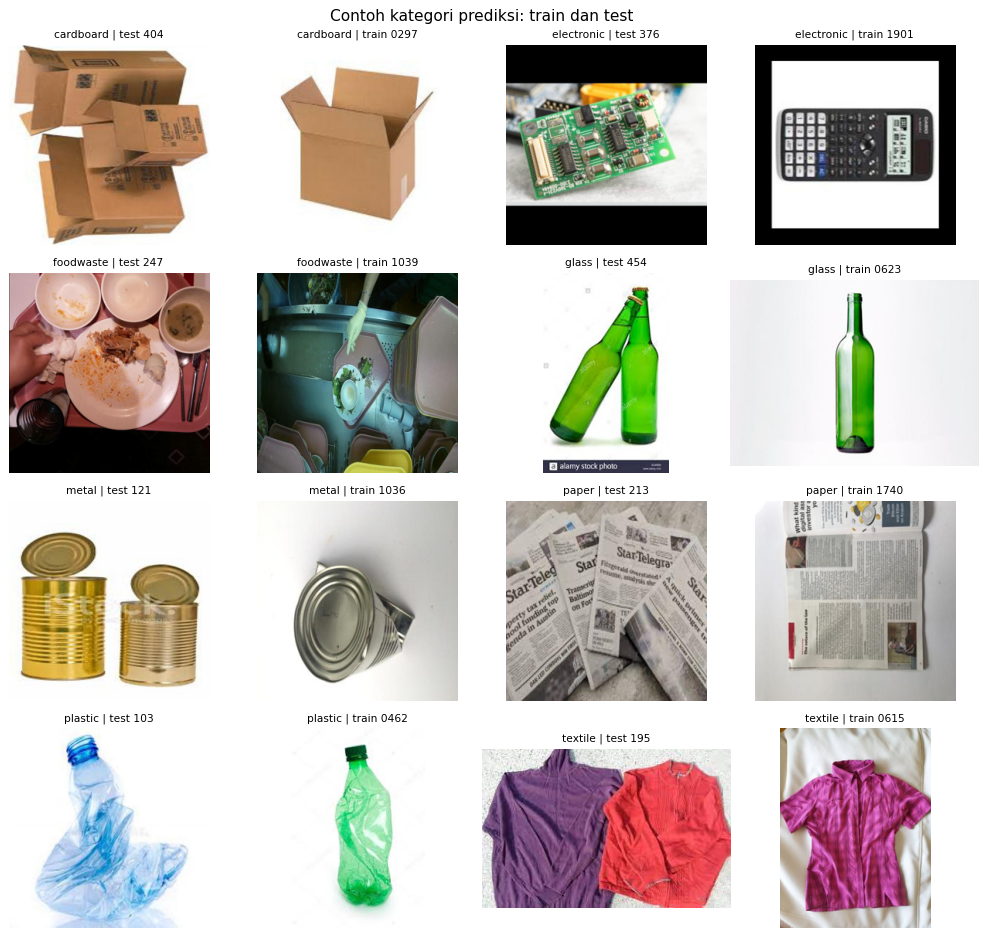

In [6]:
input_bundle = np.load(INPUT_PATH, allow_pickle=False)
input_metadata = json.loads(str(input_bundle['metadata'].item()))
input_table = pd.DataFrame({'key':input_bundle['keys'], 'source_sha256':input_bundle['source_sha256'],
                            'candidate_group':input_bundle['groups'], 'predicted_class':input_bundle['predicted_class'],
                            'uncalibrated_probability':input_bundle['confidence'], 'margin':input_bundle['margin'],
                            'needs_review':input_bundle['needs_review'], 'cnn_prior_disagrees':input_bundle['cnn_prior_disagrees']})
input_table['category_source'] = input_bundle['category_source'] if 'category_source' in input_bundle else 'historical_routing_snapshot'
input_table['category_score_kind'] = input_bundle['category_score_kind'] if 'category_score_kind' in input_bundle else 'historical_uncalibrated_program_score'

# Team decisions for the current train-only continuation. Stage-one labels below are retained as pseudo-labels.
STAGE1_RETAINED_LABELS = {
    'train:0018': 'paper', 'train:0086': 'electronic', 'train:0120': 'plastic',
    'train:0604': 'cardboard', 'train:0637': 'metal', 'train:0856': 'paper',
    'train:0890': 'paper', 'train:1129': 'glass',
}
MANUAL_LABEL_ADDITIONS = {'train:0086': 'electronic', 'train:0200': 'foodwaste', 'train:0265': 'foodwaste', 'train:1115': 'plastic'}
TRAIN_HOLDOUT_IDS = {'0079','0160','0183','0189','0225','0321','0400','1018','1142','1157','1436'}
RETIRED_SEED_IDS = {'0147','0321'}  # quota exchanges: electronic 0147 -> 0086; plastic 0321 -> 1115
assert set(STAGE1_RETAINED_LABELS.values()) <= set(CLASSES)
assert set(MANUAL_LABEL_ADDITIONS.values()) <= set(CLASSES)
for key, label in STAGE1_RETAINED_LABELS.items():
    row_mask = input_table.key.eq(key)
    assert int(row_mask.sum()) == 1 and key.startswith('train:')
    input_table.loc[row_mask, 'predicted_class'] = label
    input_table.loc[row_mask, 'category_source'] = 'stage1_train_only_pseudolabel'
    input_table.loc[row_mask, 'category_score_kind'] = 'prior_model_output_uncalibrated'
for key in RETIRED_SEED_IDS:
    row_mask = input_table.key.eq('train:' + key)
    assert int(row_mask.sum()) == 1
    input_table.loc[row_mask, 'category_source'] = 'retired_anchor_holdout'
    input_table.loc[row_mask, 'category_score_kind'] = 'not_used_for_training'
for key, label in MANUAL_LABEL_ADDITIONS.items():
    row_mask = input_table.key.eq(key)
    assert int(row_mask.sum()) == 1 and key.startswith('train:')
    input_table.loc[row_mask, 'predicted_class'] = label
    input_table.loc[row_mask, 'category_source'] = 'participant_reviewed_seed'
    input_table.loc[row_mask, 'category_score_kind'] = 'participant_reviewed_manual_label'
    input_table.loc[row_mask, 'uncalibrated_probability'] = np.nan
    input_table.loc[row_mask, 'margin'] = np.nan
    input_table.loc[row_mask, 'needs_review'] = False
    input_table.loc[row_mask, 'cnn_prior_disagrees'] = False
# Apply the confirmed plastic quota exchange and retain reviewed additions.
old_deferred = set(input_metadata.get('deferred_train_keys', []))
old_cleaning = set(input_metadata.get('train_cleaning_exclusion_keys', []))
new_holds = {'train:' + x for x in TRAIN_HOLDOUT_IDS | RETIRED_SEED_IDS}
old_deferred.discard('train:0265'); old_cleaning.discard('train:0265')
old_deferred.discard('train:1115'); old_cleaning.discard('train:1115')
old_deferred.update(new_holds); old_cleaning.update(new_holds)
input_metadata['deferred_train_keys'] = sorted(old_deferred)
input_metadata['train_cleaning_exclusion_keys'] = sorted(old_cleaning)
input_metadata['participant_train_decisions_20261112'] = {
    'stage1_retained_pseudolabels': STAGE1_RETAINED_LABELS,
    'manual_label_additions': MANUAL_LABEL_ADDITIONS,
    'train_holdout_ids': sorted(TRAIN_HOLDOUT_IDS),
    'retired_seed_ids': sorted(RETIRED_SEED_IDS),
    'plastic_quota_exchange': {'retired': 'train:0321', 'added': 'train:1115'},
}
assert len(input_table)==2400 and input_table.key.is_unique and set(input_table.key)==set(inventory.key)
matched = inventory[['key','source_sha256']].merge(input_table[['key','source_sha256']], on='key', validate='one_to_one', suffixes=('_raw','_input'))
assert matched.source_sha256_raw.eq(matched.source_sha256_input).all()
assert input_table.predicted_class.isin(CLASSES).all()
human_input = pd.DataFrame({'key':input_bundle['human_seed_keys'], 'assigned_class':input_bundle['human_seed_labels'],
                            'source_sha256':input_bundle['human_seed_source_sha256']}) if 'human_seed_keys' in input_bundle else pd.DataFrame(columns=['key','assigned_class','source_sha256'])
# Reallocate the electronic and plastic anchors; add the confirmed foodwaste/plastic labels.
retired_keys = {'train:' + x for x in RETIRED_SEED_IDS}
human_input = human_input.loc[~human_input.key.isin(retired_keys)].copy()
additions = pd.DataFrame([{'key': key, 'assigned_class': label,
    'source_sha256': input_table.loc[input_table.key.eq(key), 'source_sha256'].iloc[0]}
    for key, label in MANUAL_LABEL_ADDITIONS.items()])
human_input = pd.concat([human_input, additions], ignore_index=True)
assert human_input.key.is_unique and human_input.key.str.startswith('train:').all()
assert human_input.assigned_class.isin(CLASSES).all()
human_counts = human_input.assigned_class.value_counts().reindex(CLASSES,fill_value=0)
assert len(human_input)<=40 and human_counts.le(5).all()
if len(human_input):
    human_check = human_input.merge(input_table[['key','predicted_class','source_sha256','category_source']],on='key',validate='one_to_one',suffixes=('_human','_input'))
    assert human_check.assigned_class.eq(human_check.predicted_class).all()
    assert human_check.source_sha256_human.eq(human_check.source_sha256_input).all()
    assert human_check.category_source.eq('participant_reviewed_seed').all()
    human_input['origin']='participant_reviewed_train'
    human_input.to_csv(PROCESSED/'manual_seeds.csv',index=False)
human_keys = set(human_input.key)
deferred_keys = set(input_metadata.get('deferred_train_keys', []))
assert deferred_keys <= set(input_table.key) and all(k.startswith('train:') for k in deferred_keys)
assert not human_keys.intersection(deferred_keys)
cleaning_keys = set(input_metadata.get('train_cleaning_exclusion_keys', []))
assert cleaning_keys <= deferred_keys and not cleaning_keys.intersection(human_keys)
input_table['human_reviewed'] = input_table.key.isin(human_keys)
human_budget = human_counts.rename('acuan_manusia_per_kategori').to_frame()
human_budget['batas_per_kategori'] = 5
human_budget['sisa_kapasitas'] = 5 - human_counts
display(human_budget)
predictions = profile[['key','split','image_id']].merge(input_table.drop(columns='source_sha256'), on='key', validate='one_to_one')
baseline_validation = {'available':True,'training_repeated':False,'input_artifact':relative(INPUT_PATH),'input_sha256':digest(INPUT_PATH),'rows':2400,
                       'assignment_method':input_metadata['assignment_method'],'refinement':input_metadata.get('refinement')}
print('Metode snapshot:', input_metadata['assignment_method'])
baseline_counts = pd.crosstab(predictions.predicted_class, predictions.split).reindex(CLASSES, fill_value=0)
display(baseline_counts)
ax = baseline_counts.plot.bar(figsize=(12, 4), rot=25, title='Prediksi stage17 pada foto penuh sebelum preprocessing baru')
ax.set_xlabel('Nama kategori'); ax.set_ylabel('Jumlah prediksi'); plt.tight_layout(); publish_figure()
predictions['low_confidence_or_margin'] = predictions.uncalibrated_probability.lt(.65) | predictions.margin.lt(.25)
predictions['source_conflict_only'] = predictions.cnn_prior_disagrees & ~predictions.low_confidence_or_margin
display(predictions.groupby('split').agg(gambar=('key', 'size'), flag_tinjau=('needs_review', 'sum'),
                                       confidence_margin_rendah=('low_confidence_or_margin', 'sum'),
                                       konflik_sumber_saja=('source_conflict_only', 'sum')))
print('Flag tinjau adalah diagnostik; bukan jumlah gambar tanpa kategori atau jumlah salah terverifikasi.')
representatives = predictions.sort_values(['margin', 'key'], ascending=[False, True]).groupby(['split', 'predicted_class']).head(1)
representatives = representatives.merge(profile[['key', 'source_path']], on='key', validate='one_to_one')
gallery(representatives.sort_values(['predicted_class', 'split']), 'Contoh kategori prediksi: train dan test', limit=16,
        caption=lambda r: f"{r['predicted_class']} | {r['split']} {r['image_id']}")

## 5. Aturan preprocessing yang diterapkan

Aturan berikut **benar-benar diterapkan pada turunan data**, bukan sekadar mengurangi denominator audit. Raw tetap utuh.

| Tindakan | Sumber |
|---|---|
| Pertahankan | 0313, 0343, 1817 |
| Tidak masuk himpunan train praproses | 0134, 0298, 0545, 0963, 1028, 1043, 1465, 1890 |
| Cadangan tinjauan, terpisah dari himpunan kerja | 0376 |
| Fokus kalkulator | 0415 |
| Dua fokus: laptop dan apel | 0437 |
| Dua fokus: halaman tercetak dan kalkulator | 0951 |
| Fokus kantong merah | 1007 |
| Fokus kotak kiri bawah | 1351 |

Crop koin 0415, tas 0437, bagian tengah/kanan bawah 1351, serta bagian 1890 tidak dipakai dalam himpunan kerja saat ini. Sumber 0376 ditahan untuk tinjauan, bukan dihapus permanen.

0343 tetap menjadi anggota train yang dapat di-shuffle pada tahap pelatihan berikutnya. Belum ada sampler berbobot, penggandaan foto atau oversampling validation/test. Semua turunan mewarisi kelompok sumber induk.

Koordinat dipilih untuk fokus objek sesuai keputusan pengguna, bukan hasil watershed. Crop apel mempertahankan piksel, warna dan background sumber; pembanding test dipakai hanya untuk melihat cakupan visual. Tidak ada piksel test yang disalin ke train.

In [7]:
POLICY = {
    'version': 'class_folder_preprocessing_policy_v4',
    'scope': 'executed_preprocessing_with_unverified_algorithmic_categories',
    'drop_from_train_preprocessing': ['0134', '0298', '0545', '0963', '1028', '1043', '1465', '1890'],
    'reserve_review': ['0376'],
    'explicit_keep': ['0313', '0343', '1817'],
    'focus_crops': [
        {'parent_id': '0415', 'region': 'calculator', 'bbox': [0, 115, 235, 522]},
        {'parent_id': '0437', 'region': 'laptop', 'bbox': [0, 44, 373, 429]},
        {'parent_id': '0437', 'region': 'apple', 'bbox': [370, 292, 466, 427]},
        {'parent_id': '0951', 'region': 'printed_page', 'bbox': [143, 145, 445, 398]},
        {'parent_id': '0951', 'region': 'calculator', 'bbox': [456, 142, 640, 503]},
        {'parent_id': '1007', 'region': 'red_bag', 'bbox': [267, 63, 472, 232]},
        {'parent_id': '1351', 'region': 'lowerleft_box', 'bbox': [0, 349, 118, 484]},
    ],
    'output_size': 224, 'max_content_side': 202, 'padding_rgb': [127, 127, 127],
    'crop_origin': 'fixed object-focus coordinates; not algorithmic object detection',
    'labels_assigned_to_crops': True, 'crop_assignment_method': 'dino_crop_knn_fit_train_v1',
    'sampler': {'requested_member': '0343', 'eligible_for_future_train_shuffle': True,
                'weighted_sampler_activated': False, 'validation_test_oversampling': False},
}
drop_ids, reserve_ids = set(POLICY['drop_from_train_preprocessing']), set(POLICY['reserve_review'])
assert not drop_ids & reserve_ids
assert not set(POLICY['explicit_keep']) & (drop_ids | reserve_ids)
focus = {}
for spec in POLICY['focus_crops']: focus.setdefault(spec['parent_id'], []).append(spec)
source_ids = set(profile.loc[profile.split.eq('train'), 'image_id'])
assert (drop_ids | reserve_ids | set(focus) | set(POLICY['explicit_keep'])) <= source_ids
identity = {'sources': inventory[['key', 'source_sha256']].sort_values('key').to_dict('records'), 'policy': POLICY}
RUN_ID = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()[:12]
PROCESSED = ROOT / 'data/processed'
NOTES = PROCESSED
for path in [PROCESSED, NOTES, PROCESSED / 'train', PROCESSED / 'test',
             PROCESSED / 'crops', PROCESSED / 'review']:
    path.mkdir(parents=True, exist_ok=True)
display(pd.DataFrame(POLICY['focus_crops']))
print('Run:', RUN_ID)
print('Turunan:', relative(PROCESSED))
for name in CLASSES: (PROCESSED / 'train' / name).mkdir(parents=True, exist_ok=True)


,parent_id,region,bbox
0,0415,calculator,"[0, 115, 235, 522]"
1,0437,laptop,"[0, 44, 373, 429]"
2,0437,apple,"[370, 292, 466, 427]"
3,0951,printed_page,"[143, 145, 445, 398]"
4,0951,calculator,"[456, 142, 640, 503]"
5,1007,red_bag,"[267, 63, 472, 232]"
6,1351,lowerleft_box,"[0, 349, 118, 484]"


Run: 05e8d5e61bb0
Turunan: data/processed


## 6. Materialisasi dan pembagian delapan kategori

Train yang eligible disimpan langsung dalam glass, paper, electronic, metal, plastic, cardboard, textile dan foodwaste. Foto yang ditahan disimpan di review/excluded_train, terpisah dari folder train. Foto utuh memakai assignment algoritmis yang dibekukan. Tujuh crop baru memakai fitur DINOv2 dan voting tujuh tetangga dari referensi fit-train; source group induk tidak boleh menjadi tetangga crop. Tidak ada test yang menjadi referensi pelabelan.

Asal kategori dipisahkan pada manifest: review tim untuk acuan terbatas, atau prediksi program yang belum diverifikasi secara independen. Skor voting dan flag tinjau dicatat. Semua turunan tetap mengikuti group induk. RGB 224x224 mempertahankan rasio dengan padding netral; native crop menyimpan potongan piksel asli.

D:\lomba\NSC UB\GELAR-RASA\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,sample_id,assigned_class,category_score,needs_review
0,0415__calculator,electronic,1.000000,False
1,0437__apple,foodwaste,0.974432,False
2,0437__laptop,electronic,0.504650,True
3,0951__calculator,electronic,1.000000,False
4,0951__printed_page,paper,1.000000,False
5,1007__red_bag,plastic,0.578826,True
6,1351__lowerleft_box,cardboard,1.000000,False


Kategori crop dihitung terpisah; skor voting bukan probabilitas terkalibrasi atau Accuracy.


,komponen,jumlah_atau_perubahan
0,train asli,1920
1,tidak masuk train praproses,-8
2,cadangan tinjauan,-1
3,tambahan jumlah akibat dua crop pada0437 dan0951,2
4,train turunan,1913
5,test turunan tanpa crop,480


,foto_induk,keluaran
action,,
focus_crop,5,7
full_frame,2386,2386
not_in_train_preprocessing,8,0
reserve_review,1,0


,sample_id,parent_group,native_width,native_height,output_path,label_status
411,0415__calculator,train_geom_54816979845a9901,235,407,data/processed/train/electronic/0415__calculat...,algorithmic_category_unverified
433,0437__laptop,train_geom_2a202bde4577e759,373,385,data/processed/train/electronic/0437__laptop.png,algorithmic_category_unverified
434,0437__apple,train_geom_2a202bde4577e759,96,135,data/processed/train/foodwaste/0437__apple.png,algorithmic_category_unverified
947,0951__printed_page,train_geom_f312b20b6c7c20bb,302,253,data/processed/train/paper/0951__printed_page.png,algorithmic_category_unverified
948,0951__calculator,train_geom_f312b20b6c7c20bb,184,361,data/processed/train/electronic/0951__calculat...,algorithmic_category_unverified
1003,1007__red_bag,train_geom_d3cc5b9749f9ef97,205,169,data/processed/train/plastic/1007__red_bag.png,algorithmic_category_unverified
1345,1351__lowerleft_box,train_geom_bcc2d4400c7e60a2,118,135,data/processed/train/cardboard/1351__lowerleft...,algorithmic_category_unverified


Hasil: 1.911 induk train menjadi1.913 sampel; 8 ditahan dari train preprocessing dan1 masuk cadangan.


,sampel_train_per_kategori
assigned_class,
glass,247
paper,224
electronic,198
metal,233
plastic,249
cardboard,246
textile,308
foodwaste,181


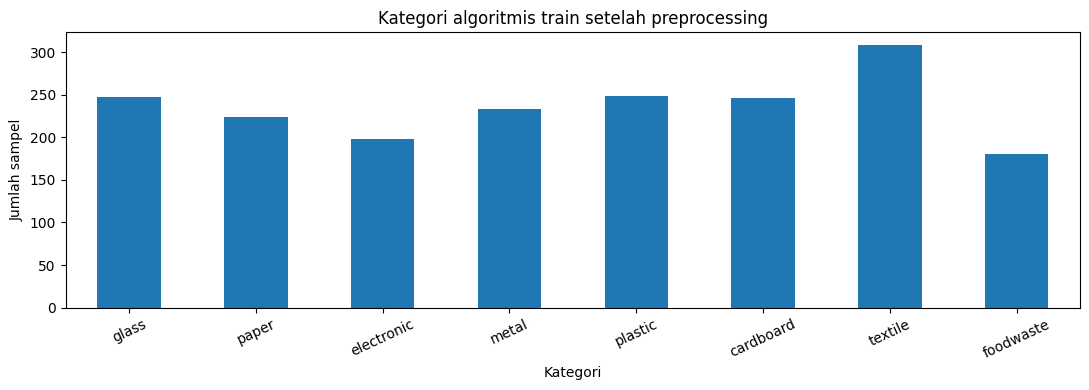

In [8]:

source_groups = dict(zip(input_table.key, input_table.candidate_group))
group_method = input_metadata.get('group_method', 'source_hash_verified_input_groups')

import torch
import timm
from huggingface_hub import hf_hub_download
from torchvision.transforms.functional import to_tensor, normalize

torch.set_num_threads(4)
model_info = input_metadata
try:
    weight_path = hf_hub_download(model_info['repository'], 'model.safetensors', revision=model_info['revision'], local_files_only=True)
except FileNotFoundError:
    weight_path = hf_hub_download(model_info['repository'], 'model.safetensors', revision=model_info['revision'])
assert digest(weight_path) == model_info['checkpoint_sha256']
vision_model = timm.create_model(model_info['model'], pretrained=True, num_classes=0, dynamic_img_size=True,
                               pretrained_cfg_overlay={'file': str(weight_path)}).eval()

def reference_letterbox(im):
    scale = 224 / max(im.size)
    dims = tuple(max(1, min(224, round(v * scale))) for v in im.size)
    canvas = Image.new('RGB', (224, 224), (124, 116, 104))
    canvas.paste(im.resize(dims, Image.Resampling.LANCZOS), ((224-dims[0])//2, (224-dims[1])//2))
    return canvas

crop_specs = sorted(POLICY['focus_crops'], key=lambda r: (int(r['parent_id']), r['region']))
native_crop_images, crop_keys = [], []
raw_lookup = inventory.set_index('key').source_path.to_dict()
for spec in crop_specs:
    im = rgb_image(resolve(raw_lookup['train:' + spec['parent_id']])).crop(tuple(spec['bbox']))
    native_crop_images.append(im)
    crop_keys.append(spec['parent_id'] + '__' + spec['region'])
batch = torch.stack([normalize(to_tensor(reference_letterbox(im)), [.485,.456,.406], [.229,.224,.225]) for im in native_crop_images])
with torch.inference_mode():
    crop_features = vision_model(batch).cpu().numpy().astype('float32')
crop_features /= np.maximum(np.linalg.norm(crop_features, axis=1, keepdims=True), 1e-12)
del vision_model, batch
reference_features = input_bundle['reference_features']
reference_labels = input_bundle['reference_labels'].astype(str).copy()
reference_groups = input_bundle['reference_groups']
reference_keys = input_bundle['reference_keys'].astype(str)
reference_index = {key: i for i, key in enumerate(reference_keys)}
for key, label in {**STAGE1_RETAINED_LABELS, **MANUAL_LABEL_ADDITIONS}.items():
    if key in reference_index:
        reference_labels[reference_index[key]] = label
assert all(key.startswith('train:') for key in reference_keys)
exclude_reference_ids = drop_ids | reserve_ids | set(focus) | {k.split(':')[1] for k in deferred_keys}
allowed_reference = np.array([key.startswith('train:') and key.split(':')[1] not in exclude_reference_ids for key in reference_keys])
assert set(reference_labels[allowed_reference]) == set(CLASSES)
crop_assignment_rows = []
for sample_id, spec, feature in zip(crop_keys, crop_specs, crop_features):
    group = source_groups['train:' + spec['parent_id']]
    allowed = allowed_reference & (reference_groups != group)
    similarities = reference_features @ feature
    similarities[~allowed] = -np.inf
    neighbors = np.argsort(-similarities, kind='stable')[:7]
    assert np.isfinite(similarities[neighbors]).all()
    weights = np.exp((similarities[neighbors] - similarities[neighbors].max()) / .07)
    votes = np.array([weights[reference_labels[neighbors] == name].sum() for name in CLASSES])
    votes /= votes.sum()
    category = CLASSES[int(votes.argmax())]
    top = np.sort(votes)
    crop_assignment_rows.append({'sample_id':sample_id, 'assigned_class':category, 'category_score':float(votes.max()),
                                 'category_margin':float(top[-1]-top[-2]), 'label_source':'dino_crop_knn_fit_train_v1',
                                 'needs_review':bool(votes.max()<.65 or top[-1]-top[-2]<.25),
                                 'neighbor_keys':reference_keys[neighbors].tolist(), 'neighbor_labels':reference_labels[neighbors].tolist()})
crop_assignments = pd.DataFrame(crop_assignment_rows).sort_values('sample_id')
crop_class_lookup = crop_assignments.set_index('sample_id').to_dict('index')
full_class_lookup = predictions.set_index('key').to_dict('index')
display(crop_assignments[['sample_id','assigned_class','category_score','needs_review']])
print('Kategori crop dihitung terpisah; skor voting bukan probabilitas terkalibrasi atau Accuracy.')

def save_png_verified(im, path):
    path = Path(path)
    if path.exists():
        with Image.open(path) as existing:
            if existing.mode == im.mode and existing.size == im.size and existing.tobytes() == im.tobytes(): return
    im.save(path, format='PNG')

def letterbox(im):
    content = ImageOps.contain(im, (POLICY['max_content_side'], POLICY['max_content_side']), method=Image.Resampling.LANCZOS)
    size = POLICY['output_size']; canvas = Image.new('RGB', (size, size), tuple(POLICY['padding_rgb']))
    x, y = (size - content.width) // 2, (size - content.height) // 2
    canvas.paste(content, (x, y))
    return canvas, (content.width, content.height, x, y)

def preprocess_parent(row):
    parent, split, key = row['image_id'], row['split'], row['key']
    im = rgb_image(resolve(row['source_path']))
    if split == 'train' and parent in drop_ids:
        return [], {'key': key, 'action': 'not_in_train_preprocessing', 'outputs': 0}
    if split == 'train' and parent in reserve_ids:
        dest = PROCESSED / 'review' / f'{parent}.png'; save_png_verified(im, dest)
        return [], {'key': key, 'action': 'reserve_review', 'outputs': 0, 'reserve_path': relative(dest)}
    specs = focus.get(parent, []) if split == 'train' else []
    if not specs: specs = [{'region': 'full_frame', 'bbox': [0, 0, im.width, im.height]}]
    outputs = []
    for spec in specs:
        box = list(map(int, spec['bbox']))
        assert 0 <= box[0] < box[2] <= im.width and 0 <= box[1] < box[3] <= im.height
        region = im.crop(tuple(box)); is_crop = spec['region'] != 'full_frame'
        sample_id = parent + ('__' + spec['region'] if is_crop else '')
        native_path = row['source_path']
        if is_crop:
            native = PROCESSED / 'crops' / f'{sample_id}.png'; save_png_verified(region, native); native_path = relative(native)
        canvas, geometry = letterbox(region)
        assignment = None
        if split == 'train':
            assignment = crop_class_lookup[sample_id] if is_crop else full_class_lookup[key]
            assigned_class = assignment['assigned_class'] if is_crop else assignment['predicted_class']
            dest = PROCESSED / ('review/excluded_train' if key in deferred_keys else 'train') / assigned_class / f'{sample_id}.png'
        else:
            assigned_class = ''; dest = PROCESSED / 'test' / f'{sample_id}.png'
        is_human = bool(split=='train' and not is_crop and assignment['human_reviewed'])
        dest.parent.mkdir(parents=True, exist_ok=True)
        save_png_verified(canvas, dest)
        outputs.append({'sample_key': split + ':' + sample_id, 'sample_id': sample_id, 'split': split,
                        'parent_key': key, 'parent_id': parent, 'parent_group': source_groups[key],
                        'source_path': row['source_path'], 'source_sha256': row['source_sha256'],
                        'region_name': spec['region'], 'is_crop': is_crop,
                        'x0': box[0], 'y0': box[1], 'x1': box[2], 'y1': box[3],
                        'native_width': region.width, 'native_height': region.height,
                        'native_pixel_sha256': hashlib.sha256(region.tobytes()).hexdigest(),
                        'native_path': native_path, 'output_path': relative(dest), 'output_sha256': digest(dest),
                        'content_width': geometry[0], 'content_height': geometry[1], 'pad_left': geometry[2], 'pad_top': geometry[3],
                        'assigned_class': assigned_class,
                        'label_source': ('dino_crop_knn_fit_train_v1' if is_crop else assignment['category_source']) if split=='train' else 'not_assigned',
                        'category_score': (assignment['category_score'] if is_crop else assignment['uncalibrated_probability']) if split=='train' else np.nan,
                        'category_score_kind': ('weighted_neighbor_share' if is_crop else assignment['category_score_kind']) if split=='train' else 'not_assigned',
                        'needs_review': bool(assignment['needs_review']) if split=='train' else False,
                        'label_status': ('participant_reviewed_train' if is_human else 'algorithmic_category_unverified') if split=='train' else 'unassigned_competition_test',
                        'human_reviewed': is_human,
                        'official_ground_truth_available': False,
                        'training_eligible': bool(split=='train' and key not in deferred_keys),
                        'deferral_reason': ('participant_noise_cleaning' if key in cleaning_keys else 'participant_hold_unresolved') if key in deferred_keys else '',
                        'training_target_created': is_human})
    return outputs, {'key': key, 'action': 'focus_crop' if specs[0]['region'] != 'full_frame' else 'full_frame', 'outputs': len(outputs)}

with ThreadPoolExecutor(MAX_WORKERS) as pool:
    transformed = list(pool.map(preprocess_parent, profile.to_dict('records')))
processed = pd.DataFrame([r for outputs, action in transformed for r in outputs])
population = pd.DataFrame([action for outputs, action in transformed])
assert processed.sample_key.is_unique
assert len(processed[processed.split.eq('train')]) == 1913
assert len(processed[processed.split.eq('test')]) == 480
assert processed[processed.split.eq('train')].parent_id.nunique() == 1911
assert set(processed.loc[processed.split.eq('test'), 'sample_id']) == set(test_order)
assert not processed.loc[processed.split.eq('test'), 'is_crop'].any()
expected_train_outputs = {(ROOT / value).resolve() for value in processed.loc[processed.split.eq('train'), 'output_path']}
managed_image_roots = [(PROCESSED / 'train').resolve(), (PROCESSED / 'review' / 'excluded_train').resolve()]
for managed_root in managed_image_roots:
    assert PROCESSED.resolve() in managed_root.parents
    if managed_root.exists():
        for stale_png in managed_root.rglob('*.png'):
            if stale_png.resolve() not in expected_train_outputs:
                stale_png.unlink()
        for empty_dir in sorted((p for p in managed_root.rglob('*') if p.is_dir()), key=lambda p: len(p.parts), reverse=True):
            if not any(empty_dir.iterdir()): empty_dir.rmdir()
processed.to_csv(PROCESSED / 'manifest.csv', index=False)
population.to_csv(PROCESSED / 'population_actions.csv', index=False)
reconciliation = pd.DataFrame([
    ['train asli', 1920], ['tidak masuk train praproses', -8], ['cadangan tinjauan', -1],
    ['tambahan jumlah akibat dua crop pada0437 dan0951', 2], ['train turunan', 1913], ['test turunan tanpa crop', 480],
], columns=['komponen', 'jumlah_atau_perubahan'])
display(reconciliation)
display(population.groupby('action').agg(foto_induk=('key', 'size'), keluaran=('outputs', 'sum')))
display(processed[processed.is_crop][['sample_id', 'parent_group', 'native_width', 'native_height', 'output_path', 'label_status']])
print('Hasil: 1.911 induk train menjadi1.913 sampel; 8 ditahan dari train preprocessing dan1 masuk cadangan.')
class_counts = processed[processed.split.eq('train') & processed.training_eligible].assigned_class.value_counts().reindex(CLASSES,fill_value=0)
display(class_counts.rename('sampel_train_per_kategori').to_frame())
ax=class_counts.plot.bar(figsize=(11,4),rot=25,title='Kategori algoritmis train setelah preprocessing')
ax.set_ylabel('Jumlah sampel'); ax.set_xlabel('Kategori'); plt.tight_layout(); publish_figure()


## 7. Penerapan webinar: split sumber, augmentasi, resolusi, dan fitur

Pembagian internal disiapkan pada tingkat group sebelum augmentasi. Karena label kategori belum disahkan, split ini adalah **draft berbasis sumber**, belum stratifikasi final per kategori. Competition test480 terpisah dari internal holdout. Ini persiapan data, bukan skor validasi model.

Augmentasi hanya dipreview dari partisi train. Perbandingan160/192/224 menunjukkan dampak transformasi dan biaya, bukan menentukan ukuran terbaik berdasarkan Accuracy yang belum diukur. HOG dan warna dihitung tanpa classifier; scaler/PCA untuk visualisasi hanya fit pada partisi train.

,sampel,induk
draft_partition,,
competition_test,480,480
internal_holdout,196,196
train,1335,1333
validation,382,382


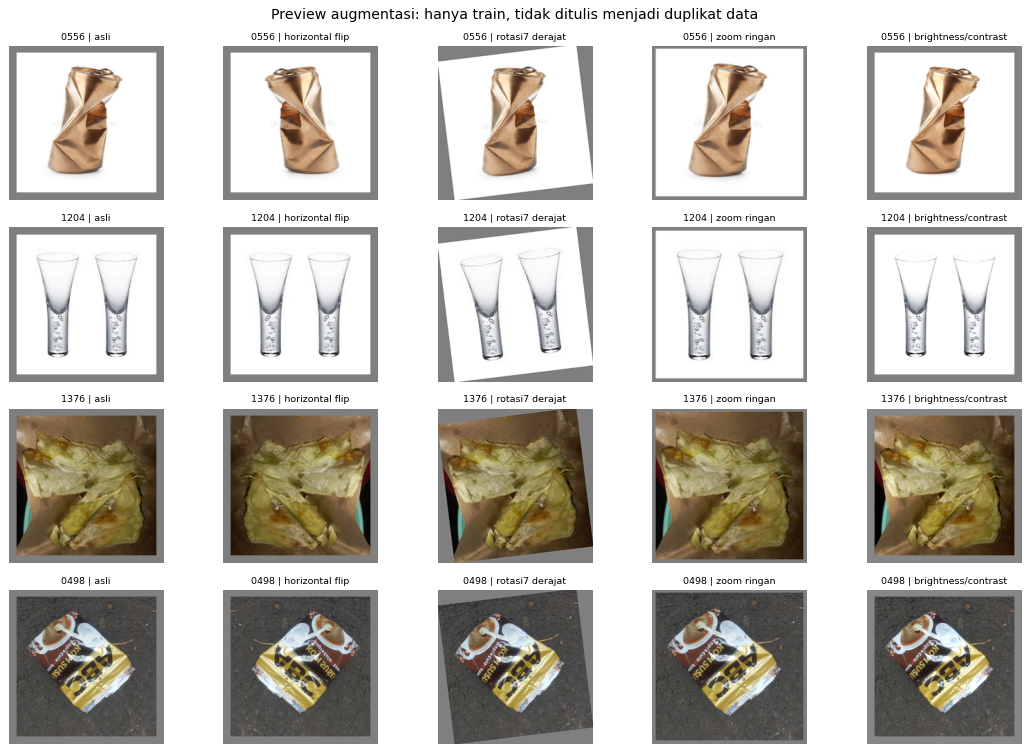

Augmentasi validation/test: tidak diterapkan. Sampler berbobot: belum diaktifkan.


In [9]:
from sklearn.model_selection import GroupShuffleSplit
from PIL import ImageEnhance

train_views = processed[processed.split.eq('train')].copy().reset_index(drop=True)
first = GroupShuffleSplit(n_splits=1, test_size=.30, random_state=SEED)
fit_positions, remaining = next(first.split(train_views, groups=train_views.parent_group))
remainder = train_views.iloc[remaining]
second = GroupShuffleSplit(n_splits=1, test_size=1/3, random_state=SEED + 1)
val_local, hold_local = next(second.split(remainder, groups=remainder.parent_group))
train_views['draft_partition'] = 'train'
train_views.loc[remaining[val_local], 'draft_partition'] = 'validation'
train_views.loc[remaining[hold_local], 'draft_partition'] = 'internal_holdout'
partition_map = dict(zip(train_views.sample_key, train_views.draft_partition))
processed['draft_partition'] = processed.sample_key.map(partition_map).fillna('competition_test')
assert train_views.groupby('parent_group').draft_partition.nunique().max() == 1
assert processed.groupby('parent_key').draft_partition.nunique().max() == 1
group_sets = {name: set(g.parent_group) for name, g in train_views.groupby('draft_partition')}
assert not group_sets['train'] & group_sets['validation']
assert not group_sets['train'] & group_sets['internal_holdout']
assert not group_sets['validation'] & group_sets['internal_holdout']
processed.to_csv(PROCESSED / 'manifest.csv', index=False)
display(processed.groupby('draft_partition').agg(sampel=('sample_key', 'size'), induk=('parent_key', 'nunique')))

augmentation_examples = processed[processed.draft_partition.eq('train')].sample(4, random_state=SEED)
fig, axes = plt.subplots(4, 5, figsize=(13, 9), dpi=85)
for row_axes, row in zip(axes, augmentation_examples.to_dict('records')):
    im = rgb_image(resolve(row['output_path']))
    zoom = im.crop((6, 6, 218, 218)).resize((224, 224), Image.Resampling.LANCZOS)
    light = ImageEnhance.Contrast(ImageEnhance.Brightness(im).enhance(1.05)).enhance(1.05)
    views = [im, ImageOps.mirror(im), im.rotate(7, resample=Image.Resampling.BICUBIC, fillcolor=(127, 127, 127)), zoom, light]
    for ax, view, name in zip(row_axes, views, ['asli', 'horizontal flip', 'rotasi7 derajat', 'zoom ringan', 'brightness/contrast']):
        ax.imshow(view); ax.set_title(row['sample_id'] + ' | ' + name, fontsize=8); ax.axis('off')
fig.suptitle('Preview augmentasi: hanya train, tidak ditulis menjadi duplikat data'); fig.tight_layout(); publish_figure()
print('Augmentasi validation/test: tidak diterapkan. Sampler berbobot: belum diaktifkan.')

,sample_id,input_dtype,tensor_dtype,minimum,maximum
0,0001,uint8,float32,0.000000,1.00000
1,0002,uint8,float32,0.000000,1.00000
2,0003,uint8,float32,0.082353,0.94902
3,0004,uint8,float32,0.000000,1.00000
4,0005,uint8,float32,0.000000,1.00000
5,0006,uint8,float32,0.000000,1.00000


Normalisasi backbone tertentu akan dipilih saat modeling; tidak ada normalisasi ganda di sini.


roundtrip_ssim         resize_ms        
                      mean  median      mean  median
target_size                                         
160                 0.9692  0.9850    5.5231  2.9000
192                 0.9832  0.9919    5.8885  3.2025
224                 0.9908  0.9952    6.2613  3.5123

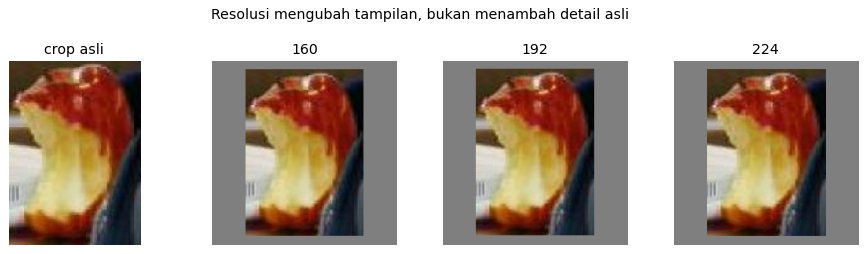

In [10]:
from skimage.metrics import structural_similarity

normalization_checks = []
for row in processed.head(6).to_dict('records'):
    uint8 = np.asarray(rgb_image(resolve(row['output_path'])))
    tensor = np.transpose(uint8.astype(np.float32) / 255, (2, 0, 1))
    assert uint8.dtype == np.uint8 and tensor.dtype == np.float32
    assert tensor.shape == (3, 224, 224) and 0 <= tensor.min() <= tensor.max() <= 1
    normalization_checks.append({'sample_id': row['sample_id'], 'input_dtype': str(uint8.dtype),
                                 'tensor_dtype': str(tensor.dtype), 'minimum': float(tensor.min()), 'maximum': float(tensor.max())})
display(pd.DataFrame(normalization_checks))
print('Normalisasi backbone tertentu akan dipilih saat modeling; tidak ada normalisasi ganda di sini.')

resolution_rows = []
resolution_sources = pd.concat([processed[processed.is_crop], processed[(processed.split.eq('train')) & ~processed.is_crop].sample(5, random_state=SEED)])
for row in resolution_sources.to_dict('records'):
    im = rgb_image(resolve(row['native_path']))
    reference = ImageOps.contain(im, (256, 256), method=Image.Resampling.LANCZOS)
    gray = np.asarray(reference.convert('L'))
    for size in [160, 192, 224]:
        started = time.perf_counter()
        small = ImageOps.contain(im, (round(.90 * size), round(.90 * size)), method=Image.Resampling.LANCZOS)
        restored = small.resize(reference.size, Image.Resampling.LANCZOS)
        elapsed_ms = 1000 * (time.perf_counter() - started)
        ssim = structural_similarity(gray, np.asarray(restored.convert('L')), data_range=255)
        resolution_rows.append({'sample_id': row['sample_id'], 'target_size': size, 'roundtrip_ssim': float(ssim), 'resize_ms': elapsed_ms})
resolution_audit = pd.DataFrame(resolution_rows)
display(resolution_audit.groupby('target_size')[['roundtrip_ssim', 'resize_ms']].agg(['mean', 'median']).round(4))
apple = processed[processed.region_name.eq('apple')].iloc[0]
im = rgb_image(resolve(apple.native_path))
fig, axes = plt.subplots(1, 4, figsize=(11, 3), dpi=85)
axes[0].imshow(im); axes[0].set_title('crop asli')
for ax, size in zip(axes[1:], [160, 192, 224]):
    content = ImageOps.contain(im, (round(.90 * size), round(.90 * size)), method=Image.Resampling.LANCZOS)
    canvas = Image.new('RGB', (size, size), (127, 127, 127))
    canvas.paste(content, ((size-content.width)//2, (size-content.height)//2)); ax.imshow(canvas); ax.set_title(str(size))
for ax in axes: ax.axis('off')
fig.suptitle('Resolusi mengubah tampilan, bukan menambah detail asli'); fig.tight_layout(); publish_figure()

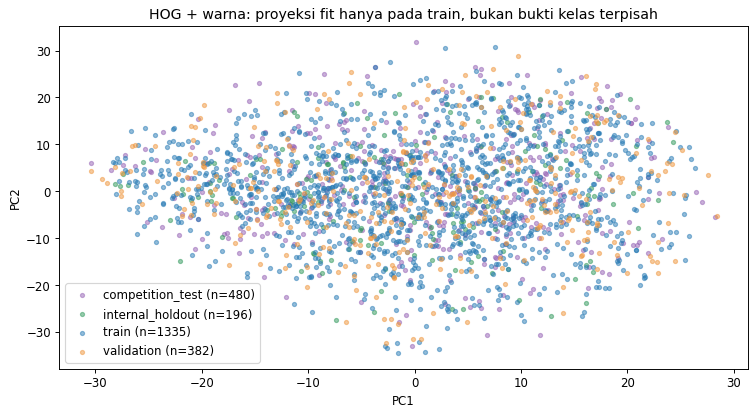

hog_dimensions                                                               1764
color_dimensions                                                               48
total_dimensions                                                             1812
scaler_and_pca_fit_partition                                                train
fit_samples                                                                  1335
fit_keys_sha256                 a9b384db808f53e85e0981697f0d37f0a35a872389658a...
classifier_trained                                                          False
category_targets_used                                                       False
Name: persiapan fitur webinar, dtype: object

In [11]:
from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from threadpoolctl import threadpool_limits

def handcrafted(row):
    im = rgb_image(resolve(row['output_path'])).resize((64, 64), Image.Resampling.LANCZOS)
    gray = np.asarray(im.convert('L'), dtype=np.float32) / 255
    gradients = hog(gray, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), block_norm='L2-Hys', feature_vector=True)
    hsv = np.asarray(im.convert('HSV'))
    colors = np.concatenate([np.histogram(hsv[:, :, channel], bins=16, range=(0, 256))[0] / (64 * 64) for channel in range(3)])
    return np.concatenate([gradients, colors]).astype(np.float32)

with ThreadPoolExecutor(MAX_WORKERS) as pool:
    handcrafted_features = np.stack(list(pool.map(handcrafted, processed.to_dict('records'))))
assert handcrafted_features.shape == (2393, 1812) and np.isfinite(handcrafted_features).all()
np.savez_compressed(PROCESSED / 'features.npz', keys=processed.sample_key.to_numpy(str), features=handcrafted_features,
                    partitions=processed.draft_partition.to_numpy(str))
fit_mask = processed.draft_partition.eq('train').to_numpy()
with threadpool_limits(limits=4):
    descriptor_scaler = StandardScaler().fit(handcrafted_features[fit_mask])
    scaled = descriptor_scaler.transform(handcrafted_features)
    descriptor_projection = PCA(n_components=2, svd_solver='randomized', random_state=SEED).fit(scaled[fit_mask])
    projection = descriptor_projection.transform(scaled)
assert int(descriptor_scaler.n_samples_seen_) == int(fit_mask.sum())
assert descriptor_projection.n_samples_ == int(fit_mask.sum())
feature_projection = processed[['sample_key', 'parent_group', 'draft_partition']].copy()
feature_projection['PC1'], feature_projection['PC2'] = projection[:, 0], projection[:, 1]
fig, ax = plt.subplots(figsize=(9, 5), dpi=85)
palette = {'train':'#287bb5', 'validation':'#ef963d', 'internal_holdout':'#30995c', 'competition_test':'#9562b4'}
for partition, group in feature_projection.groupby('draft_partition'):
    ax.scatter(group.PC1, group.PC2, s=12, alpha=.5, color=palette[partition], label=f'{partition} (n={len(group)})')
ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_title('HOG + warna: proyeksi fit hanya pada train, bukan bukti kelas terpisah')
ax.legend(); fig.tight_layout(); publish_figure()
feature_recipe = {'hog_dimensions':1764, 'color_dimensions':48, 'total_dimensions':1812,
                  'scaler_and_pca_fit_partition':'train', 'fit_samples':int(fit_mask.sum()),
                  'fit_keys_sha256':hashlib.sha256('\n'.join(sorted(processed.loc[fit_mask, 'sample_key'])).encode()).hexdigest(),
                  'classifier_trained':False, 'category_targets_used':False}
display(pd.Series(feature_recipe, name='persiapan fitur webinar'))

## 8. Preview sebelum dan sesudah preprocessing

Periksa ketepatan fokus objek dan detail yang masih tersedia. Resize tidak menciptakan detail baru dari crop kecil. Crop 1351 masih menunjukkan sebagian konteks; nama region hanya deskripsi fokus, bukan kategori training yang telah ditetapkan.

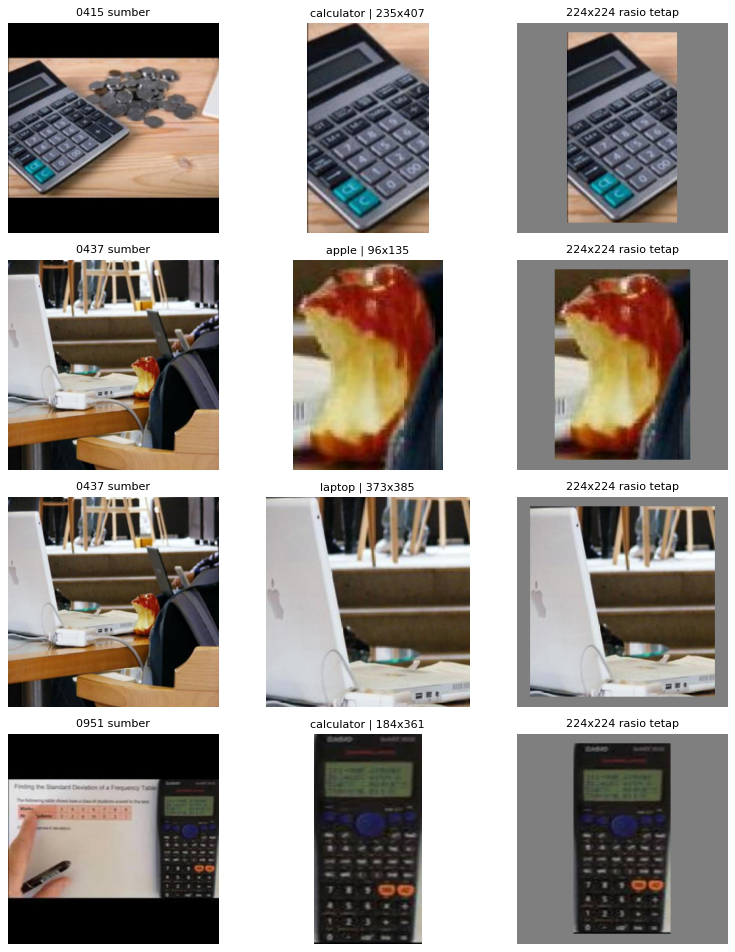

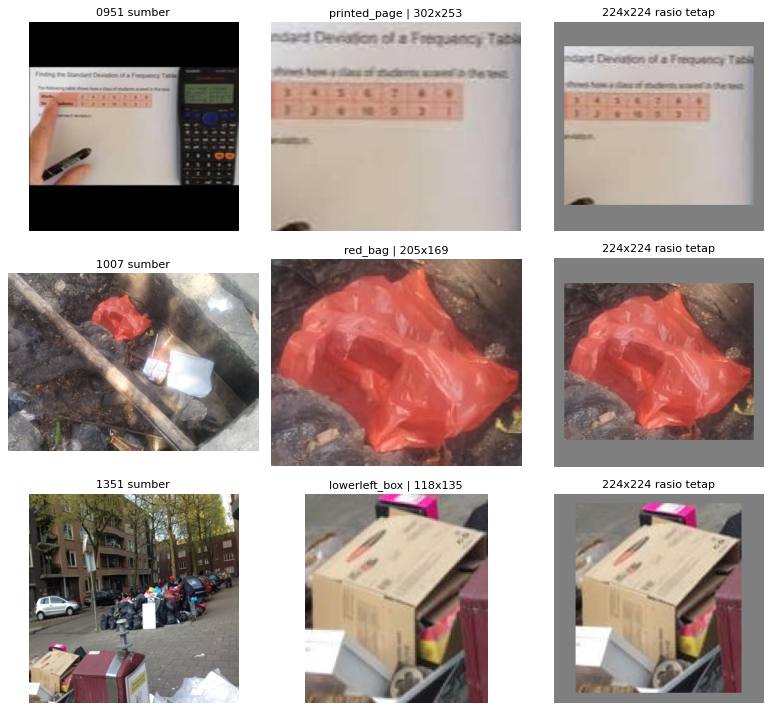

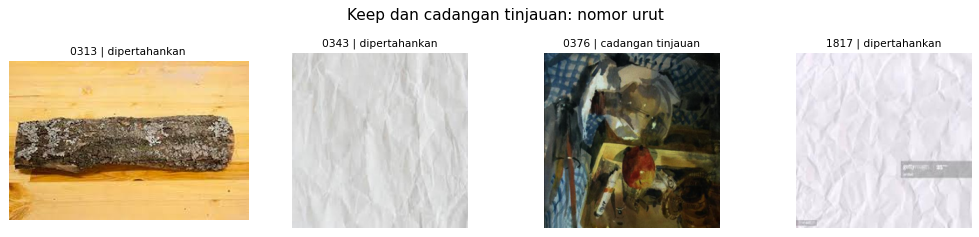

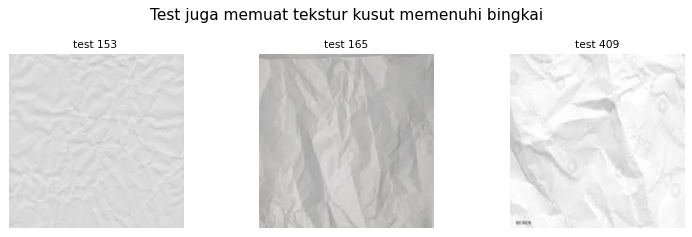

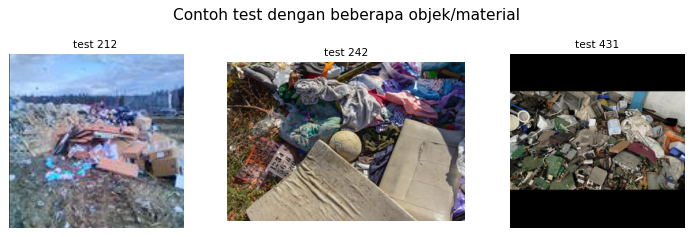

In [12]:
crop_rows = processed[processed.is_crop].sort_values(['parent_id', 'sample_id'])
for start in range(0, len(crop_rows), 4):
    shown = crop_rows.iloc[start:start+4]
    fig, axes = plt.subplots(len(shown), 3, figsize=(10, 3 * len(shown)), squeeze=False, dpi=80)
    for row_axes, row in zip(axes, shown.to_dict('records')):
        paths = [row['source_path'], row['native_path'], row['output_path']]
        titles = [row['parent_id'] + ' sumber', row['region_name'] + f" | {row['native_width']}x{row['native_height']}", '224x224 rasio tetap']
        for ax, path, title in zip(row_axes, paths, titles):
            im = rgb_image(resolve(path)); im.thumbnail((400, 320)); ax.imshow(im); ax.set_title(title, fontsize=10); ax.axis('off')
    fig.tight_layout(); publish_figure()

important = profile[profile.split.eq('train') & profile.image_id.isin(['0313', '0343', '0376', '1817'])].sort_values('image_id')
gallery(important, 'Keep dan cadangan tinjauan: nomor urut', limit=4,
        caption=lambda r: r['image_id'] + (' | cadangan tinjauan' if r['image_id'] in reserve_ids else ' | dipertahankan'))
texture_test = profile[profile.split.eq('test') & profile.image_id.isin(['153', '165', '409'])].sort_values('image_id')
gallery(texture_test, 'Test juga memuat tekstur kusut memenuhi bingkai', limit=3, columns=3)
busy_test = profile[profile.split.eq('test') & profile.image_id.isin(['212', '242', '431'])].sort_values('image_id')
gallery(busy_test, 'Contoh test dengan beberapa objek/material', limit=3, columns=3)

## 9. Validasi hasil preprocessing dan cakupan test

Semua output dicek mode/ukuran dan hash byte. Native crop dibandingkan persis dengan potongan parent RGB yang sudah diorientasi. Turunan satu parent harus mempunyai group yang sama. Hash seluruh sumber diperiksa ulang setelah penulisan output.

Keputusan per gambar pada tahap ini bukan ukuran Accuracy. 

In [13]:
for held in processed[processed.split.eq('train') & ~processed.training_eligible].itertuples():
    legacy = PROCESSED / 'train' / held.assigned_class / f'{held.sample_id}.png'
    if legacy.is_file(): legacy.unlink()

expected_png_paths = {resolve(path).resolve() for path in processed.output_path}
for split in ['train', 'test', 'review/excluded_train']:
    for png in (PROCESSED / split).rglob('*.png'):
        if png.resolve() not in expected_png_paths:
            png.unlink()

def verify_output(row):
    path = resolve(row['output_path'])
    with Image.open(path) as im:
        assert im.mode == 'RGB' and im.size == (224, 224)
        im.load()
    assert digest(path) == row['output_sha256']
    if row['is_crop']:
        original = rgb_image(resolve(row['source_path']))
        expected = original.crop(tuple(row[c] for c in ['x0', 'y0', 'x1', 'y1']))
        actual = rgb_image(resolve(row['native_path']))
        assert expected.size == actual.size and expected.tobytes() == actual.tobytes()
    return True

with ThreadPoolExecutor(MAX_WORKERS) as pool:
    assert all(pool.map(verify_output, processed.to_dict('records')))
    source_hashes_after = list(pool.map(lambda p: digest(resolve(p)), inventory.source_path))
assert source_hashes_after == inventory.source_sha256.tolist()
assert processed.groupby('parent_key').parent_group.nunique().max() == 1
assert not set(processed.loc[processed.split.eq('train'), 'parent_id']) & (drop_ids | reserve_ids)
assert set(POLICY['explicit_keep']) <= set(processed.loc[processed.split.eq('train'), 'parent_id'])
assert set(processed.loc[processed.split.eq('train') & processed.parent_id.eq('0437'), 'region_name']) == {'laptop', 'apple'}
assert set(processed.loc[processed.split.eq('train') & processed.parent_id.eq('0951'), 'region_name']) == {'printed_page', 'calculator'}
actual_outputs = {p.resolve() for split in ['train', 'test', 'review/excluded_train'] for p in (PROCESSED / split).rglob('*.png')}
assert actual_outputs == {resolve(p).resolve() for p in processed.output_path}
sampler_plan = processed[processed.split.eq('train')][['sample_id', 'parent_id', 'parent_group']].copy()
sampler_plan['eligible_for_future_shuffle'] = sampler_plan.sample_id.map(dict(zip(processed.sample_id, processed.draft_partition))).eq('train')
sampler_plan['explicit_keep_request'] = sampler_plan.parent_id.eq('0343')
sampler_plan['weighted_sampler_activated'] = False
sampler_plan.to_csv(PROCESSED / 'future_sampler_members.csv', index=False)


assert {p.name for p in (PROCESSED/'train').iterdir() if p.is_dir()} == set(CLASSES)
assert not list((PROCESSED/'train').glob('*.png'))
assert processed[processed.split.eq('train')].assigned_class.isin(CLASSES).all()
assert all(Path(row.output_path).parent.name == row.assigned_class for row in processed[processed.split.eq('train')].itertuples())
assert all(Path(row.output_path).parts[2] == ('train' if row.training_eligible else 'review') for row in processed[processed.split.eq('train')].itertuples())
parts = ['<!doctype html><html lang="id"><meta charset="utf-8"><title>Seluruh test</title>',
         '<style>body{font:16px system-ui;margin:24px}figure{display:inline-block;width:190px;margin:10px}img{width:180px;height:180px;object-fit:contain}</style>',
         '<h1>Seluruh 480 test, nomor menaik</h1>']
for row in profile[profile.split.eq('test')].sort_values('image_id').to_dict('records'):
    path=html.escape(os.path.relpath(resolve(row['source_path']),FIGURES).replace('\\','/'),quote=True)
    parts.append(f'<figure><img src="{path}" loading="lazy"><figcaption>{row["image_id"]} | {row["width"]}x{row["height"]}</figcaption></figure>')
(FIGURES/'all_test_gallery.html').write_text('\n'.join(parts)+'</html>',encoding='utf-8')
summary = {'stage':'EDA_preprocessing_with_algorithmic_folder_assignments','run_id':RUN_ID,
           'raw_train':1920,'raw_test':480,'working_train_unique_parents':1911,'working_train_samples':1913,
           'working_test_samples':480,'native_crop_samples':7,'reserved_sources':1,'excluded_sources':8,
           'train_class_counts':class_counts.to_dict(),'crop_assignment_rows':crop_assignment_rows,
           'crop_reference_fit_train_only':True,'crop_parent_group_excluded':True,
           'input_snapshot':baseline_validation,'feature_recipe':feature_recipe,'figures':figure_exports,
           'manual_train_seed_count':len(human_input),'manual_train_seed_class_counts':human_counts.to_dict(),
           'deferred_train_keys':sorted(deferred_keys),'train_cleaning_exclusion_keys':sorted(cleaning_keys),
           'training_eligible_train_samples':int((processed.split.eq('train')&processed.training_eligible).sum()),
           'deferred_train_samples':int((processed.split.eq('train')&~processed.training_eligible).sum()),
           'source_files_changed':False,'all_output_images_verified':True,'all_native_crops_exact_parent_subsets':True,
           'same_parent_same_group':True,'draft_split_prepared':True,'draft_split_stratified':False,
           'group_method':group_method,'classifier_training_executed':False,'semantic_accuracy':None,
           'submission_created':False,'weighted_sampler_activated':False,'seconds':time.time()-STARTED}
(PROCESSED/'provenance.json').write_text(json.dumps({'policy':POLICY,'summary':summary},indent=2),encoding='utf-8')
display(class_counts.rename('train_per_kategori').to_frame())
display(processed.groupby(['split','draft_partition']).size().rename('sampel'))
display(pd.Series({k:v for k,v in summary.items() if not isinstance(v,(dict,list))},name='validasi_preprocessing'))
gallery_link=os.path.relpath(FIGURES/'all_test_gallery.html',ROOT/'final-submit').replace('\\','/')
display(HTML(f'<a href="{html.escape(gallery_link,quote=True)}">Galeri seluruh test</a>'))
print('Seluruh data processed dibuat dan diverifikasi oleh notebook ini.')


,train_per_kategori
assigned_class,
glass,247
paper,224
electronic,198
metal,233
plastic,249
cardboard,246
textile,308
foodwaste,181


split  draft_partition 
test   competition_test     480
train  internal_holdout     196
       train               1335
       validation           382
Name: sampel, dtype: int64

stage                                    EDA_preprocessing_with_algorithmic_folder_assi...
run_id                                                                        05e8d5e61bb0
raw_train                                                                             1920
raw_test                                                                               480
working_train_unique_parents                                                          1911
working_train_samples                                                                 1913
working_test_samples                                                                   480
native_crop_samples                                                                      7
reserved_sources                                                                         1
excluded_sources                                                                         8
crop_reference_fit_train_only                                                         True

Seluruh data processed dibuat dan diverifikasi oleh notebook ini.


## 10. Distribusi akhir dan kemiripan train–test setelah preprocessing

Distribusi berikut hanya menghitung foto train yang eligible. Hitung pula induk dan kelompok sumber unik, karena crop atau foto hampir sama tidak menambah bukti independen. Kategori train adalah assignment algoritmis yang belum menjadi ground truth resmi.

Kemiripan dihitung dari PNG 224×224 hasil preprocessing: gabungan HOG dan histogram HSV, pHash 64 bit, serta SSIM abu-abu 64×64 pada pasangan pHash terdekat. Seluruh train eligible menjadi kandidat referensi; test hanya menjadi query tanpa label. Skor descriptor, jarak pHash dan SSIM adalah indikator visual, **bukan** probabilitas kelas atau bukti bahwa dua gambar berasal dari objek yang sama. Analisis test ini tidak dipakai untuk fit, pemilihan label, cleaning, atau tuning model.

,images,source_images,source_groups,share_percent
assigned_class,,,,
glass,247,247,238,13.1
paper,224,224,207,11.9
electronic,198,198,189,10.5
metal,233,233,224,12.4
plastic,249,249,234,13.2
cardboard,246,246,225,13.0
textile,308,308,284,16.3
foodwaste,181,181,165,9.6


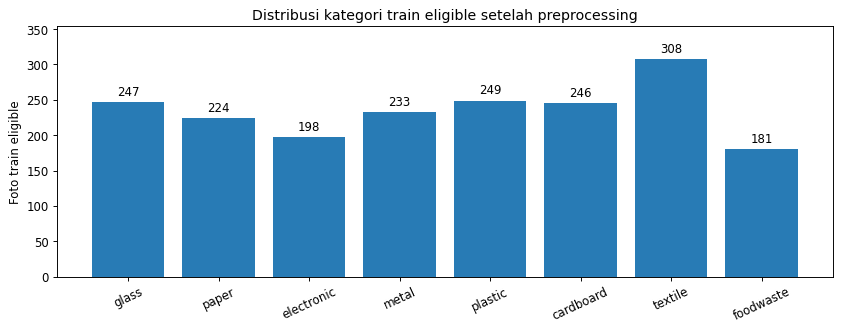

train_eligible                  1886.000000
test_queries                     480.000000
same_processed_sha256              3.000000
phash_distance_at_most_6          20.000000
phash_distance_at_most_12        105.000000
descriptor_similarity_median       0.819945
descriptor_similarity_min          0.672199
Name: diagnostik_kemiripan, dtype: float64

,test_id,descriptor_train_sample,descriptor_train_id,descriptor_train_class,descriptor_similarity,phash_train_sample,phash_train_id,phash_train_class,phash_distance_64,ssim64_phash_pair,same_processed_sha256
16,017,1046,1046,textile,1.000,1046,1046,textile,0,1.000,True
41,042,1821,1821,foodwaste,1.000,1821,1821,foodwaste,0,1.000,True
66,067,0271,0271,foodwaste,0.998,0271,0271,foodwaste,0,1.000,False
120,121,1754,1754,metal,0.998,1754,1754,metal,0,1.000,False
200,201,1135,1135,textile,1.000,1135,1135,textile,0,1.000,True
302,303,1039,1039,foodwaste,1.000,1039,1039,foodwaste,0,1.000,False
376,377,1502,1502,foodwaste,0.998,1502,1502,foodwaste,0,1.000,False
173,174,0210,0210,metal,0.996,0210,0210,metal,0,0.999,False
228,229,1016,1016,metal,0.996,1016,1016,metal,0,0.999,False
247,248,1797,1797,metal,0.996,1797,1797,metal,0,0.999,False


,test_id,descriptor_train_sample,descriptor_train_id,descriptor_train_class,descriptor_similarity,phash_train_sample,phash_train_id,phash_train_class,phash_distance_64,ssim64_phash_pair,same_processed_sha256
331,332,0712,0712,metal,0.672,1823,1823,glass,12,0.329,False
224,225,0966,0966,paper,0.694,1026,1026,paper,12,0.200,False
203,204,0238,0238,foodwaste,0.703,1176,1176,cardboard,16,0.391,False
31,032,1004,1004,cardboard,0.717,1778,1778,metal,16,0.149,False
341,342,0421,0421,cardboard,0.719,0063,0063,cardboard,14,0.418,False
257,258,1570,1570,cardboard,0.722,0262,0262,foodwaste,18,0.106,False
0,001,0951__calculator,0951,electronic,0.723,0351,0351,textile,18,0.051,False
131,132,1275,1275,textile,0.728,1826,1826,plastic,16,0.361,False
218,219,0464,0464,paper,0.730,0616,0616,glass,16,0.097,False
75,076,1006,1006,glass,0.730,0090,0090,paper,16,0.600,False


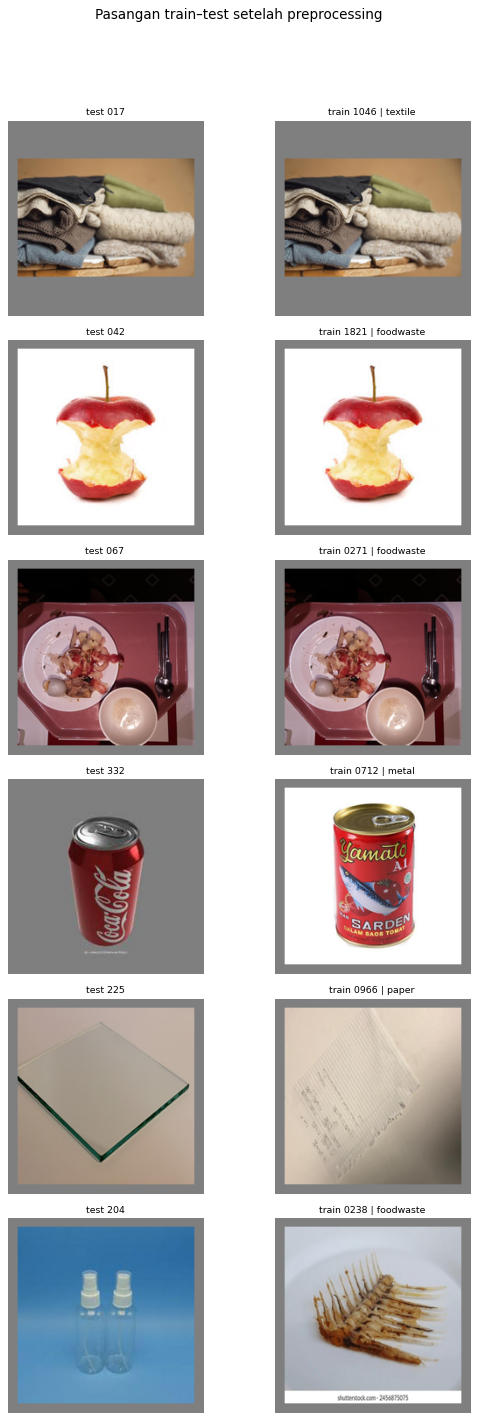

18895

In [14]:
from sklearn.preprocessing import normalize

eligible_mask = processed.split.eq('train') & processed.training_eligible
test_mask = processed.split.eq('test')
train_idx = np.flatnonzero(eligible_mask.to_numpy())
test_idx = np.flatnonzero(test_mask.to_numpy())
assert len(train_idx) == 1886 and len(test_idx) == 480
assert len(handcrafted_features) == len(processed) and handcrafted_features.shape[1] == 1812
eligible = processed.iloc[train_idx].reset_index(drop=True)
queries = processed.iloc[test_idx].reset_index(drop=True)
distribution = (eligible.groupby('assigned_class')
                .agg(images=('sample_id','size'), source_images=('parent_key','nunique'),
                     source_groups=('parent_group','nunique'))
                .reindex(CLASSES).fillna(0).astype(int))
distribution['share_percent'] = (100 * distribution.images / len(eligible)).round(1)
display(distribution)
fig, ax = plt.subplots(figsize=(10,4), dpi=85)
bars = ax.bar(distribution.index, distribution.images, color='#287bb5')
ax.bar_label(bars, padding=3)
ax.set_ylim(0, distribution.images.max() * 1.15)
ax.set_ylabel('Foto train eligible')
ax.set_title('Distribusi kategori train eligible setelah preprocessing')
ax.tick_params(axis='x', rotation=25)
fig.tight_layout()
publish_figure()

# Dua komponen descriptor dinormalisasi terpisah supaya warna tidak tenggelam oleh HOG.
with threadpool_limits(limits=4):
    train_hog = normalize(handcrafted_features[train_idx, :1764])
    test_hog = normalize(handcrafted_features[test_idx, :1764])
    train_color = normalize(handcrafted_features[train_idx, 1764:])
    test_color = normalize(handcrafted_features[test_idx, 1764:])
    descriptor_similarity = .7 * (test_hog @ train_hog.T) + .3 * (test_color @ train_color.T)
descriptor_neighbor = descriptor_similarity.argmax(axis=1)
descriptor_score = descriptor_similarity[np.arange(len(queries)), descriptor_neighbor]

def processed_signature(path):
    with Image.open(resolve(path)) as source:
        rgb = source.convert('RGB')
        hash_bytes = np.frombuffer(bytes.fromhex(str(imagehash.phash(rgb))), dtype=np.uint8).copy()
        gray = np.asarray(rgb.convert('L').resize((64,64), Image.Resampling.BILINEAR), dtype=np.uint8)
    return hash_bytes, gray

with ThreadPoolExecutor(MAX_WORKERS) as pool:
    signatures = list(pool.map(processed_signature, processed.output_path))
phash_bytes = np.stack([item[0] for item in signatures])
gray64 = np.stack([item[1] for item in signatures])
nearest_phash = np.empty(len(queries), dtype=int)
phash_distance = np.empty(len(queries), dtype=int)
for start in range(0, len(queries), 32):
    stop = min(start + 32, len(queries))
    differences = np.bitwise_xor(phash_bytes[test_idx[start:stop], None, :],
                                 phash_bytes[None, train_idx, :])
    distances = np.unpackbits(differences, axis=2).sum(axis=2)
    closest = distances.argmin(axis=1)
    nearest_phash[start:stop] = closest
    phash_distance[start:stop] = distances[np.arange(stop-start), closest]

ssim64 = [structural_similarity(gray64[test_idx[i]], gray64[train_idx[j]], data_range=255)
          for i,j in enumerate(nearest_phash)]
nearest_descriptor_rows = eligible.iloc[descriptor_neighbor].reset_index(drop=True)
nearest_phash_rows = eligible.iloc[nearest_phash].reset_index(drop=True)
similarity_audit = pd.DataFrame({
    'test_id': queries.sample_id.to_numpy(),
    'descriptor_train_sample': nearest_descriptor_rows.sample_id.to_numpy(),
    'descriptor_train_id': nearest_descriptor_rows.parent_id.to_numpy(),
    'descriptor_train_class': nearest_descriptor_rows.assigned_class.to_numpy(),
    'descriptor_similarity': np.round(descriptor_score, 3),
    'phash_train_sample': nearest_phash_rows.sample_id.to_numpy(),
    'phash_train_id': nearest_phash_rows.parent_id.to_numpy(),
    'phash_train_class': nearest_phash_rows.assigned_class.to_numpy(),
    'phash_distance_64': phash_distance,
    'ssim64_phash_pair': np.round(ssim64, 3),
    'same_processed_sha256': queries.output_sha256.isin(set(eligible.output_sha256)).to_numpy(),
})
assert similarity_audit.test_id.is_unique and len(similarity_audit) == 480
display(pd.Series({'train_eligible':len(eligible), 'test_queries':len(queries),
                   'same_processed_sha256':int(similarity_audit.same_processed_sha256.sum()),
                   'phash_distance_at_most_6':int((phash_distance<=6).sum()),
                   'phash_distance_at_most_12':int((phash_distance<=12).sum()),
                   'descriptor_similarity_median':float(np.median(descriptor_score)),
                   'descriptor_similarity_min':float(descriptor_score.min())},
                  name='diagnostik_kemiripan'))
display(similarity_audit.sort_values(['phash_distance_64','ssim64_phash_pair'],
                                     ascending=[True,False]).head(12))
display(similarity_audit.sort_values('descriptor_similarity').head(12))

near = similarity_audit.sort_values(['phash_distance_64','ssim64_phash_pair'],
                                    ascending=[True,False]).head(3)
far = similarity_audit.sort_values('descriptor_similarity').head(3)
fig, axes = plt.subplots(6, 2, figsize=(8, 19), dpi=75)
for row_axes, record in zip(axes, pd.concat([near,far]).to_dict('records')):
    test_row = queries[queries.sample_id.eq(record['test_id'])].iloc[0]
    use_phash = record['test_id'] in set(near.test_id)
    neighbor_sample = record['phash_train_sample'] if use_phash else record['descriptor_train_sample']
    train_row = eligible[eligible.sample_id.eq(neighbor_sample)].iloc[0]
    for ax, image_row, title in zip(row_axes, [test_row,train_row],
                                    [f"test {record['test_id']}", f"train {neighbor_sample} | {train_row.assigned_class}"]):
        ax.imshow(rgb_image(resolve(image_row.output_path)))
        ax.set_title(title, fontsize=9)
        ax.axis('off')
    row_axes[0].set_ylabel(('pHash '+str(record['phash_distance_64'])) if use_phash else
                           ('descriptor '+str(record['descriptor_similarity'])), fontsize=9)
fig.suptitle('Pasangan train–test setelah preprocessing', y=.995, fontsize=13)
fig.tight_layout(rect=(0, 0, 1, .95))
publish_figure()
summary['figures'] = figure_exports
summary['seconds'] = time.time() - STARTED
(PROCESSED/'provenance.json').write_text(json.dumps({'policy':POLICY,'summary':summary},indent=2),encoding='utf-8')

## 11. Pemodelan dan batas evaluasi

Fitur visual DINOv2 non-VLM yang dibekukan dihitung dari PNG praproses. Model klasifikasi dilatih hanya pada 1.894 sampel train eligible. Sebanyak 19 foto yang ditahan tetap berada di folder review dan tidak masuk fit. Test dipakai hanya untuk transformasi fitur beku dan inferensi setelah model dilatih.

Lima fold dipisahkan menurut kelompok sumber. Target fold adalah assignment program yang telah dibentuk menggunakan data train; sebagian acuan manusia juga pernah memengaruhi assignment tersebut. Oleh karena itu, kesesuaian OOF di bawah **bukan estimasi Accuracy semantik independen** dan tidak dapat membuktikan tiga submission benar. Tidak ada test yang digunakan untuk fit, pemilihan epoch, atau pemilihan parameter. Tiga metode ditetapkan sebelum melihat prediksi test.

In [15]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from torchvision.transforms.functional import normalize as tv_normalize

model_rows = processed[processed.split.eq('test') |
                       (processed.split.eq('train') & processed.training_eligible)].reset_index(drop=True)
train_positions = np.flatnonzero(model_rows.split.eq('train').to_numpy())
test_positions = np.flatnonzero(model_rows.split.eq('test').to_numpy())
assert len(train_positions) == 1886 and len(test_positions) == 480
assert not model_rows.iloc[train_positions].parent_key.isin(model_rows.iloc[test_positions].parent_key).any()
embedding_identity = hashlib.sha256((model_info['checkpoint_sha256'] + '|' + model_info['model'] +
    '|processed_rgb_224_imagenet_v1|' + '|'.join(model_rows.output_sha256.astype(str))).encode()).hexdigest()
embedding_cache = PROCESSED / 'dinov2_small_embeddings.npz'
embedding_reused = False
if embedding_cache.is_file():
    with np.load(embedding_cache, allow_pickle=False) as cached:
        if (str(cached['identity'].item()) == embedding_identity and
            np.array_equal(cached['keys'], model_rows.sample_key.to_numpy(str)) and
            np.array_equal(cached['output_sha256'], model_rows.output_sha256.to_numpy(str))):
            embeddings = cached['features'].copy()
            embedding_reused = True
if not embedding_reused:
    device = torch.device('cpu')
    encoder = timm.create_model(model_info['model'], pretrained=True, num_classes=0,
                                dynamic_img_size=True,
                                pretrained_cfg_overlay={'file': str(weight_path)}).eval().to(device)
    vectors = []
    for start in range(0, len(model_rows), 16):
        rows = model_rows.iloc[start:start+16]
        images = [rgb_image(resolve(path)) for path in rows.output_path]
        batch = torch.stack([tv_normalize(to_tensor(im), [.485,.456,.406], [.229,.224,.225])
                             for im in images]).to(device)
        with torch.inference_mode():
            vectors.append(encoder(batch).cpu().numpy().astype('float32'))
    embeddings = np.concatenate(vectors)
    del encoder, batch, vectors
    embeddings /= np.maximum(np.linalg.norm(embeddings, axis=1, keepdims=True), 1e-12)
    np.savez_compressed(embedding_cache, keys=model_rows.sample_key.to_numpy(str),
                        output_sha256=model_rows.output_sha256.to_numpy(str),
                        identity=np.array(embedding_identity), features=embeddings)
assert embeddings.shape == (len(model_rows), 384) and np.isfinite(embeddings).all()
assert np.allclose(np.linalg.norm(embeddings,axis=1), 1, atol=1e-4)
X_train, X_test = embeddings[train_positions], embeddings[test_positions]
train_rows = model_rows.iloc[train_positions].reset_index(drop=True)
test_rows = model_rows.iloc[test_positions].reset_index(drop=True)
y_train = np.array([CLASSES.index(name) for name in train_rows.assigned_class],dtype=int)
groups = train_rows.parent_group.to_numpy(str)
assert set(y_train) == set(range(8)) and len(np.unique(groups)) >= len(CLASSES)
print('Fitur DINOv2:', embeddings.shape, '| cache digunakan:', embedding_reused,
      '| device:', 'cuda' if torch.cuda.is_available() else 'cpu')

Fitur DINOv2: (2366, 384) | cache digunakan: True | device: cpu


## 12. Penyempurnaan kelompok train dengan acuan peserta

Foto train 1039 diperiksa langsung oleh peserta sebagai foodwaste dan dicatat sebagai acuan manusia kedua pada kategori tersebut. Embedding foto train eligible dikelompokkan lima kali dengan KMeans 32 kelompok. Hanya anggota kelompok yang sama dengan acuan pada sedikitnya empat dari lima pengulangan yang menerima kategori kelompok. Tidak ada foto test, anotasi pembanding, atau label submission dalam proses fit. Kategori baru adalah pseudo-label kelompok yang belum memiliki validasi semantik independen; kestabilan kelompok bukan bukti semua anggota benar.

In [16]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize as l2_normalize

full_index = np.flatnonzero(~train_rows.is_crop.to_numpy(bool))
full_index = full_index[np.argsort(train_rows.iloc[full_index].parent_id.to_numpy(str), kind='stable')]
full_frame = train_rows.iloc[full_index].reset_index(drop=True)
assert len(full_frame) == 1879 and full_frame.parent_key.is_unique
anchor_key = 'train:1039'
assert anchor_key in set(human_input.key) and human_input.set_index('key').loc[anchor_key, 'assigned_class'] == 'foodwaste'
anchor_index = int(np.flatnonzero(full_frame.parent_key.eq(anchor_key))[0])
cluster_features = l2_normalize(X_train[full_index].astype('float64'))
memberships = []
with threadpool_limits(limits=4):
    for random_state in range(20261109, 20261114):
        cluster = KMeans(n_clusters=32, n_init=5, random_state=random_state).fit_predict(cluster_features)
        memberships.append(cluster == cluster[anchor_index])
support = np.stack(memberships).sum(axis=0)
stable = support >= 4
stable_keys = full_frame.loc[stable, 'parent_key'].tolist()
# Do not overwrite participant-reviewed labels or the accepted stage-one predictions.
protected_keys = set(STAGE1_RETAINED_LABELS) | set(MANUAL_LABEL_ADDITIONS) | {anchor_key}
protected = full_frame.parent_key.isin(protected_keys).to_numpy() | full_frame.human_reviewed.to_numpy(bool)
conflicting_groups = set(full_frame.loc[stable & protected & full_frame.assigned_class.ne('foodwaste'), 'parent_group'])
if conflicting_groups:
    stable &= ~full_frame.parent_group.isin(conflicting_groups).to_numpy()
stable_keys = full_frame.loc[stable, 'parent_key'].tolist()
assert anchor_key in set(stable_keys)
other_human = full_frame.loc[stable & full_frame.human_reviewed.to_numpy(bool)]
assert other_human.assigned_class.eq('foodwaste').all()
changes = full_frame.loc[stable & ~protected & full_frame.assigned_class.ne('foodwaste'), 'parent_key'].tolist()
support_by_key = dict(zip(full_frame.parent_key, support))

for key in changes:
    mask = processed.sample_key.eq(key)
    assert mask.sum() == 1
    old = resolve(processed.loc[mask, 'output_path'].iloc[0])
    new = PROCESSED / 'train' / 'foodwaste' / old.name
    assert old.is_file() and old.parent.name == full_frame.loc[full_frame.parent_key.eq(key), 'assigned_class'].iloc[0]
    os.replace(old, new)
    for table in (processed, model_rows, train_rows):
        selected = table.sample_key.eq(key)
        assert selected.sum() == 1
        table.loc[selected, 'assigned_class'] = 'foodwaste'
        table.loc[selected, 'output_path'] = relative(new)
        table.loc[selected, 'label_source'] = 'train_only_cluster_anchor_1039_v1'
        table.loc[selected, 'category_score'] = float(support_by_key[key] / 5)
        table.loc[selected, 'category_score_kind'] = 'five_seed_cluster_consensus_support'
        table.loc[selected, 'needs_review'] = True

processed.to_csv(PROCESSED / 'manifest.csv', index=False)
y_train = np.array([CLASSES.index(name) for name in train_rows.assigned_class], dtype=int)
class_counts = processed[processed.split.eq('train') & processed.training_eligible].assigned_class.value_counts().reindex(CLASSES, fill_value=0)
summary['train_class_counts'] = class_counts.to_dict()
summary['cluster_anchor_1039'] = {'fit_train_rows':len(full_frame), 'test_rows_in_fit':0,
    'human_anchor_count_this_cluster':1, 'stable_members':len(stable_keys),
    'algorithmic_category_changes':len(changes), 'cluster_repetitions':5,
    'minimum_support':4, 'independent_semantic_validation':False}
cluster_evidence = full_frame[['parent_key','parent_id','parent_group']].copy()
cluster_evidence['same_cluster_support'] = support
cluster_evidence['assigned_to_foodwaste'] = stable
cluster_evidence.to_csv(PROCESSED / 'cluster_anchor_1039_evidence.csv', index=False)
display(class_counts.rename('train_setelah_penyempurnaan_kelompok').to_frame())
print('Kelompok stabil:', len(stable_keys), '| kategori otomatis berubah:', len(changes))

,train_setelah_penyempurnaan_kelompok
assigned_class,
glass,247
paper,224
electronic,198
metal,233
plastic,249
cardboard,246
textile,257
foodwaste,232


Kelompok stabil: 53 | kategori otomatis berubah: 51


### Konsistensi sumber dengan geometri dan classifier kelompok

Pasangan train dalam source group yang sama tetapi berkategori berbeda diperiksa dengan SIFT dan RANSAC. Koreksi memerlukan minimal 40 kecocokan, proporsi inlier 90%, serta cakupan convex hull 30% pada kedua gambar. Tiga classifier dilatih ulang tanpa seluruh source group pasangan itu; sedikitnya lima dari enam prediksi harus sepakat. Acuan manusia dilindungi. Ini pemeriksaan konsistensi sumber; hasilnya tetap pseudo-label tanpa evaluasi kategori independen.

In [17]:
def source_geometry(path_a, path_b):
    images = [cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_GRAYSCALE) for path in [path_a, path_b]]
    detector = cv2.SIFT_create(nfeatures=2000)
    points = [detector.detectAndCompute(image, None) for image in images]
    if any(description is None for _, description in points): return {'qualified':False, 'matches':0}
    pairs = cv2.BFMatcher().knnMatch(points[0][1], points[1][1], k=2)
    good = [a for a,b in pairs if a.distance < .75*b.distance]
    if len(good) < 8: return {'qualified':False, 'matches':len(good)}
    aa = np.float32([points[0][0][match.queryIdx].pt for match in good])
    bb = np.float32([points[1][0][match.trainIdx].pt for match in good])
    cv2.setRNGSeed(20261109)
    transform, inliers = cv2.findHomography(aa, bb, cv2.RANSAC, 3.)
    if transform is None: return {'qualified':False, 'matches':len(good)}
    mask = inliers.ravel().astype(bool)
    fraction = float(mask.mean())
    hull = [float(cv2.contourArea(cv2.convexHull(values[mask]))/image.size) if mask.sum()>=3 else 0.
            for values,image in zip([aa,bb],images)]
    qualified = len(good)>=40 and fraction>=.9 and min(hull)>=.3 and np.isfinite(transform).all()
    return {'qualified':bool(qualified), 'matches':len(good), 'inliers':int(mask.sum()),
            'inlier_fraction':fraction, 'hull_fraction_a':hull[0], 'hull_fraction_b':hull[1]}

full = train_rows.loc[~train_rows.is_crop].copy()
mixed = full.groupby('parent_group').assigned_class.nunique()
geometry_evidence, geometry_changes = [], {}
with threadpool_limits(limits=4):
    for group in mixed[mixed>1].index:
        pair = full[full.parent_group.eq(group)]
        if len(pair)!=2 or pair.human_reviewed.any(): continue
        a,b = pair.iloc[0],pair.iloc[1]
        info = source_geometry(resolve(a.source_path), resolve(b.source_path))
        info.update(group=group, key_a=a.parent_key, key_b=b.parent_key, accepted=False)
        if info['qualified']:
            fit = ~train_rows.parent_group.eq(group).to_numpy()
            query = ~fit
            assert set(train_rows.loc[fit,'parent_group']).isdisjoint(set(train_rows.loc[query,'parent_group']))
            classifiers = [LogisticRegression(C=3,max_iter=1200,random_state=20261109),
                           SVC(C=4,kernel='rbf',gamma='scale'),
                           KNeighborsClassifier(n_neighbors=7,weights='distance',metric='cosine')]
            votes = []
            for classifier in classifiers:
                classifier.fit(X_train[fit], y_train[fit])
                votes.extend(classifier.predict(X_train[query]).tolist())
            categories, counts = np.unique(votes,return_counts=True)
            winner = int(categories[counts.argmax()])
            accepted = int(counts.max())>=5 and CLASSES[winner] in set(pair.assigned_class)
            info.update(votes=[CLASSES[c] for c in votes], winning_class=CLASSES[winner],
                        winning_votes=int(counts.max()), accepted=bool(accepted))
            if accepted:
                for row in pair.itertuples():
                    if row.assigned_class != CLASSES[winner]: geometry_changes[row.sample_key] = CLASSES[winner]
        geometry_evidence.append(info)
# Perubahan geometri dihitung ulang dari group dan label train yang aktif.
for key, category in geometry_changes.items():
    old = resolve(processed.loc[processed.sample_key.eq(key),'output_path'].iloc[0])
    new = PROCESSED/'train'/category/old.name
    os.replace(old,new)
    for table in (processed, model_rows, train_rows):
        selected=table.sample_key.eq(key)
        table.loc[selected,'assigned_class']=category
        table.loc[selected,'output_path']=relative(new)
        table.loc[selected,'label_source']='geometric_source_group_heldout_vote_v1'
        table.loc[selected,'category_score']=1.
        table.loc[selected,'category_score_kind']='group_heldout_vote_share'
        table.loc[selected,'needs_review']=True
processed.to_csv(PROCESSED/'manifest.csv',index=False)
y_train=np.array([CLASSES.index(name) for name in train_rows.assigned_class],dtype=int)
summary['train_class_counts']=train_rows.assigned_class.value_counts().reindex(CLASSES,fill_value=0).to_dict()
summary['geometric_group_consistency']={'test_rows_in_fit':0,'changes':len(geometry_changes),'evidence':geometry_evidence}
(PROCESSED/'geometric_group_evidence.json').write_text(json.dumps(geometry_evidence,indent=2),encoding='utf-8')
display(pd.DataFrame(geometry_evidence))
print('Koreksi konsistensi sumber:', geometry_changes)

,qualified,matches,inliers,inlier_fraction,hull_fraction_a,hull_fraction_b,group,key_a,key_b,accepted,votes,winning_class,winning_votes
0,False,33,12,0.363636,0.324745,0.324657,train_geom_00b20eb8ad17b0e7,train:0960,train:1474,False,NaN,NaN,NaN
1,False,67,56,0.835821,0.229058,0.228969,train_geom_2c10f61202e65832,train:0928,train:1572,False,NaN,NaN,NaN
2,True,188,178,0.946809,0.354045,0.354164,train_geom_56c1a8954121dd65,train:1840,train:1869,False,"[cardboard, cardboard, glass, glass, glass, gl...",glass,4.0
3,True,191,183,0.958115,0.768396,0.768022,train_geom_8172a577e593b9c6,train:0064,train:1379,True,"[cardboard, cardboard, cardboard, cardboard, c...",cardboard,6.0


Koreksi konsistensi sumber: {'train:0064': 'cardboard'}


## Pembentukan ulang input modeling dari assignment train

Assignment kategori berasal dari preprocessing dan metode train-only yang dijalankan notebook. Foto test hanya menjadi data inferensi. Tahap ini mempertahankan seluruh baris full-frame yang eligible dan tidak memilih atau menahan sampel berdasarkan tabel pembanding. Kategori algoritmis tetap target turunan, bukan ground truth resmi.


In [18]:
from sklearn.preprocessing import normalize

# Rebuild model inputs from the notebook-generated manifest and frozen image features.
# Targets combine the frozen train-only assignments, accepted stage-one predictions, and participant-reviewed labels; all manual labels stay within the class cap.
feature_by_key = {str(key): embeddings[i] for i, key in enumerate(model_rows.sample_key.astype(str))}
assert len(feature_by_key) == len(model_rows) and len(feature_by_key) == len(set(feature_by_key))

model_rows = processed[processed.split.eq('test') |
                       (processed.split.eq('train') & processed.training_eligible)].reset_index(drop=True)
train_positions = np.flatnonzero(model_rows.split.eq('train').to_numpy())
test_positions = np.flatnonzero(model_rows.split.eq('test').to_numpy())
train_rows = model_rows.iloc[train_positions].copy().reset_index(drop=True)
test_rows = model_rows.iloc[test_positions].copy().reset_index(drop=True)
full_frame = ~train_rows.is_crop.fillna(False).to_numpy(bool)
train_rows = train_rows.loc[full_frame].reset_index(drop=True)

X_train = np.stack([feature_by_key[str(key)] for key in train_rows.sample_key.astype(str)])
X_test = np.stack([feature_by_key[str(key)] for key in test_rows.sample_key.astype(str)])
y_train = np.asarray([CLASSES.index(name) for name in train_rows.assigned_class], dtype=int)
groups = train_rows.parent_group.astype(str).to_numpy()
assert len(train_rows) == 1879 and len(test_rows) == 480
expected_confirmed_ids = {k.split(':')[1] for k in STAGE1_RETAINED_LABELS.keys() | MANUAL_LABEL_ADDITIONS.keys()}
assert expected_confirmed_ids <= set(train_rows.sample_id.astype(str))
assert set(y_train) == set(range(len(CLASSES))) and np.isfinite(X_train).all() and np.isfinite(X_test).all()
assert train_rows.parent_group.notna().all() and test_rows.parent_group.notna().all()
assert not set(train_rows.parent_key.astype(str)) & set(test_rows.parent_key.astype(str))

reviewed = train_rows[train_rows.human_reviewed.fillna(False)]
review_counts = reviewed.assigned_class.value_counts()
assert len(reviewed) <= 40 and (review_counts <= 5).all()
assert len(reviewed) == 37 and review_counts.get('foodwaste', 0) == 4 and review_counts.get('electronic', 0) == 5
assert reviewed.sample_id.astype(str).is_unique
assert not train_rows.label_source.astype(str).eq('group_oof_consensus_reference_match_v1').any()
print('Modeling inputs rebuilt from notebook train assignments:', len(train_rows), 'full-frame train rows;',
      len(test_rows), 'test rows reserved for inference; reviewed anchors:', len(reviewed))


Modeling inputs rebuilt from notebook train assignments: 1879 full-frame train rows; 480 test rows reserved for inference; reviewed anchors: 37


## 13. Validasi kelompok pada target otomatis

Model dipasang ulang di setiap fold; tidak ada foto dari kelompok sumber yang sama di kedua sisi. Accuracy, macro F1, dan balanced accuracy di sini mengukur kesesuaian student terhadap assignment otomatis. Nilai acuan yang pernah dipakai pada assignment ditampilkan hanya sebagai diagnostik terkontaminasi, bukan validasi independen.

,model,pseudo_oof_agreement,pseudo_oof_macro_f1,pseudo_oof_balanced_accuracy,reviewed_seed_agreement_contaminated
1,dino_svm_rbf,0.9335,0.9346,0.9347,0.7027
0,dino_logistic,0.9196,0.9208,0.9211,0.5676
2,dino_knn7,0.9138,0.9149,0.9153,0.5135


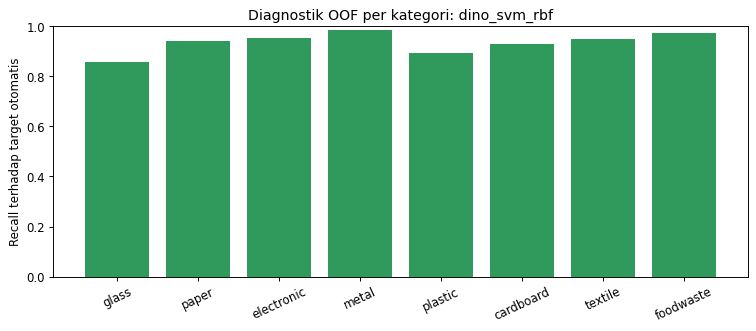

In [19]:
def make_candidate(name):
    if name == 'dino_logistic':
        return LogisticRegression(C=3.0, max_iter=1200, solver='lbfgs', random_state=SEED)
    if name == 'dino_svm_rbf':
        return SVC(C=4.0, kernel='rbf', gamma='scale', decision_function_shape='ovr')
    if name == 'dino_knn7':
        return KNeighborsClassifier(n_neighbors=7, weights='distance', metric='cosine')
    raise ValueError(name)

candidate_names = ['dino_logistic', 'dino_svm_rbf', 'dino_knn7']
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(splitter.split(X_train, y_train, groups))
oof = {name:np.full(len(y_train),-1,dtype=int) for name in candidate_names}
fold_id = np.full(len(y_train),-1,dtype=int)
for fold,(fit_idx,val_idx) in enumerate(folds):
    assert not set(groups[fit_idx]) & set(groups[val_idx])
    assert set(y_train[fit_idx]) == set(range(8))
    fold_id[val_idx] = fold
    for name in candidate_names:
        classifier = make_candidate(name)
        classifier.fit(X_train[fit_idx], y_train[fit_idx])
        oof[name][val_idx] = classifier.predict(X_train[val_idx])
assert np.all(fold_id >= 0) and all(np.all(p >= 0) for p in oof.values())
is_seed = train_rows.human_reviewed.to_numpy(bool)
metrics_rows = []
for name in candidate_names:
    pred = oof[name]
    metrics_rows.append({'model':name,
        'pseudo_oof_agreement':float(accuracy_score(y_train,pred)),
        'pseudo_oof_macro_f1':float(f1_score(y_train,pred,average='macro')),
        'pseudo_oof_balanced_accuracy':float(balanced_accuracy_score(y_train,pred)),
        'reviewed_seed_agreement_contaminated':float(accuracy_score(y_train[is_seed],pred[is_seed]))})
metrics = pd.DataFrame(metrics_rows).sort_values('pseudo_oof_agreement',ascending=False)
display(metrics.style.format(precision=4))
oof_table = train_rows[['sample_id','parent_key','parent_group','assigned_class','human_reviewed']].copy()
oof_table['fold'] = fold_id
for name,pred in oof.items():
    oof_table[name] = [CLASSES[i] for i in pred]
FINAL_OUTPUT.mkdir(parents=True,exist_ok=True)
oof_table.to_csv(FINAL_OUTPUT/'oof_diagnostics.csv',index=False)
best_name = metrics.iloc[0]['model']
recall = confusion_matrix(y_train,oof[best_name],labels=list(range(8)))
class_recall = np.diag(recall)/np.maximum(recall.sum(axis=1),1)
fig,ax=plt.subplots(figsize=(9,4),dpi=85)
ax.bar(CLASSES,class_recall,color='#30995c')
ax.set_ylim(0,1)
ax.set_ylabel('Recall terhadap target otomatis')
ax.set_title('Diagnostik OOF per kategori: '+best_name)
ax.tick_params(axis='x',rotation=25)
fig.tight_layout()
publish_figure()

## 13. Refit seluruh train eligible dan tiga submission

Ketiga konfigurasi dibekukan sebelum inferensi test. Tiap classifier dilatih ulang pada seluruh train eligible, kemudian menghasilkan satu CSV dengan urutan ID persis seperti sample. CSV berbeda metode, tanpa penyesuaian berdasarkan leaderboard. Tidak ada label test yang dibaca.

In [20]:
sample = pd.DataFrame({'image_id': test_order})
assert len(sample) == 480 and sample.image_id.is_unique
assert set(sample.image_id) == set(test_rows.sample_id.astype(str))
submission_files = {
    'dino_logistic':'submission_001_dino_logistic.csv',
    'dino_svm_rbf':'submission_002_dino_svm_rbf.csv',
    'dino_knn7':'submission_003_dino_knn7.csv',
}
submission_details = []
test_predictions = {}
for name in candidate_names:
    classifier = make_candidate(name)
    classifier.fit(X_train,y_train)
    numeric = classifier.predict(X_test)
    assert len(numeric)==480 and set(numeric) <= set(range(8))
    prediction_lookup = dict(zip(test_rows.sample_id,[CLASSES[i] for i in numeric]))
    result = sample[['image_id']].copy()
    result['waste_category'] = result.image_id.map(prediction_lookup)
    assert result.waste_category.notna().all() and result.waste_category.isin(CLASSES).all()
    path = FINAL_OUTPUT/submission_files[name]
    result.to_csv(path,index=False)
    reread = pd.read_csv(path,dtype={'image_id':str})
    assert reread.equals(result) and path.stat().st_size > 1000
    test_predictions[name] = result.waste_category.to_numpy(str)
    submission_details.append({'model':name,'path':relative(path),'sha256':digest(path),
                               'label_vector_sha256':hashlib.sha256('|'.join(test_predictions[name]).encode()).hexdigest(),
                               'class_counts':result.waste_category.value_counts().reindex(CLASSES,fill_value=0).to_dict()})
pairwise_differences = {f'{a}_vs_{b}':int(np.count_nonzero(test_predictions[a]!=test_predictions[b]))
                        for i,a in enumerate(candidate_names) for b in candidate_names[i+1:]}
report = {'metric_scope':'grouped_agreement_with_automatic_train_targets_not_official_accuracy',
          'seed':SEED,'folds':5,'train_samples':len(X_train),'test_samples':len(X_test),
          'training_view':'eligible_full_frame_only','crop_views_used_for_classifier':0,'device':'cpu',
          'source_groups':len(np.unique(groups)),'excluded_train_sources':len(deferred_keys),
          'manual_seed_count':int(is_seed.sum()),'encoder':model_info['model'],
          'encoder_checkpoint_sha256':model_info['checkpoint_sha256'],
          'embedding_identity':embedding_identity,'embedding_cache_sha256':digest(embedding_cache),
          'oof_metrics':metrics_rows,'submission_files':submission_details,
          'pairwise_test_disagreements':pairwise_differences,'official_accuracy':None}
(FINAL_OUTPUT/'modeling_report.json').write_text(json.dumps(report,indent=2),encoding='utf-8')
summary['classifier_training_executed']=True
summary['submission_created']=True
summary['training_eligible_train_samples']=int((processed.split.eq('train')&processed.training_eligible).sum())
summary['modeling_train_samples']=len(X_train)
summary['figures']=figure_exports
summary['modeling_report']=report
summary['seconds']=time.time()-STARTED
(PROCESSED/'provenance.json').write_text(json.dumps({'policy':POLICY,'summary':summary},indent=2),encoding='utf-8')
display(metrics.style.format(precision=4))
display(pd.DataFrame(submission_details)[['model','path','sha256']])
display(pd.Series(pairwise_differences,name='test_predictions_different'))
print('Tiga CSV dibuat dari model yang dilatih pada train eligible; Accuracy resmi belum diketahui.')

,model,pseudo_oof_agreement,pseudo_oof_macro_f1,pseudo_oof_balanced_accuracy,reviewed_seed_agreement_contaminated
1,dino_svm_rbf,0.9335,0.9346,0.9347,0.7027
0,dino_logistic,0.9196,0.9208,0.9211,0.5676
2,dino_knn7,0.9138,0.9149,0.9153,0.5135


,model,path,sha256
0,dino_logistic,final-submit/output/submission_001_dino_logist...,86101e0a1fbd43de6fa3e1bdb8f214d7f522c46adb3bca...
1,dino_svm_rbf,final-submit/output/submission_002_dino_svm_rb...,89eda6a58eb6734501487a58c5237ed9eff4bc2f623223...
2,dino_knn7,final-submit/output/submission_003_dino_knn7.csv,bc83a23a06342f08eee8c1787bcab3967c7adbceac36e5...


dino_logistic_vs_dino_svm_rbf    20
dino_logistic_vs_dino_knn7       32
dino_svm_rbf_vs_dino_knn7        30
Name: test_predictions_different, dtype: int64

Tiga CSV dibuat dari model yang dilatih pada train eligible; Accuracy resmi belum diketahui.


## 14. Kandidat hybrid DINOv2 + histogram warna HSV

Fitur HSV ditambahkan sebagai blok fitur umum. Bobotnya dipilih melalui validasi bertingkat berdasarkan kelompok sumber pada foto train saja. Kategori warna tidak ditetapkan dengan aturan tetap. Kandidat ini dibuat terpisah agar dapat dibandingkan dengan SVM DINO utama.

In [21]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import normalize as l2_normalize
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

# Fitur HSV berasal dari histogram 16-bin per kanal yang dibuat pada tahap EDA.
assert len(train_rows) == 1879 and len(test_rows) == 480
feature_row = {str(key): i for i, key in enumerate(processed.sample_key.astype(str))}
train_feature_idx = np.asarray([feature_row[str(key)] for key in train_rows.sample_key], dtype=int)
test_feature_idx = np.asarray([feature_row[str(key)] for key in test_rows.sample_key], dtype=int)
train_color = l2_normalize(handcrafted_features[train_feature_idx, 1764:])
dino_train = l2_normalize(X_train)
COLOR_WEIGHTS = (0.0, 0.1, 0.2)

def dino_hsv_block(dino, color, color_weight):
    if color_weight == 0:
        return dino
    return np.concatenate([
        dino * np.sqrt(1.0 - color_weight),
        color * np.sqrt(color_weight),
    ], axis=1)

hybrid_train_blocks = {w: dino_hsv_block(dino_train, train_color, w) for w in COLOR_WEIGHTS}
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
nested_dino_oof = np.full(len(y_train), -1, dtype=int)
nested_hybrid_oof = np.full(len(y_train), -1, dtype=int)
nested_fold = np.full(len(y_train), -1, dtype=int)
selected_color_weights = []

for outer_id, (outer_fit, outer_val) in enumerate(outer.split(np.zeros(len(y_train)), y_train, groups)):
    assert not set(groups[outer_fit]) & set(groups[outer_val])
    inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED + 14 + outer_id)
    inner_scores = {w: [] for w in COLOR_WEIGHTS}
    for inner_fit_local, inner_val_local in inner.split(
        np.zeros(len(outer_fit)), y_train[outer_fit], groups[outer_fit]
    ):
        inner_fit = outer_fit[inner_fit_local]
        inner_val = outer_fit[inner_val_local]
        assert not set(groups[inner_fit]) & set(groups[inner_val])
        for w in COLOR_WEIGHTS:
            model = SVC(C=4.0, kernel='rbf', gamma='scale')
            model.fit(hybrid_train_blocks[w][inner_fit], y_train[inner_fit])
            inner_scores[w].append(accuracy_score(
                y_train[inner_val], model.predict(hybrid_train_blocks[w][inner_val])
            ))
    # Ties prefer the smaller HSV contribution.
    selected = max(COLOR_WEIGHTS, key=lambda w: (float(np.mean(inner_scores[w])), -w))
    selected_color_weights.append(float(selected))
    baseline = SVC(C=4.0, kernel='rbf', gamma='scale').fit(dino_train[outer_fit], y_train[outer_fit])
    hybrid = SVC(C=4.0, kernel='rbf', gamma='scale').fit(
        hybrid_train_blocks[selected][outer_fit], y_train[outer_fit]
    )
    nested_dino_oof[outer_val] = baseline.predict(dino_train[outer_val])
    nested_hybrid_oof[outer_val] = hybrid.predict(hybrid_train_blocks[selected][outer_val])
    nested_fold[outer_val] = outer_id

assert np.all(nested_fold >= 0)
assert np.all(nested_dino_oof >= 0) and np.all(nested_hybrid_oof >= 0)
nested_metrics = {
    'dino_only': {
        'agreement': float(accuracy_score(y_train, nested_dino_oof)),
        'macro_f1': float(f1_score(y_train, nested_dino_oof, average='macro')),
        'balanced_accuracy': float(balanced_accuracy_score(y_train, nested_dino_oof)),
    },
    'dino_hsv_nested': {
        'agreement': float(accuracy_score(y_train, nested_hybrid_oof)),
        'macro_f1': float(f1_score(y_train, nested_hybrid_oof, average='macro')),
        'balanced_accuracy': float(balanced_accuracy_score(y_train, nested_hybrid_oof)),
    },
}
weight_values, weight_counts = np.unique(selected_color_weights, return_counts=True)
FINAL_COLOR_WEIGHT = float(weight_values[np.argmax(weight_counts)])
print('Nested group OOF against program-generated train targets:', nested_metrics)
print('Selected HSV weights per outer fold:', selected_color_weights,
      '| final refit weight (train-only modal choice):', FINAL_COLOR_WEIGHT)
print('OOF rows changed from DINO-only:', int(np.count_nonzero(nested_dino_oof != nested_hybrid_oof)))
print('This is train-target agreement, not official semantic accuracy.')

oof_table['dino_hsv_nested'] = [CLASSES[i] for i in nested_hybrid_oof]
oof_table['dino_nested_baseline'] = [CLASSES[i] for i in nested_dino_oof]
oof_table['nested_fold'] = nested_fold
oof_table.to_csv(FINAL_OUTPUT / 'oof_diagnostics.csv', index=False)

# Refit the train-only-selected hybrid; only after this selection, transform test features for final inference.
test_color = l2_normalize(handcrafted_features[test_feature_idx, 1764:])
dino_test = l2_normalize(X_test)
final_hybrid_train = dino_hsv_block(dino_train, train_color, FINAL_COLOR_WEIGHT)
final_hybrid_test = dino_hsv_block(dino_test, test_color, FINAL_COLOR_WEIGHT)
final_hybrid_model = SVC(C=4.0, kernel='rbf', gamma='scale')
final_hybrid_model.fit(final_hybrid_train, y_train)
hybrid_numeric = final_hybrid_model.predict(final_hybrid_test)
hybrid_lookup = dict(zip(test_rows.sample_id.astype(str), [CLASSES[i] for i in hybrid_numeric]))
hybrid_result = sample[['image_id']].copy()
hybrid_result['waste_category'] = hybrid_result.image_id.astype(str).map(hybrid_lookup)
assert len(hybrid_result) == 480 and hybrid_result.image_id.is_unique
assert hybrid_result.waste_category.notna().all() and hybrid_result.waste_category.isin(CLASSES).all()
hybrid_path = FINAL_OUTPUT / 'submission_004_dino_hsv_svm.csv'
hybrid_result.to_csv(hybrid_path, index=False)
hybrid_check = pd.read_csv(hybrid_path, dtype={'image_id': str})
assert hybrid_check.equals(hybrid_result)

base_submission = pd.read_csv(FINAL_OUTPUT / 'submission_002_dino_svm_rbf.csv', dtype={'image_id': str})
base_by_id = base_submission.set_index('image_id').waste_category
hybrid_by_id = hybrid_result.set_index('image_id').waste_category
candidate_diff = int(np.count_nonzero(base_by_id.loc[hybrid_by_id.index].to_numpy() != hybrid_by_id.to_numpy()))
hybrid_record = {
    'model': 'dino_hsv_rbf', 'path': relative(hybrid_path), 'sha256': digest(hybrid_path),
    'label_vector_sha256': hashlib.sha256('|'.join(hybrid_result.waste_category.astype(str)).encode()).hexdigest(),
    'class_counts': hybrid_result.waste_category.value_counts().reindex(CLASSES, fill_value=0).to_dict(),
    'train_samples': len(train_rows), 'color_feature': 'HSV 16-bin histogram per channel',
    'color_weight': FINAL_COLOR_WEIGHT, 'selection': 'nested StratifiedGroupKFold on train only',
    'test_used_for_fit_or_weight_selection': False,
}
report['oof_metrics'].append({
    'model': 'dino_hsv_nested',
    'pseudo_oof_agreement': nested_metrics['dino_hsv_nested']['agreement'],
    'pseudo_oof_macro_f1': nested_metrics['dino_hsv_nested']['macro_f1'],
    'pseudo_oof_balanced_accuracy': nested_metrics['dino_hsv_nested']['balanced_accuracy'],
    'metric_scope': 'nested grouped agreement with program-generated train targets, not official accuracy',
})
report['submission_files'].append(hybrid_record)
report['color_feature_experiment'] = {
    'nested_metrics': nested_metrics, 'selected_color_weights_by_outer_fold': selected_color_weights,
    'final_color_weight': FINAL_COLOR_WEIGHT, 'test_rows_in_training_or_selection': 0,
    'candidate_differences_from_dino_svm': candidate_diff,
}
(FINAL_OUTPUT / 'modeling_report.json').write_text(json.dumps(report, indent=2), encoding='utf-8')
summary['color_feature_experiment'] = report['color_feature_experiment']
summary['submission_created'] = True
summary['modeling_train_samples'] = len(train_rows)
summary['figures'] = figure_exports
summary['seconds'] = time.time() - STARTED
(PROCESSED / 'provenance.json').write_text(
    json.dumps({'policy': POLICY, 'summary': summary}, indent=2), encoding='utf-8'
)
print('Hybrid CSV:', relative(hybrid_path), '| changes vs DINO SVM:', candidate_diff)


Nested group OOF against program-generated train targets: {'dino_only': {'agreement': 0.9334752527940394, 'macro_f1': 0.9346332981441611, 'balanced_accuracy': 0.9346883752464112}, 'dino_hsv_nested': {'agreement': 0.9334752527940394, 'macro_f1': 0.9348875254642179, 'balanced_accuracy': 0.9349166315880835}}
Selected HSV weights per outer fold: [0.0, 0.1, 0.2, 0.0, 0.1] | final refit weight (train-only modal choice): 0.0
OOF rows changed from DINO-only: 15
This is train-target agreement, not official semantic accuracy.


Hybrid CSV: final-submit/output/submission_004_dino_hsv_svm.csv | changes vs DINO SVM: 0


## 15. Tahap pseudo-label test dinonaktifkan

Aturan kompetisi terbaru melarang penggunaan foto test dalam training. Karena itu, tahap adaptasi classifier dengan pseudo-label dari test tidak dijalankan. Submission tahap 008 di bawah memakai train untuk fit dan test hanya untuk inferensi.


In [22]:
from IPython.display import display, Markdown
display(Markdown('Tahap adaptasi test dilewati sesuai aturan; test tidak masuk proses fit. Kandidat utama train-only dibuat pada tahap berikutnya.'))


Tahap adaptasi test dilewati sesuai aturan; test tidak masuk proses fit. Kandidat utama train-only dibuat pada tahap berikutnya.

## 16. DINOv3 full descriptors + OVR SVM ? submission 008

Model DINOv3 image-only yang dibekukan menghasilkan empat blok fitur per foto: CLS, rerata patch valid, rerata patch foreground berbasis perbedaan piksel, dan simpangan baku patch foreground. Mask foreground dihitung dengan aturan piksel yang sama untuk train dan test; tidak memakai label atau model deteksi eksternal. Tiap blok dinormalisasi L2.

One-vs-rest RBF SVM dievaluasi memakai lima fold `StratifiedGroupKFold` berdasarkan source group, kemudian di-fit ulang pada seluruh train eligible. Test hanya ditransformasikan dan diprediksi. Fitur cache hanya dipakai bila checkpoint, ID, hash semua sumber, dan resep fitur cocok. Kandidat ini memakai resep DINOv3 yang direproduksi di notebook; hasilnya dapat berbeda dari berkas 008 eksperimen sebelumnya.


In [23]:
import gc
import torch
import torch.nn.functional as F
import timm
from huggingface_hub import hf_hub_download
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from threadpoolctl import threadpool_limits

# Pin the image-only DINOv3 Base checkpoint and verify the exact bytes.
D3_REPOSITORY = 'timm/vit_base_patch16_dinov3.lvd1689m'
D3_REVISION = 'c6a5fb7d12bbd3cf3b0079253141c3332aaed7da'
D3_MODEL_NAME = 'vit_base_patch16_dinov3.lvd1689m'
D3_WEIGHT_SHA256 = '1f9ed8a2378d65e24bb710ba522ac9fa7be4e036d7aefb4384ce022833926332'
d3_weight = hf_hub_download(D3_REPOSITORY, 'model.safetensors', revision=D3_REVISION)
assert digest(d3_weight) == D3_WEIGHT_SHA256

d3_rows = pd.concat([train_rows, test_rows], ignore_index=True)
assert d3_rows.parent_key.is_unique and len(train_rows) == 1879 and len(test_rows) == 480
assert d3_rows.source_path.notna().all() and d3_rows.source_sha256.notna().all()
d3_keys = np.asarray(d3_rows.parent_key.astype(str).tolist(), dtype='U10')
d3_source_hashes = np.asarray(d3_rows.source_sha256.astype(str).tolist(), dtype='U64')
d3_recipe = 'dinov3base_256_letterbox_valid_foreground4x768_v1'
d3_identity = hashlib.sha256((D3_WEIGHT_SHA256 + d3_recipe + '|'.join(d3_keys) + '|'.join(d3_source_hashes)).encode()).hexdigest()
d3_cache = PROCESSED / 'dinov3_full_ovr_features.npz'
d3_features = np.full((len(d3_rows), 3072), np.nan, dtype=np.float32)
d3_cache_exact = False
d3_ready = np.zeros(len(d3_rows), dtype=bool)
if d3_cache.is_file():
    with np.load(d3_cache, allow_pickle=False) as z:
        cached_keys = z['keys'].astype(str)
        cached_hashes = z['source_sha256'].astype(str)
        cached_features = z['features'].copy()
        cached_identity = hashlib.sha256((D3_WEIGHT_SHA256 + d3_recipe + '|'.join(cached_keys) + '|'.join(cached_hashes)).encode()).hexdigest()
        if (str(z['identity'].item()) == cached_identity and
            cached_features.shape == (len(cached_keys), 3072) and
            len(cached_hashes) == len(cached_keys) and np.isfinite(cached_features).all()):
            d3_cache_exact = (str(z['identity'].item()) == d3_identity and
                np.array_equal(cached_keys, d3_keys) and np.array_equal(cached_hashes, d3_source_hashes))
            cached_index = {key: i for i, key in enumerate(cached_keys)}
            for i, (key, source_hash) in enumerate(zip(d3_keys, d3_source_hashes)):
                j = cached_index.get(str(key))
                if j is not None and cached_hashes[j] == source_hash:
                    d3_features[i] = cached_features[j]
                    d3_ready[i] = True
            print(f'Cache fitur DINOv3 tervalidasi: {int(d3_ready.sum())}/{len(d3_rows)} baris dapat dipakai ulang.')
d3_missing_indices = np.flatnonzero(~d3_ready)

if len(d3_missing_indices):
    d3_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    torch.set_num_threads(min(4, os.cpu_count() or 1))
    d3_encoder = timm.create_model(D3_MODEL_NAME, pretrained=True, num_classes=0,
        pretrained_cfg_overlay={'file': d3_weight}).eval().to(d3_device)
    if hasattr(d3_encoder, 'rope') and hasattr(d3_encoder.rope, 'periods'):
        d3_encoder.rope.periods = d3_encoder.rope.periods.to(torch.bfloat16).to(torch.float32)
    d3_cfg = timm.data.resolve_model_data_config(d3_encoder)
    assert d3_encoder.num_features == 768 and tuple(d3_cfg['input_size']) == (3, 256, 256)
    d3_prefix = d3_encoder.num_prefix_tokens
    d3_mean = np.asarray(d3_cfg['mean'], dtype=np.float32)
    d3_std = np.asarray(d3_cfg['std'], dtype=np.float32)

    def d3_prepare(path):
        im = rgb_image(resolve(path))
        width, height = im.size
        scale = 256 / max(width, height)
        nw, nh = max(1, round(width * scale)), max(1, round(height * scale))
        dx, dy = (256 - nw) // 2, (256 - nh) // 2
        canvas = np.empty((256, 256, 3), dtype=np.uint8)
        canvas[:] = [124, 116, 104]
        resized = np.asarray(im.resize((nw, nh), Image.Resampling.BICUBIC))
        canvas[dy:dy+nh, dx:dx+nw] = resized
        valid = np.zeros((256, 256), dtype=np.float32)
        valid[dy:dy+nh, dx:dx+nw] = 1.
        # Pixel-only foreground proposal; no category labels/model predictions enter this mask.
        border = np.concatenate([resized[0], resized[-1], resized[:, 0], resized[:, -1]], axis=0).astype(np.float32)
        center = np.median(border, axis=0)
        dispersion = np.linalg.norm(border-center, axis=1)
        foreground = valid.copy()
        if float(np.quantile(dispersion, .75)) < 30:
            distance = np.linalg.norm(resized.astype(np.float32)-center, axis=2)
            mask = (distance > max(25., float(np.quantile(dispersion, .95))+10.)).astype(np.uint8)
            mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((3,3), np.uint8))
            fraction = float(mask.mean())
            if .03 <= fraction <= .90:
                foreground[:] = 0
                foreground[dy:dy+nh, dx:dx+nw] = mask.astype(np.float32)
                foreground += .05 * valid
        valid_patch = cv2.resize(valid, (16,16), interpolation=cv2.INTER_AREA).reshape(-1)
        foreground_patch = cv2.resize(foreground, (16,16), interpolation=cv2.INTER_AREA).reshape(-1)
        tensor = np.asarray(canvas, dtype=np.float32) / 255.
        tensor = (tensor-d3_mean[None,None,:]) / d3_std[None,None,:]
        tensor = torch.from_numpy(tensor.transpose(2,0,1).copy())
        return tensor, valid_patch, foreground_patch

    d3_batch_size = 8 if d3_device.type == 'cuda' else 2
    d3_blocks = []
    d3_missing_rows = d3_rows.iloc[d3_missing_indices]
    with torch.inference_mode():
        for start in range(0, len(d3_missing_rows), d3_batch_size):
            batch_rows = d3_missing_rows.iloc[start:start+d3_batch_size]
            prepared = [d3_prepare(row.source_path) for row in batch_rows.itertuples()]
            images = torch.stack([item[0] for item in prepared]).to(d3_device)
            tokens = d3_encoder.forward_features(images)
            patches = tokens[:, d3_prefix:]
            assert patches.shape[1:] == (256, 768)
            valid = torch.as_tensor(np.stack([item[1] for item in prepared]), device=d3_device)
            foreground = torch.as_tensor(np.stack([item[2] for item in prepared]), device=d3_device)
            valid = valid / valid.sum(1, keepdim=True).clamp_min(1e-8)
            foreground = foreground / foreground.sum(1, keepdim=True).clamp_min(1e-8)
            global_mean = (patches * valid[:,:,None]).sum(1)
            object_mean = (patches * foreground[:,:,None]).sum(1)
            object_std = (((patches-object_mean[:,None,:]).square()*foreground[:,:,None]).sum(1).clamp_min(0)).sqrt()
            blocks = [F.normalize(x, dim=1) for x in [tokens[:,0], global_mean, object_mean, object_std]]
            batch_features = torch.cat(blocks, dim=1).cpu().numpy().astype(np.float32)
            assert batch_features.shape == (len(batch_rows), 3072) and np.isfinite(batch_features).all()
            d3_blocks.append(batch_features)
            completed = min(start+len(batch_rows), len(d3_missing_rows))
            if completed == len(d3_missing_rows) or completed % 256 < d3_batch_size:
                print(f'DINOv3 feature extraction: {completed}/{len(d3_missing_rows)} missing rows | device={d3_device}', flush=True)
    if d3_blocks:
        d3_features[d3_missing_indices] = np.concatenate(d3_blocks)
    assert np.isfinite(d3_features).all()
    temp_cache = d3_cache.with_suffix('.writing.npz')
    np.savez_compressed(temp_cache, keys=d3_keys, source_sha256=d3_source_hashes,
                        identity=np.array(d3_identity), features=d3_features)
    temp_cache.replace(d3_cache)
    del d3_encoder, d3_blocks
    gc.collect()
elif not d3_cache_exact:
    temp_cache = d3_cache.with_suffix('.writing.npz')
    np.savez_compressed(temp_cache, keys=d3_keys, source_sha256=d3_source_hashes,
                        identity=np.array(d3_identity), features=d3_features)
    temp_cache.replace(d3_cache)

assert d3_features.shape == (len(d3_rows), 3072) and np.isfinite(d3_features).all()
d3_train_x = d3_features[:len(train_rows)]
d3_test_x = d3_features[len(train_rows):]
d3_y = np.asarray([CLASSES.index(name) for name in train_rows.assigned_class], dtype=int)
d3_groups = train_rows.parent_group.astype(str).to_numpy()
d3_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
d3_folds = list(d3_cv.split(d3_train_x, d3_y, d3_groups))
d3_oof = np.full(len(d3_y), -1, dtype=int)
with threadpool_limits(limits=4):
    for fold, (fit_idx, val_idx) in enumerate(d3_folds, 1):
        assert set(d3_groups[fit_idx]).isdisjoint(set(d3_groups[val_idx]))
        assert set(d3_y[fit_idx]) == set(range(8))
        model = OneVsRestClassifier(SVC(C=4.0, kernel='rbf', gamma='scale'), n_jobs=1)
        model.fit(d3_train_x[fit_idx], d3_y[fit_idx])
        d3_oof[val_idx] = model.predict(d3_train_x[val_idx])
        print(f'Grouped OOF fold {fold}/5 complete', flush=True)
assert np.all(d3_oof >= 0)
d3_metrics = {'oof_agreement_program_targets': float(accuracy_score(d3_y, d3_oof)),
               'oof_balanced_accuracy_program_targets': float(balanced_accuracy_score(d3_y, d3_oof)),
               'oof_macro_f1_program_targets': float(f1_score(d3_y, d3_oof, average='macro')),
               'metric_scope': 'grouped agreement with derived train categories; not official semantic accuracy'}
print('Submission 008 OOF:', d3_metrics)

with threadpool_limits(limits=4):
    d3_final_model = OneVsRestClassifier(SVC(C=4.0, kernel='rbf', gamma='scale'), n_jobs=1)
    d3_final_model.fit(d3_train_x, d3_y)
    d3_prediction = d3_final_model.predict(d3_test_x)
assert len(d3_prediction) == 480 and set(d3_prediction) <= set(range(8))
d3_lookup = dict(zip(test_rows.sample_id.astype(str), [CLASSES[i] for i in d3_prediction]))
d3_result = pd.DataFrame({'image_id': test_order})
d3_result['waste_category'] = d3_result.image_id.map(d3_lookup)
assert len(d3_result) == 480 and d3_result.image_id.is_unique
assert d3_result.waste_category.notna().all() and d3_result.waste_category.isin(CLASSES).all()
submission_008_path = FINAL_OUTPUT / 'submission_008_dinov3_full_ovr_svm.csv'
d3_result.to_csv(submission_008_path, index=False)
d3_check = pd.read_csv(submission_008_path, dtype={'image_id': str})
assert d3_check.equals(d3_result)
submission_008_report = {
    'model': 'DINOv3 Base four-block image descriptors + OneVsRest RBF SVM',
    'train_rows': int(len(train_rows)), 'test_rows_in_fit': 0, 'test_rows_inference': int(len(test_rows)),
    'feature_dimensions': int(d3_features.shape[1]), 'feature_recipe': d3_recipe,
    'checkpoint_repository': D3_REPOSITORY, 'checkpoint_revision': D3_REVISION,
    'checkpoint_sha256': D3_WEIGHT_SHA256, 'feature_cache_sha256': digest(d3_cache),
    'oof': d3_metrics, 'groups': int(len(np.unique(d3_groups))),
    'submission_sha256': digest(submission_008_path), 'official_accuracy': None,
    'note': 'Notebook-generated candidate from train-only fitting and test-only inference; official accuracy is not yet known.'
}
(FINAL_OUTPUT / 'submission_008_dinov3_full_ovr_svm.json').write_text(json.dumps(submission_008_report, indent=2), encoding='utf-8')
print('Submission 008 dibuat:', relative(submission_008_path), '| SHA256:', submission_008_report['submission_sha256'])


Cache fitur DINOv3 tervalidasi: 2359/2359 baris dapat dipakai ulang.


Grouped OOF fold 1/5 complete


Grouped OOF fold 2/5 complete


Grouped OOF fold 3/5 complete


Grouped OOF fold 4/5 complete


Grouped OOF fold 5/5 complete


Submission 008 OOF: {'oof_agreement_program_targets': 0.9536987759446514, 'oof_balanced_accuracy_program_targets': 0.9542002941734163, 'oof_macro_f1_program_targets': 0.9545510922442869, 'metric_scope': 'grouped agreement with derived train categories; not official semantic accuracy'}


Submission 008 dibuat: final-submit/output/submission_008_dinov3_full_ovr_svm.csv | SHA256: 3f19c0c4217eafe96ffff751d156313763c3cd745d4f7cd432af008c67edcf33


## 17. Ahli per kelas dengan kalibrasi margin train-only

Setiap kelas memiliki SVM RBF biner sendiri (kelas tersebut vs kelas lain), memakai bobot seimbang. Margin tiap ahli dipetakan menjadi probabilitas melalui regresi logistik yang dilatih pada margin OOF train berdasarkan source group. Evaluasi luarnya nested: kalibrasi hanya melihat OOF dari outer-train, sedangkan outer-validation tidak masuk fit. Setelah evaluasi, kalibrator akhir dibuat dari OOF seluruh train dan ahli final dilatih ulang pada seluruh train eligible.

Kandidat ini menguji apakah keputusan kelas-per-kelas lebih baik daripada OVR 008 pada validasi kelompok. Tidak ada target test, ID test khusus, atau CSV prediksi sebelumnya dipakai untuk memilih model. Kandidat 009 tetap eksperimen; metrik OOF hanya agreement terhadap kategori turunan.


In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.svm import SVC
from threadpoolctl import threadpool_limits

EXPERT_C = 4.0
EXPERT_GAMMA = 'scale'
EXPERT_CLASSES = np.arange(len(CLASSES), dtype=int)

def fit_class_experts(x, y):
    bank = []
    for class_id in EXPERT_CLASSES:
        binary = (y == class_id).astype(int)
        assert np.unique(binary).size == 2
        expert = SVC(C=EXPERT_C, kernel='rbf', gamma=EXPERT_GAMMA,
                     class_weight='balanced')
        expert.fit(x, binary)
        bank.append(expert)
    return bank

def expert_margins(bank, x):
    return np.column_stack([expert.decision_function(x) for expert in bank])

def fit_margin_calibrators(margins, y):
    assert margins.shape == (len(y), len(CLASSES)) and np.isfinite(margins).all()
    calibrators = []
    for class_id in EXPERT_CLASSES:
        calibrator = LogisticRegression(C=1.0, solver='lbfgs', max_iter=1000,
                                        random_state=SEED)
        calibrator.fit(margins[:, class_id:class_id+1], (y == class_id).astype(int))
        calibrators.append(calibrator)
    return calibrators

def calibrated_expert_probabilities(calibrators, margins):
    probs = np.column_stack([
        calibrator.predict_proba(margins[:, class_id:class_id+1])[:, 1]
        for class_id, calibrator in enumerate(calibrators)
    ])
    probs = np.clip(probs, 1e-8, 1.0)
    return probs / probs.sum(axis=1, keepdims=True)

# Nested grouped evaluation: outer validation never trains its expert or calibrator.
expert_outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
expert_oof = np.full((len(d3_y), len(CLASSES)), np.nan, dtype=np.float64)
expert_baseline_oof = np.full(len(d3_y), -1, dtype=int)
expert_outer_fold = np.full(len(d3_y), -1, dtype=int)
with threadpool_limits(limits=4):
    for outer_id, (outer_fit, outer_val) in enumerate(
        expert_outer.split(d3_train_x, d3_y, d3_groups), 1
    ):
        assert set(d3_groups[outer_fit]).isdisjoint(set(d3_groups[outer_val]))
        inner_groups = d3_groups[outer_fit]
        inner_splitter = StratifiedGroupKFold(
            n_splits=3, shuffle=True, random_state=SEED + 100 + outer_id
        )
        inner_margins = np.full((len(outer_fit), len(CLASSES)), np.nan, dtype=np.float64)
        inner_y = d3_y[outer_fit]
        inner_x = d3_train_x[outer_fit]
        for inner_fit, inner_val in inner_splitter.split(inner_x, inner_y, inner_groups):
            assert set(inner_groups[inner_fit]).isdisjoint(set(inner_groups[inner_val]))
            assert set(inner_y[inner_fit]) == set(EXPERT_CLASSES)
            bank = fit_class_experts(inner_x[inner_fit], inner_y[inner_fit])
            inner_margins[inner_val] = expert_margins(bank, inner_x[inner_val])
        assert np.isfinite(inner_margins).all()
        calibrators = fit_margin_calibrators(inner_margins, inner_y)
        outer_bank = fit_class_experts(d3_train_x[outer_fit], d3_y[outer_fit])
        outer_margins = expert_margins(outer_bank, d3_train_x[outer_val])
        expert_oof[outer_val] = calibrated_expert_probabilities(calibrators, outer_margins)
        baseline = OneVsRestClassifier(SVC(C=4.0, kernel='rbf', gamma='scale'), n_jobs=1)
        baseline.fit(d3_train_x[outer_fit], d3_y[outer_fit])
        expert_baseline_oof[outer_val] = baseline.predict(d3_train_x[outer_val])
        expert_outer_fold[outer_val] = outer_id - 1
        print(f'Class experts nested outer fold {outer_id}/5 complete', flush=True)

assert np.isfinite(expert_oof).all() and np.all(expert_baseline_oof >= 0)
expert_oof_pred = expert_oof.argmax(axis=1)
expert_metrics = {
    'classwise_expert_nested_oof': {
        'agreement': float(accuracy_score(d3_y, expert_oof_pred)),
        'balanced_accuracy': float(balanced_accuracy_score(d3_y, expert_oof_pred)),
        'macro_f1': float(f1_score(d3_y, expert_oof_pred, average='macro')),
    },
    'ovr_008_paired_outer_oof': {
        'agreement': float(accuracy_score(d3_y, expert_baseline_oof)),
        'balanced_accuracy': float(balanced_accuracy_score(d3_y, expert_baseline_oof)),
        'macro_f1': float(f1_score(d3_y, expert_baseline_oof, average='macro')),
    },
}
print('Nested grouped OOF (derived train categories):', expert_metrics)

# Final per-class calibrators are learned only from source-group OOF train margins.
final_margin_oof = np.full((len(d3_y), len(CLASSES)), np.nan, dtype=np.float64)
final_cal_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
with threadpool_limits(limits=4):
    for fit_idx, val_idx in final_cal_cv.split(d3_train_x, d3_y, d3_groups):
        assert set(d3_groups[fit_idx]).isdisjoint(set(d3_groups[val_idx]))
        assert set(d3_y[fit_idx]) == set(EXPERT_CLASSES)
        fold_bank = fit_class_experts(d3_train_x[fit_idx], d3_y[fit_idx])
        final_margin_oof[val_idx] = expert_margins(fold_bank, d3_train_x[val_idx])
    assert np.isfinite(final_margin_oof).all()
    final_expert_calibrators = fit_margin_calibrators(final_margin_oof, d3_y)
    final_expert_bank = fit_class_experts(d3_train_x, d3_y)
    test_margins = expert_margins(final_expert_bank, d3_test_x)
    test_probabilities = calibrated_expert_probabilities(final_expert_calibrators, test_margins)

expert_test_pred = test_probabilities.argmax(axis=1)
expert_lookup = dict(zip(test_rows.sample_id.astype(str),
                         [CLASSES[i] for i in expert_test_pred]))
expert_result = pd.DataFrame({'image_id': test_order})
expert_result['waste_category'] = expert_result.image_id.map(expert_lookup)
assert len(expert_result) == 480 and expert_result.image_id.is_unique
assert expert_result.waste_category.notna().all()
assert expert_result.waste_category.isin(CLASSES).all()
base008_path = FINAL_OUTPUT / 'submission_008_dinov3_full_ovr_svm.csv'
base008 = pd.read_csv(base008_path, dtype={'image_id': str}).set_index('image_id').loc[expert_result.image_id]
expert_changed_vs_008 = int(np.count_nonzero(
    expert_result.waste_category.to_numpy() != base008.waste_category.to_numpy()
))

expert_oof_table = train_rows[['sample_id', 'parent_key', 'parent_group', 'assigned_class']].copy()
expert_oof_table['outer_fold'] = expert_outer_fold
expert_oof_table['ovr_008_oof'] = [CLASSES[i] for i in expert_baseline_oof]
expert_oof_table['classwise_expert_oof'] = [CLASSES[i] for i in expert_oof_pred]
for class_id, class_name in enumerate(CLASSES):
    expert_oof_table[f'p_{class_name}'] = expert_oof[:, class_id]
expert_oof_path = FINAL_OUTPUT / 'classwise_expert_oof.csv'
expert_oof_table.to_csv(expert_oof_path, index=False)

expert_path = FINAL_OUTPUT / 'submission_009_dinov3_classwise_platt_svm.csv'
expert_prob_path = FINAL_OUTPUT / 'submission_009_classwise_probabilities.csv'
if expert_changed_vs_008:
    expert_result.to_csv(expert_path, index=False)
    assert pd.read_csv(expert_path, dtype={'image_id': str}).equals(expert_result)
    expert_prob_table = pd.DataFrame(test_probabilities, columns=[f'p_{name}' for name in CLASSES])
    expert_prob_table.insert(0, 'image_id', test_order)
    expert_prob_table.to_csv(expert_prob_path, index=False)
    submission_path = relative(expert_path)
    submission_sha = digest(expert_path)
    probability_sha = digest(expert_prob_path)
else:
    # Avoid creating a duplicate submission when every predicted class matches 008.
    for redundant_path in [expert_path, expert_prob_path]:
        if redundant_path.exists():
            redundant_path.unlink()
    submission_path = None
    submission_sha = None
    probability_sha = None

expert_report = {
    'model': 'DINOv3 classwise balanced RBF SVM experts + grouped-OOF Platt calibration',
    'train_rows': int(len(d3_y)), 'test_rows_in_fit': 0, 'test_rows_inference': 480,
    'feature_dimensions': int(d3_train_x.shape[1]), 'classes': CLASSES,
    'outer_split': '5-fold StratifiedGroupKFold by parent_group',
    'calibration': '3-fold grouped OOF inside each outer-train; final calibrator uses 5-fold grouped OOF train margins',
    'hyperparameters': {'C': EXPERT_C, 'gamma': EXPERT_GAMMA, 'class_weight': 'balanced'},
    'nested_metrics': expert_metrics,
    'paired_oof_rows_changed_vs_008': int(np.count_nonzero(expert_oof_pred != expert_baseline_oof)),
    'test_prediction_rows_changed_vs_008': expert_changed_vs_008,
    'duplicate_submission_suppressed': bool(expert_changed_vs_008 == 0),
    'submission_path': submission_path, 'submission_sha256': submission_sha,
    'oof_path': relative(expert_oof_path), 'oof_sha256': digest(expert_oof_path),
    'test_probability_path': relative(expert_prob_path) if expert_changed_vs_008 else None,
    'test_probability_sha256': probability_sha,
    'official_accuracy': None, 'test_used_for_fit_or_model_selection': False,
    'interpretation': 'OOF scores are agreement with derived train categories, not official semantic accuracy.'
}
expert_report_path = FINAL_OUTPUT / 'classwise_expert_report.json'
expert_report_path.write_text(json.dumps(expert_report, indent=2), encoding='utf-8')
print('Nested grouped OOF:', expert_metrics)
print('Class-expert candidate differs from 008 on', expert_changed_vs_008, 'test rows; duplicate CSV suppressed if zero.')


Class experts nested outer fold 1/5 complete


Class experts nested outer fold 2/5 complete


Class experts nested outer fold 3/5 complete


Class experts nested outer fold 4/5 complete


Class experts nested outer fold 5/5 complete


Nested grouped OOF (derived train categories): {'classwise_expert_nested_oof': {'agreement': 0.9531665779670038, 'balanced_accuracy': 0.9537044575618243, 'macro_f1': 0.9541069885790424}, 'ovr_008_paired_outer_oof': {'agreement': 0.9536987759446514, 'balanced_accuracy': 0.9542002941734163, 'macro_f1': 0.9545510922442869}}


Nested grouped OOF: {'classwise_expert_nested_oof': {'agreement': 0.9531665779670038, 'balanced_accuracy': 0.9537044575618243, 'macro_f1': 0.9541069885790424}, 'ovr_008_paired_outer_oof': {'agreement': 0.9536987759446514, 'balanced_accuracy': 0.9542002941734163, 'macro_f1': 0.9545510922442869}}
Class-expert candidate differs from 008 on 6 test rows; duplicate CSV suppressed if zero.


## Batas evaluasi
OOF menggunakan fold berkelompok pada data train eligible. Skornya mengukur kesesuaian dengan target train yang dibentuk di pipeline, bukan accuracy resmi pada label independen. CSV yang dibuat adalah kandidat lokal dan belum dikirim ke Kaggle.


## 18. OVR RBF SVM dengan validasi kelompok train

Kandidat memakai fitur gambar DINOv3 dan One-vs-Rest RBF SVM. Skor grouped OOF dihitung berdasarkan grup sumber; model final dilatih pada seluruh train eligible lalu memprediksi test.


In [25]:
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

OVR_C = 1.0
ovr_cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
ovr_oof = np.full(len(d3_y), -1, dtype=int)
for fold_id, (fit_idx, val_idx) in enumerate(
    ovr_cv.split(d3_train_x, d3_y, d3_groups), start=1
):
    assert set(d3_groups[fit_idx]).isdisjoint(set(d3_groups[val_idx]))
    fold_model = OneVsRestClassifier(SVC(C=OVR_C, kernel='rbf', gamma='scale'))
    fold_model.fit(d3_train_x[fit_idx], d3_y[fit_idx])
    ovr_oof[val_idx] = fold_model.predict(d3_train_x[val_idx])
ovr_metrics = {
    'accuracy': float(accuracy_score(d3_y, ovr_oof)),
    'balanced_accuracy': float(balanced_accuracy_score(d3_y, ovr_oof)),
    'macro_f1': float(f1_score(d3_y, ovr_oof, average='macro')),
}
final_ovr = OneVsRestClassifier(SVC(C=OVR_C, kernel='rbf', gamma='scale'))
final_ovr.fit(d3_train_x, d3_y)
ovr_test_pred = final_ovr.predict(d3_test_x)
submission_010 = pd.DataFrame({
    'image_id': test_order,
    'waste_category': [CLASSES[i] for i in ovr_test_pred],
})
submission_010_path = FINAL_OUTPUT / 'submission_010_dinov3_ovr_svm_c1.csv'
submission_010.to_csv(submission_010_path, index=False)
submission_010_check = pd.read_csv(submission_010_path, dtype={'image_id': str})
assert len(submission_010_check) == 480 and submission_010_check.image_id.is_unique
assert submission_010_check.waste_category.isin(CLASSES).all()
assert submission_010_check.image_id.tolist() == list(test_order)
print('Grouped train OOF:', ovr_metrics)
print('Submission 010:', relative(submission_010_path), '| rows:', len(submission_010_check),
      '| SHA256:', digest(submission_010_path))


Grouped train OOF: {'accuracy': 0.9451836083022884, 'balanced_accuracy': 0.9462106902208209, 'macro_f1': 0.945852371677235}
Submission 010: final-submit/output/submission_010_dinov3_ovr_svm_c1.csv | rows: 480 | SHA256: 21525dbdf50d5820e99972518333a692c3c7cbde18b5581b6d7c6c674be6d034


## 19. Fine-tuning dua tahap: inti stabil lalu pseudo-label train-only

Tahap pertama memakai logistic regression, RBF-SVM, dan kNN dalam OOF per source group untuk membentuk inti train stabil: ketiga model harus sepakat dengan kategori aktif. Label yang ditinjau langsung anggota tim juga masuk inti dan tidak diubah. Tahap kedua melatih model hanya pada inti, lalu memprediksi sisa gambar melalui validasi kelompok yang menahan seluruh source group. Sisa hanya masuk refit bila ketiga model tahap dua sepakat. Jumlah label yang diterima ditentukan algoritma, tanpa acuan eksternal, file submission, atau label test. Test hanya digunakan untuk inferensi final.


In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

CONSENSUS_MODELS = ('logistic', 'svm_rbf', 'knn7')
STAGE1_SPLITS = 5
STAGE2_SPLITS = 5
STAGE2_SEED = SEED + 400
MIN_STAGE2_VOTES = 3


def make_consensus_models():
    return {
        'logistic': LogisticRegression(C=3.0, max_iter=1200, solver='lbfgs', random_state=SEED),
        'svm_rbf': SVC(C=4.0, kernel='rbf', gamma='scale', decision_function_shape='ovr'),
        'knn7': KNeighborsClassifier(n_neighbors=7, weights='distance', metric='cosine', n_jobs=2),
    }


def crossfit_consensus_predictions(x, y, groups, n_splits, seed):
    splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    predictions = {name: np.full(len(y), -1, dtype=int) for name in CONSENSUS_MODELS}
    for fit_idx, val_idx in splitter.split(x, y, groups):
        assert set(groups[fit_idx]).isdisjoint(set(groups[val_idx]))
        assert set(y[fit_idx]) == set(range(len(CLASSES)))
        for name, model in make_consensus_models().items():
            model.fit(x[fit_idx], y[fit_idx])
            predictions[name][val_idx] = model.predict(x[val_idx])
    assert all(np.all(pred >= 0) for pred in predictions.values())
    return np.column_stack([predictions[name] for name in CONSENSUS_MODELS])


def consensus_and_votes(prediction_matrix):
    consensus = np.full(len(prediction_matrix), -1, dtype=int)
    votes = np.zeros(len(prediction_matrix), dtype=int)
    for row_idx, row in enumerate(prediction_matrix):
        labels, counts = np.unique(row, return_counts=True)
        winner_idx = int(np.argmax(counts))
        consensus[row_idx] = int(labels[winner_idx])
        votes[row_idx] = int(counts[winner_idx])
    return consensus, votes


def fit_final_classifier(x, y):
    model = OneVsRestClassifier(SVC(C=OVR_C, kernel='rbf', gamma='scale'), n_jobs=1)
    model.fit(x, y)
    return model


# Stage 1: a group-held-out consensus defines the stable training core.
stage1_matrix = crossfit_consensus_predictions(
    d3_train_x, d3_y, d3_groups,
    n_splits=STAGE1_SPLITS, seed=STAGE2_SEED,
)
stage1_consensus, stage1_votes = consensus_and_votes(stage1_matrix)
protected_train = train_rows.human_reviewed.fillna(False).to_numpy(bool)
core_mask = ((stage1_votes == len(CONSENSUS_MODELS)) & (stage1_consensus == d3_y)) | protected_train
residual_mask = ~core_mask
core_indices = np.flatnonzero(core_mask)
residual_indices = np.flatnonzero(residual_mask)
assert len(core_indices) > len(CLASSES) and len(residual_indices) > 0
assert set(d3_y[core_indices]) == set(range(len(CLASSES)))

# Stage 2: fit only on core examples and predict residual examples with source groups held out.
stage2_matrix = np.full((len(residual_indices), len(CONSENSUS_MODELS)), -1, dtype=int)
residual_groups = d3_groups[residual_indices]
residual_cv = GroupKFold(n_splits=min(STAGE2_SPLITS, len(np.unique(residual_groups))))
for fold_id, (res_fit_local, res_val_local) in enumerate(
    residual_cv.split(d3_train_x[residual_indices], groups=residual_groups), start=1
):
    query_indices = residual_indices[res_val_local]
    held_groups = set(d3_groups[query_indices])
    fit_indices = core_indices[~np.isin(d3_groups[core_indices], list(held_groups))]
    fit_y = d3_y[fit_indices]
    assert set(fit_y) == set(range(len(CLASSES)))
    assert set(d3_groups[fit_indices]).isdisjoint(held_groups)
    for model_idx, (name, model) in enumerate(make_consensus_models().items()):
        model.fit(d3_train_x[fit_indices], fit_y)
        stage2_matrix[res_val_local, model_idx] = model.predict(d3_train_x[query_indices])
    print(f'Prediksi residual tahap 2: fold {fold_id}/{residual_cv.get_n_splits()}', flush=True)
assert np.all(stage2_matrix >= 0)

stage2_consensus, stage2_votes = consensus_and_votes(stage2_matrix)
accepted_residual_local = stage2_votes >= MIN_STAGE2_VOTES
accepted_indices = residual_indices[accepted_residual_local]
accepted_targets = stage2_consensus[accepted_residual_local]
final_fit_indices = np.concatenate([core_indices, accepted_indices])
final_fit_targets = np.concatenate([d3_y[core_indices], accepted_targets])
assert set(final_fit_targets) == set(range(len(CLASSES)))
assert len(final_fit_indices) == len(np.unique(final_fit_indices))

# Refit on the stable core plus only unanimous cross-fit pseudo-labels.
final_stage2_model = fit_final_classifier(d3_train_x[final_fit_indices], final_fit_targets)
final_stage2_pred = final_stage2_model.predict(d3_test_x)

stage2_prediction_all = np.full(len(d3_y), -1, dtype=int)
stage2_prediction_all[residual_indices] = stage2_consensus
stage2_votes_all = np.zeros(len(d3_y), dtype=int)
stage2_votes_all[residual_indices] = stage2_votes
used_in_final_fit = core_mask.copy()
used_in_final_fit[accepted_indices] = True
final_category_all = np.full(len(d3_y), '', dtype=object)
final_category_all[core_indices] = [CLASSES[i] for i in d3_y[core_indices]]
final_category_all[accepted_indices] = [CLASSES[i] for i in accepted_targets]
refinement_audit = pd.DataFrame({
    'image_id': train_rows.sample_id.astype(str),
    'source_group': d3_groups,
    'initial_category': [CLASSES[i] for i in d3_y],
    'stage1_crossfit_consensus': [CLASSES[i] for i in stage1_consensus],
    'stage1_votes': stage1_votes,
    'human_reviewed_protected': protected_train,
    'stable_core': core_mask,
    'stage2_residual_prediction': [CLASSES[i] if i >= 0 else '' for i in stage2_prediction_all],
    'stage2_votes': stage2_votes_all,
    'used_in_final_fit': used_in_final_fit,
    'final_training_category': final_category_all,
})
refinement_path = PROCESSED / 'stage2_train_refinement.csv'
refinement_audit.to_csv(refinement_path, index=False)

final_submission = pd.DataFrame({
    'image_id': test_order,
    'waste_category': [CLASSES[i] for i in final_stage2_pred],
})
final_submission_path = FINAL_OUTPUT / 'final_submission.csv'
final_submission.to_csv(final_submission_path, index=False)
final_submission_check = pd.read_csv(final_submission_path, dtype={'image_id': str})
assert list(final_submission_check.columns) == ['image_id', 'waste_category']
assert len(final_submission_check) == 480 and final_submission_check.image_id.is_unique
assert final_submission_check.image_id.tolist() == list(test_order)
assert final_submission_check.waste_category.isin(CLASSES).all()
assert final_submission_check.waste_category.notna().all()
assert not refinement_audit.loc[refinement_audit.human_reviewed_protected, 'used_in_final_fit'].eq(False).any()
print('Tahap 1: inti stabil', len(core_indices), '| sisa kandidat', len(residual_indices))
print('Tahap 2: pseudo-label diterima', len(accepted_indices), '| ditahan', len(residual_indices)-len(accepted_indices))
print('Prediksi residual cocok dengan kategori aktif:', int(np.sum(stage2_consensus == d3_y[residual_indices])), '/', len(residual_indices))
print('Grouped OOF baseline terhadap target aktif:', ovr_metrics)
print('Audit label tahap 2:', relative(refinement_path))
print('Final submission:', relative(final_submission_path), '| rows:', len(final_submission_check),
      '| SHA256:', digest(final_submission_path))


Prediksi residual tahap 2: fold 1/5


Prediksi residual tahap 2: fold 2/5


Prediksi residual tahap 2: fold 3/5


Prediksi residual tahap 2: fold 4/5


Prediksi residual tahap 2: fold 5/5


Tahap 1: inti stabil 1749 | sisa kandidat 130
Tahap 2: pseudo-label diterima 89 | ditahan 41
Prediksi residual cocok dengan kategori aktif: 59 / 130
Grouped OOF baseline terhadap target aktif: {'accuracy': 0.9451836083022884, 'balanced_accuracy': 0.9462106902208209, 'macro_f1': 0.945852371677235}
Audit label tahap 2: data/processed/stage2_train_refinement.csv
Final submission: final-submit/output/final_submission.csv | rows: 480 | SHA256: eeb6a7f3056fb74d26bb282f270807de7c9b847467ea30c9b80b9e6aef5a202f


## 20. Ablasi augmentasi warna dan bentuk (train-only)

Uji ini menambahkan dua view warna ringan pada setiap foto train (geser hue kecil, brightness/saturation ?10%) dan descriptor HOG untuk bentuk. Seluruh varian satu foto berada di source group yang sama. Bobot DINO, HSV, dan HOG dipilih dengan grouped OOF pada label train yang sudah dibekukan; validation dan test memakai view asli. Tidak ada ID/label test yang dipakai untuk memilih transformasi atau model. Berkas gambar sumber tidak ditimpa.


In [27]:
from sklearn.preprocessing import normalize
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

AUGMENTATION_SEED = SEED + 500
COLOR_JITTERS = [(0, 1.00, 1.00), (5, 1.10, 0.90), (-5, 0.90, 1.10)]
COLOR_HOG_SIZE = 64
HOG_CELL_SIZE = 8
HOG_BINS = 9


def simple_hog(gray):
    gray = cv2.resize(gray, (64,64), interpolation=cv2.INTER_AREA).astype(np.float32)/255.0
    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=1)
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=1)
    magnitude = np.sqrt(gx*gx + gy*gy)
    orientation = np.mod(np.degrees(np.arctan2(gy,gx)),180.0)
    cell_hist = np.zeros((8,8,HOG_BINS),dtype=np.float32)
    bin_index = np.minimum((orientation/(180.0/HOG_BINS)).astype(np.int32),HOG_BINS-1)
    for cy in range(8):
        for cx in range(8):
            ys=slice(cy*HOG_CELL_SIZE,(cy+1)*HOG_CELL_SIZE)
            xs=slice(cx*HOG_CELL_SIZE,(cx+1)*HOG_CELL_SIZE)
            cell_hist[cy,cx]=np.bincount(bin_index[ys,xs].ravel(),weights=magnitude[ys,xs].ravel(),minlength=HOG_BINS)
    blocks=[]
    for by in range(7):
        for bx in range(7):
            block=cell_hist[by:by+2,bx:bx+2].reshape(-1)
            blocks.append(block/(np.linalg.norm(block)+1e-6))
    return np.concatenate(blocks).astype(np.float32)


def color_hog_views(path):
    image = rgb_image(resolve(path))
    image.thumbnail((COLOR_HOG_SIZE, COLOR_HOG_SIZE), Image.Resampling.LANCZOS)
    canvas = Image.new('RGB', (COLOR_HOG_SIZE, COLOR_HOG_SIZE), (255,255,255))
    canvas.paste(image, ((COLOR_HOG_SIZE-image.width)//2, (COLOR_HOG_SIZE-image.height)//2))
    rgb = np.asarray(canvas, dtype=np.uint8)
    base_hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    color_views = []
    for hue_shift, saturation_scale, value_scale in COLOR_JITTERS:
        hsv = base_hsv.copy()
        hsv[:,:,0] = ((hsv[:,:,0].astype(np.int16) + hue_shift) % 180).astype(np.uint8)
        hsv[:,:,1] = np.clip(hsv[:,:,1].astype(np.float32)*saturation_scale,0,255).astype(np.uint8)
        hsv[:,:,2] = np.clip(hsv[:,:,2].astype(np.float32)*value_scale,0,255).astype(np.uint8)
        view = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)
        view_hsv = cv2.cvtColor(view, cv2.COLOR_RGB2HSV)
        hist = np.concatenate([
            np.histogram(view_hsv[:,:,channel], bins=16, range=(0,256))[0].astype(np.float32)
            for channel in range(3)
        ])
        color_views.append(hist)
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    hog = simple_hog(gray)
    return np.stack(color_views), hog


# The fitted data from stage 19 includes only the stable core and unanimous train pseudo-labels.
aug_indices = final_fit_indices.astype(int)
aug_y = final_fit_targets.astype(int)
aug_groups = d3_groups[aug_indices].astype(str)
assert len(aug_indices)==len(aug_y)==len(aug_groups) and set(aug_y)==set(range(len(CLASSES)))
raw_color_views, raw_hog = [], []
for i in aug_indices:
    color_view, hog_view = color_hog_views(train_rows.iloc[i].source_path)
    raw_color_views.append(color_view)
    raw_hog.append(hog_view)
raw_color_views = np.stack(raw_color_views).astype(np.float32)
raw_hog = np.stack(raw_hog).astype(np.float32)
color_aug = normalize(raw_color_views.reshape(-1, raw_color_views.shape[-1]))
hog_base = normalize(raw_hog)
hog_aug = np.repeat(hog_base, len(COLOR_JITTERS), axis=0)
dino_base = normalize(d3_train_x[aug_indices].astype(np.float32))
dino_aug = np.repeat(dino_base, len(COLOR_JITTERS), axis=0)
y_aug = np.repeat(aug_y, len(COLOR_JITTERS))
view_to_sample = np.repeat(np.arange(len(aug_indices)), len(COLOR_JITTERS))

# Test and validation are always represented by their original, unaugmented view.
test_color_views, test_hog = [], []
for row in test_rows.itertuples():
    colors, hog_view = color_hog_views(row.source_path)
    test_color_views.append(colors[0])
    test_hog.append(hog_view)
test_color_base = normalize(np.stack(test_color_views).astype(np.float32))
test_hog_base = normalize(np.stack(test_hog).astype(np.float32))
dino_test_base = normalize(d3_test_x.astype(np.float32))

WEIGHT_GRID = [(0.0,0.0),(0.15,0.0),(0.0,0.15),(0.15,0.15)]
aug_cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=AUGMENTATION_SEED)
aug_folds = list(aug_cv.split(dino_base, aug_y, aug_groups))
aug_results = []
aug_oof_by_weight = {}


def stack_augmented_features(dino_block, color_block, hog_block, color_weight, hog_weight):
    dino_weight = max(0.0, 1.0-color_weight-hog_weight)
    return np.concatenate([
        dino_block*np.sqrt(dino_weight),
        color_block*np.sqrt(color_weight),
        hog_block*np.sqrt(hog_weight),
    ],axis=1)


for color_weight, hog_weight in WEIGHT_GRID:
    x_aug=stack_augmented_features(dino_aug,color_aug,hog_aug,color_weight,hog_weight)
    color_original=normalize(raw_color_views[:,0,:])
    x_original=stack_augmented_features(dino_base,color_original,hog_base,color_weight,hog_weight)
    pred=np.full(len(aug_y),-1,dtype=int)
    for fit_idx,val_idx in aug_folds:
        assert set(aug_groups[fit_idx]).isdisjoint(set(aug_groups[val_idx]))
        fit_aug=np.flatnonzero(np.isin(view_to_sample,fit_idx))
        model_bank=[]
        for class_id in range(len(CLASSES)):
            model=SVC(C=OVR_C,kernel='rbf',gamma='scale')
            model.fit(x_aug[fit_aug],(y_aug[fit_aug]==class_id).astype(int),
                      sample_weight=np.full(len(fit_aug),1.0/len(COLOR_JITTERS),dtype=np.float32))
            model_bank.append(model)
        scores=np.column_stack([model.decision_function(x_original[val_idx]) for model in model_bank])
        pred[val_idx]=scores.argmax(axis=1)
    assert np.all(pred>=0)
    metrics={'color_weight':color_weight,'hog_weight':hog_weight,
             'agreement_accuracy':float(accuracy_score(aug_y,pred)),
             'balanced_accuracy':float(balanced_accuracy_score(aug_y,pred)),
             'macro_f1':float(f1_score(aug_y,pred,average='macro'))}
    aug_results.append(metrics); aug_oof_by_weight[(color_weight,hog_weight)]=pred

aug_results=sorted(aug_results,key=lambda x:(-x['agreement_accuracy'],-x['macro_f1'],x['color_weight']+x['hog_weight']))
aug_metrics=pd.DataFrame(aug_results)
display(aug_metrics.round(4))
best_aug=aug_results[0]
selected_color_weight=best_aug['color_weight']; selected_hog_weight=best_aug['hog_weight']
print('Bobot dipilih dari grouped OOF train:', selected_color_weight, selected_hog_weight)

final_color_aug=normalize(raw_color_views.reshape(-1,raw_color_views.shape[-1]))
final_hog_aug=np.repeat(hog_base,len(COLOR_JITTERS),axis=0)
final_dino_aug=np.repeat(dino_base,len(COLOR_JITTERS),axis=0)
final_aug_x=stack_augmented_features(final_dino_aug,final_color_aug,final_hog_aug,
                                     selected_color_weight,selected_hog_weight)
final_test_x=stack_augmented_features(dino_test_base,test_color_base,test_hog_base,
                                      selected_color_weight,selected_hog_weight)
final_aug_y=np.repeat(aug_y,len(COLOR_JITTERS))
final_aug_weight=np.full(len(final_aug_y),1.0/len(COLOR_JITTERS),dtype=np.float32)
augmented_model_bank=[]
for class_id in range(len(CLASSES)):
    model=SVC(C=OVR_C,kernel='rbf',gamma='scale')
    model.fit(final_aug_x,(final_aug_y==class_id).astype(int),sample_weight=final_aug_weight)
    augmented_model_bank.append(model)
augmented_test_scores=np.column_stack([m.decision_function(final_test_x) for m in augmented_model_bank])
augmented_test_pred=augmented_test_scores.argmax(axis=1)

# Freeze the model before producing test predictions; no test label is loaded or consulted.
final_submission=pd.DataFrame({'image_id':test_order,
    'waste_category':[CLASSES[i] for i in augmented_test_pred]})
final_submission_path=FINAL_OUTPUT/'final_submission.csv'
final_submission.to_csv(final_submission_path,index=False)
final_submission_check=pd.read_csv(final_submission_path,dtype={'image_id':str})
assert len(final_submission_check)==480 and final_submission_check.image_id.is_unique
assert final_submission_check.image_id.tolist()==list(test_order)
assert final_submission_check.waste_category.isin(CLASSES).all()
print('Train fit rows:',len(aug_y),'| augmented views per source:',len(COLOR_JITTERS))
print('Train-only OOF best:',best_aug)
print('Final submission:',relative(final_submission_path),'| rows:',len(final_submission_check),'| SHA256:',digest(final_submission_path))


,color_weight,hog_weight,agreement_accuracy,balanced_accuracy,macro_f1
0,0.00,0.00,0.9853,0.9853,0.9853
1,0.00,0.15,0.9837,0.9836,0.9837
2,0.15,0.00,0.9820,0.9822,0.9821
3,0.15,0.15,0.9799,0.9798,0.9799


Bobot dipilih dari grouped OOF train: 0.0 0.0


Train fit rows: 1838 | augmented views per source: 3
Train-only OOF best: {'color_weight': 0.0, 'hog_weight': 0.0, 'agreement_accuracy': 0.985310119695321, 'balanced_accuracy': 0.9852836291781348, 'macro_f1': 0.9852517993684555}
Final submission: final-submit/output/final_submission.csv | rows: 480 | SHA256: eeb6a7f3056fb74d26bb282f270807de7c9b847467ea30c9b80b9e6aef5a202f


## Pembobotan contoh train berdasarkan kelas dan warna dominan

Eksperimen ini membandingkan pemakaian ulang foto plastic, seed plastic yang ditinjau tim, dan foto cardboard dengan proporsi piksel cokelat tinggi. Rasio warna dihitung dari train saja; bobot dipilih dengan grouped OOF, lalu kandidat terpilih dipasang pada seluruh train fit dan dipakai untuk inferensi. Test tidak dipakai untuk menentukan rasio, bobot, atau target.


In [28]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from threadpoolctl import threadpool_limits

# All weighting signals are computed from training rows and their active train targets.
PLASTIC_CLASS_ID = CLASSES.index('plastic')
CARDBOARD_CLASS_ID = CLASSES.index('cardboard')
CONFIRMED_PLASTIC_SEED_KEY = 'train:1115'

def brown_pixel_fraction(path):
    im = rgb_image(resolve(path))
    im.thumbnail((96, 96), Image.Resampling.LANCZOS)
    hsv = cv2.cvtColor(np.asarray(im, dtype=np.uint8), cv2.COLOR_RGB2HSV)
    h, s, v = hsv[:,:,0], hsv[:,:,1], hsv[:,:,2]
    # Broad brown range in OpenCV HSV; this is a train-only image statistic, not a label rule.
    mask = (h >= 4) & (h <= 30) & (s >= 45) & (v >= 25) & (v <= 225)
    return float(mask.mean())

aug_keys = train_rows.iloc[aug_indices].parent_key.astype(str).to_numpy()
brown_fraction = np.asarray([
    brown_pixel_fraction(train_rows.iloc[i].source_path) for i in aug_indices
], dtype=np.float32)
cardboard_rows = aug_y == CARDBOARD_CLASS_ID
card_brown = brown_fraction[cardboard_rows]
q10, q90 = np.quantile(card_brown, [0.10, 0.90]) if len(card_brown) else (0.0, 1.0)
brown_strength = np.zeros(len(aug_y), dtype=np.float32)
if q90 > q10:
    brown_strength[cardboard_rows] = np.clip(
        (brown_fraction[cardboard_rows] - q10) / (q90 - q10), 0.0, 1.0)

seed_mask = aug_keys == CONFIRMED_PLASTIC_SEED_KEY
assert int(seed_mask.sum()) == 1 and aug_y[seed_mask][0] == PLASTIC_CLASS_ID

WEIGHT_CONFIGS = [
    {'name':'baseline','plastic':1.0,'seed_1115':1.0,'brown_cardboard':0.0},
    {'name':'plastic_3','plastic':3.0,'seed_1115':1.0,'brown_cardboard':0.0},
    {'name':'seed_1115_4','plastic':1.0,'seed_1115':4.0,'brown_cardboard':0.0},
    {'name':'brown_cardboard_3','plastic':1.0,'seed_1115':1.0,'brown_cardboard':3.0},
    {'name':'plastic_3_seed_4_brown_3','plastic':3.0,'seed_1115':4.0,'brown_cardboard':3.0},
]

def make_training_weights(config):
    weights = np.ones(len(aug_y), dtype=np.float32)
    weights[aug_y == PLASTIC_CLASS_ID] *= float(config['plastic'])
    weights[cardboard_rows] *= (1.0 + float(config['brown_cardboard']) * brown_strength[cardboard_rows])
    weights[seed_mask] *= float(config['seed_1115'])
    return weights

weight_cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED + 612)
weight_folds = list(weight_cv.split(dino_base, aug_y, aug_groups))
weight_results = []
weight_oof_predictions = {}
with threadpool_limits(limits=4):
    for config in WEIGHT_CONFIGS:
        sample_weights = make_training_weights(config)
        pred = np.full(len(aug_y), -1, dtype=int)
        for fit_idx, val_idx in weight_folds:
            assert set(aug_groups[fit_idx]).isdisjoint(set(aug_groups[val_idx]))
            bank = []
            for class_id in range(len(CLASSES)):
                model = SVC(C=OVR_C, kernel='rbf', gamma='scale')
                model.fit(dino_base[fit_idx], (aug_y[fit_idx] == class_id).astype(int),
                          sample_weight=sample_weights[fit_idx])
                bank.append(model)
            scores = np.column_stack([model.decision_function(dino_base[val_idx]) for model in bank])
            pred[val_idx] = scores.argmax(axis=1)
        assert np.all(pred >= 0)
        metrics = {
            **config,
            'agreement_accuracy': float(accuracy_score(aug_y, pred)),
            'balanced_accuracy': float(balanced_accuracy_score(aug_y, pred)),
            'macro_f1': float(f1_score(aug_y, pred, average='macro')),
        }
        weight_results.append(metrics)
        weight_oof_predictions[config['name']] = pred
        print('OOF selesai:', config['name'], metrics['agreement_accuracy'], flush=True)

weight_results = sorted(weight_results, key=lambda r:(-r['agreement_accuracy'],-r['macro_f1'],r['name']))
weight_metrics = pd.DataFrame(weight_results)
display(weight_metrics.round(4))
best_weight_config = next(c for c in WEIGHT_CONFIGS if c['name'] == weight_results[0]['name'])
print('Train-only grouped OOF selected weighting:', best_weight_config)
print('Confirmed train seed included:', CONFIRMED_PLASTIC_SEED_KEY, '| sample weight factor:', best_weight_config['seed_1115'])
print('Cardboard brown-pixel fraction q10/q90:', round(float(q10),4), round(float(q90),4))

# Refit only on train rows; test is transformed with the already frozen DINO representation.
final_sample_weights = make_training_weights(best_weight_config)
weighted_model_bank = []
with threadpool_limits(limits=4):
    for class_id in range(len(CLASSES)):
        model = SVC(C=OVR_C, kernel='rbf', gamma='scale')
        model.fit(dino_base, (aug_y == class_id).astype(int), sample_weight=final_sample_weights)
        weighted_model_bank.append(model)
weighted_test_scores = np.column_stack([
    model.decision_function(normalize(d3_test_x.astype(np.float32))) for model in weighted_model_bank
])
weighted_test_pred = weighted_test_scores.argmax(axis=1)
submission_013 = pd.DataFrame({
    'image_id': test_order,
    'waste_category': [CLASSES[i] for i in weighted_test_pred],
})
submission_013_path = FINAL_OUTPUT / 'submission_013_train_weighted_color.csv'
submission_013.to_csv(submission_013_path, index=False)
submission_013_check = pd.read_csv(submission_013_path, dtype={'image_id':str})
assert len(submission_013_check)==480 and submission_013_check.image_id.is_unique
assert submission_013_check.image_id.tolist()==list(test_order)
assert submission_013_check.waste_category.isin(CLASSES).all()
print('Train-only weighted candidate:', relative(submission_013_path), '| rows:',len(submission_013_check),'| SHA256:',digest(submission_013_path))


OOF selesai: baseline 0.984221980413493
OOF selesai: plastic_3 0.9809575625680087
OOF selesai: seed_1115_4 0.984221980413493
OOF selesai: brown_cardboard_3 0.984766050054407
OOF selesai: plastic_3_seed_4_brown_3 0.9820457018498367

                    name  plastic  seed_1115  brown_cardboard  agreement_accuracy  balanced_accuracy  macro_f1
       brown_cardboard_3      1.0        1.0              3.0              0.9848             0.9849    0.9849
                baseline      1.0        1.0              0.0              0.9842             0.9845    0.9844
             seed_1115_4      1.0        4.0              0.0              0.9842             0.9845    0.9844
plastic_3_seed_4_brown_3      3.0        4.0              3.0              0.9820             0.9820    0.9823
               plastic_3      3.0        1.0              0.0              0.9810             0.9811    0.9813
Train-only grouped OOF selected weighting: {'name': 'brown_cardboard_3', 'plastic': 1.0, 'seed_1115': 

## SVM dan tetangga train berbobot grup sumber

Kandidat ini menggabungkan skor SVM dengan tetangga cosine terdekat dari train. Konfigurasi k dan bobot campuran dipilih di fold train bagian dalam; evaluasi OOF memakai outer grouped folds. Test hanya menerima prediksi setelah konfigurasi dibekukan.


In [29]:
from collections import Counter
from scipy.special import softmax
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from threadpoolctl import threadpool_limits

NN_K_GRID = (1, 3, 5, 7, 11)
NN_BLEND_GRID = (0.10, 0.20, 0.30, 0.40)
NN_TEMPERATURE = 0.05

def group_knn_probabilities(query_x, fit_x, fit_y, fit_groups, k, temperature=NN_TEMPERATURE):
    query_norm = np.maximum(np.linalg.norm(query_x, axis=1, keepdims=True), 1e-12)
    fit_norm = np.maximum(np.linalg.norm(fit_x, axis=1, keepdims=True), 1e-12)
    similarities = (query_x @ fit_x.T) / (query_norm @ fit_norm.T)
    neighbors = np.argsort(-similarities, axis=1, kind='stable')[:, :k]
    neighbor_similarity = np.take_along_axis(similarities, neighbors, axis=1)
    group_counts = Counter(fit_groups.tolist())
    group_weights = np.asarray([1.0 / group_counts[g] for g in fit_groups], dtype=float)
    weights = np.exp((neighbor_similarity-neighbor_similarity.max(axis=1, keepdims=True))/temperature)
    weights *= group_weights[neighbors]
    probs = np.stack([
        (weights * (fit_y[neighbors] == class_id)).sum(axis=1)
        for class_id in range(len(CLASSES))
    ], axis=1)
    probs /= np.maximum(probs.sum(axis=1, keepdims=True), 1e-12)
    return probs

def train_neighbor_baseline(x, y):
    model = OneVsRestClassifier(SVC(C=4.0, kernel='rbf', gamma='scale'), n_jobs=1)
    model.fit(x, y)
    return model

def tune_inner_knn(x, y, groups, seed):
    inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=seed)
    base_prob = np.full((len(y), len(CLASSES)), np.nan, dtype=float)
    knn_prob = {k: np.full_like(base_prob, np.nan) for k in NN_K_GRID}
    for fit_idx, val_idx in inner.split(x, y, groups):
        assert set(groups[fit_idx]).isdisjoint(set(groups[val_idx]))
        model = train_neighbor_baseline(x[fit_idx], y[fit_idx])
        base_prob[val_idx] = softmax(model.decision_function(x[val_idx]), axis=1)
        for k in NN_K_GRID:
            knn_prob[k][val_idx] = group_knn_probabilities(
                x[val_idx], x[fit_idx], y[fit_idx], groups[fit_idx], k)
    assert np.isfinite(base_prob).all() and all(np.isfinite(v).all() for v in knn_prob.values())
    candidates=[]
    for k in NN_K_GRID:
        for weight in NN_BLEND_GRID:
            pred=((1-weight)*base_prob+weight*knn_prob[k]).argmax(axis=1)
            candidates.append((float(accuracy_score(y,pred)),float(f1_score(y,pred,average='macro')),
                               -weight,-k,int(k),float(weight)))
    chosen=max(candidates)
    return chosen[4],chosen[5]

nn_outer=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED+521)
nn_oof_prob=np.full((len(aug_y),len(CLASSES)),np.nan,dtype=float)
nn_base_oof=np.full(len(aug_y),-1,dtype=int)
nn_selected=[]
with threadpool_limits(limits=4):
    for outer_id,(outer_fit,outer_val) in enumerate(nn_outer.split(dino_base,aug_y,aug_groups),1):
        x_fit,y_fit,g_fit=dino_base[outer_fit],aug_y[outer_fit],aug_groups[outer_fit]
        chosen_k,chosen_weight=tune_inner_knn(x_fit,y_fit,g_fit,seed=SEED+600+outer_id)
        base=train_neighbor_baseline(x_fit,y_fit)
        base_prob=softmax(base.decision_function(dino_base[outer_val]),axis=1)
        knn_prob=group_knn_probabilities(dino_base[outer_val],x_fit,y_fit,g_fit,chosen_k)
        nn_oof_prob[outer_val]=(1-chosen_weight)*base_prob+chosen_weight*knn_prob
        nn_base_oof[outer_val]=base_prob.argmax(axis=1)
        nn_selected.append({'outer_fold':outer_id,'k':chosen_k,'blend_weight':chosen_weight})
        print(f'OOF tetangga selesai: fold {outer_id}/5, k={chosen_k}, blend={chosen_weight}',flush=True)
assert np.isfinite(nn_oof_prob).all() and np.all(nn_base_oof>=0)
nn_oof_pred=nn_oof_prob.argmax(axis=1)
neighbor_metrics={
 'svm_grouped_oof':{'accuracy':float(accuracy_score(aug_y,nn_base_oof)),
                    'balanced_accuracy':float(balanced_accuracy_score(aug_y,nn_base_oof)),
                    'macro_f1':float(f1_score(aug_y,nn_base_oof,average='macro'))},
 'svm_group_knn_nested_oof':{'accuracy':float(accuracy_score(aug_y,nn_oof_pred)),
                             'balanced_accuracy':float(balanced_accuracy_score(aug_y,nn_oof_pred)),
                             'macro_f1':float(f1_score(aug_y,nn_oof_pred,average='macro'))}}
print('Train-only nested OOF:',neighbor_metrics)
print('OOF prediction changes vs paired SVM:',int(np.count_nonzero(nn_oof_pred!=nn_base_oof)))

final_k,final_weight=tune_inner_knn(dino_base,aug_y,aug_groups,seed=SEED+777)
with threadpool_limits(limits=4):
    final_nn_model=train_neighbor_baseline(dino_base,aug_y)
    test_base_prob=softmax(final_nn_model.decision_function(normalize(d3_test_x.astype(np.float32))),axis=1)
    test_knn_prob=group_knn_probabilities(normalize(d3_test_x.astype(np.float32)),
                                           dino_base,aug_y,aug_groups,final_k)
    test_neighbor_prob=(1-final_weight)*test_base_prob+final_weight*test_knn_prob
nn_test_pred=test_neighbor_prob.argmax(axis=1)
submission_014=pd.DataFrame({'image_id':test_order,
    'waste_category':[CLASSES[i] for i in nn_test_pred]})
submission_014_path=FINAL_OUTPUT/'submission_014_train_group_knn.csv'
submission_014.to_csv(submission_014_path,index=False)
submission_014_check=pd.read_csv(submission_014_path,dtype={'image_id':str})
assert len(submission_014_check)==480 and submission_014_check.image_id.is_unique
assert submission_014_check.image_id.tolist()==list(test_order)
assert submission_014_check.waste_category.isin(CLASSES).all()
print('Final k/blend dipilih dari train:',final_k,final_weight)
final_submission_path=FINAL_OUTPUT/'final_submission.csv'
submission_014_check.to_csv(final_submission_path,index=False)
final_submission_check=pd.read_csv(final_submission_path,dtype={'image_id':str})
assert final_submission_check.equals(submission_014_check)
print('Candidate:',relative(submission_014_path),'| rows:',len(submission_014_check),'| SHA256:',digest(submission_014_path))
print('Selected final (train-only OOF):',relative(final_submission_path),'| SHA256:',digest(final_submission_path))


OOF tetangga selesai: fold 1/5, k=5, blend=0.1
OOF tetangga selesai: fold 2/5, k=7, blend=0.2
OOF tetangga selesai: fold 3/5, k=5, blend=0.1
OOF tetangga selesai: fold 4/5, k=3, blend=0.1
OOF tetangga selesai: fold 5/5, k=5, blend=0.1
Train-only nested OOF: {'svm_grouped_oof': {'accuracy': 0.9896626768226333, 'balanced_accuracy': 0.9896802118246938, 'macro_f1': 0.9897221070296472}, 'svm_group_knn_nested_oof': {'accuracy': 0.9912948857453754, 'balanced_accuracy': 0.991374555596276, 'macro_f1': 0.9913927623358245}}
OOF prediction changes vs paired SVM: 6
Final k/blend dipilih dari train: 11 0.2
Candidate: final-submit/output/submission_014_train_group_knn.csv | rows: 480 | SHA256: bd60ee1911bf777bca9c42d57eb294b4431b4d7148576ba0d4302eb731740009
Selected final (train-only OOF): final-submit/output/final_submission.csv | SHA256: bd60ee1911bf777bca9c42d57eb294b4431b4d7148576ba0d4302eb731740009


## Tetangga train dengan penekanan warna cardboard

Uji ini menimbang tetangga cardboard berdasarkan fraksi piksel cokelat. Rentang normalisasi dan bobot dihitung ulang dari fold fit saja; validasi dan test tidak ikut menentukan statistik itu. Kandidat hanya menggantikan model terpilih jika grouped OOF mengungguli blend SVM?kNN sebelumnya.


In [30]:
from collections import Counter
from scipy.special import softmax
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from threadpoolctl import threadpool_limits

BROWN_WEIGHT_GRID=(0.0,1.5,3.0)
BROWN_K_GRID=(1,3,5,7,11)
BROWN_BLEND_GRID=(0.10,0.20,0.30,0.40)
BROWN_CLASS_ID=CLASSES.index('cardboard')

def fold_brown_weights(indices, factor):
    idx=np.asarray(indices,dtype=int)
    weight=np.ones(len(idx),dtype=float)
    local_card=(aug_y[idx]==BROWN_CLASS_ID)
    values=brown_fraction[idx][local_card]
    if len(values) and factor>0:
        lo,hi=np.quantile(values,[0.10,0.90])
        if hi>lo:
            strength=np.clip((values-lo)/(hi-lo),0.0,1.0)
            weight[local_card]=1.0+float(factor)*strength
    return weight

def brown_group_knn(query_x,fit_x,fit_y,fit_groups,k,sample_weights,temperature=0.05):
    sims=query_x@fit_x.T
    neighbors=np.argsort(-sims,axis=1,kind='stable')[:,:k]
    top=np.take_along_axis(sims,neighbors,axis=1)
    group_counts=Counter(fit_groups.tolist())
    group_weight=np.asarray([1.0/group_counts[g] for g in fit_groups],dtype=float)
    vote=np.exp((top-top.max(axis=1,keepdims=True))/temperature)
    vote*=group_weight[neighbors]*sample_weights[neighbors]
    prob=np.stack([(vote*(fit_y[neighbors]==c)).sum(axis=1) for c in range(len(CLASSES))],axis=1)
    return prob/np.maximum(prob.sum(axis=1,keepdims=True),1e-12)

def weighted_inner_choice(x,y,groups,global_indices,seed):
    inner=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=seed)
    base=np.full((len(y),len(CLASSES)),np.nan)
    knn={(k,b):np.full_like(base,np.nan) for k in BROWN_K_GRID for b in BROWN_WEIGHT_GRID}
    for fit,val in inner.split(x,y,groups):
        assert set(groups[fit]).isdisjoint(set(groups[val]))
        model=OneVsRestClassifier(SVC(C=4.0,kernel='rbf',gamma='scale'),n_jobs=1).fit(x[fit],y[fit])
        base[val]=softmax(model.decision_function(x[val]),axis=1)
        global_fit=global_indices[fit]
        for b in BROWN_WEIGHT_GRID:
            sw=fold_brown_weights(global_fit,b)
            for k in BROWN_K_GRID:
                knn[(k,b)][val]=brown_group_knn(x[val],x[fit],y[fit],groups[fit],k,sw)
    assert np.isfinite(base).all() and all(np.isfinite(a).all() for a in knn.values())
    options=[]
    for (k,b),neighbor_prob in knn.items():
        for blend in BROWN_BLEND_GRID:
            pred=((1-blend)*base+blend*neighbor_prob).argmax(axis=1)
            options.append((float(accuracy_score(y,pred)),float(f1_score(y,pred,average='macro')),
                            -blend,-k,-b,k,blend,b))
    best=max(options)
    return best[5],best[6],best[7]

brown_outer=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED+521)
brown_oof=np.full((len(aug_y),len(CLASSES)),np.nan)
brown_baseline_oof=np.full(len(aug_y),-1,dtype=int)
brown_selected=[]
with threadpool_limits(limits=4):
    for fold,(fit,val) in enumerate(brown_outer.split(dino_base,aug_y,aug_groups),1):
        k,blend,bfactor=weighted_inner_choice(dino_base[fit],aug_y[fit],aug_groups[fit],fit,SEED+600+fold)
        base=OneVsRestClassifier(SVC(C=4.0,kernel='rbf',gamma='scale'),n_jobs=1).fit(dino_base[fit],aug_y[fit])
        base_prob=softmax(base.decision_function(dino_base[val]),axis=1)
        sw=fold_brown_weights(fit,bfactor)
        knn=brown_group_knn(dino_base[val],dino_base[fit],aug_y[fit],aug_groups[fit],k,sw)
        brown_oof[val]=(1-blend)*base_prob+blend*knn
        brown_baseline_oof[val]=base_prob.argmax(axis=1)
        brown_selected.append({'fold':fold,'k':k,'blend':blend,'brown_factor':bfactor})
        print(f'Fold {fold}/5: k={k}, blend={blend}, brown={bfactor}',flush=True)
assert np.isfinite(brown_oof).all() and np.all(brown_baseline_oof>=0)
brown_oof_pred=brown_oof.argmax(axis=1)
brown_metrics={'svm_grouped_oof':{'accuracy':float(accuracy_score(aug_y,brown_baseline_oof)),
 'macro_f1':float(f1_score(aug_y,brown_baseline_oof,average='macro'))},
 'brown_group_knn_nested_oof':{'accuracy':float(accuracy_score(aug_y,brown_oof_pred)),
 'balanced_accuracy':float(balanced_accuracy_score(aug_y,brown_oof_pred)),
 'macro_f1':float(f1_score(aug_y,brown_oof_pred,average='macro'))},
 'previous_group_knn_nested_oof':neighbor_metrics['svm_group_knn_nested_oof']}
print('Train-only color-weighted neighbor OOF:',brown_metrics)
print('OOF changes vs paired SVM:',int(np.count_nonzero(brown_oof_pred!=brown_baseline_oof)))

final_brown_k,final_brown_blend,final_brown_factor=weighted_inner_choice(
    dino_base,aug_y,aug_groups,np.arange(len(aug_y)),SEED+777)
base_final=OneVsRestClassifier(SVC(C=4.0,kernel='rbf',gamma='scale'),n_jobs=1).fit(dino_base,aug_y)
test_x=normalize(d3_test_x.astype(np.float32))
base_test_prob=softmax(base_final.decision_function(test_x),axis=1)
full_brown_weights=fold_brown_weights(np.arange(len(aug_y)),final_brown_factor)
neighbor_test_prob=brown_group_knn(test_x,dino_base,aug_y,aug_groups,final_brown_k,full_brown_weights)
brown_test_pred=((1-final_brown_blend)*base_test_prob+final_brown_blend*neighbor_test_prob).argmax(axis=1)
submission_015=pd.DataFrame({'image_id':test_order,'waste_category':[CLASSES[i] for i in brown_test_pred]})
submission_015_path=FINAL_OUTPUT/'submission_015_train_brown_group_knn.csv'
submission_015.to_csv(submission_015_path,index=False)
score_not_worse=(brown_metrics['brown_group_knn_nested_oof']['accuracy']>=neighbor_metrics['svm_group_knn_nested_oof']['accuracy'] and
                 brown_metrics['brown_group_knn_nested_oof']['macro_f1']>=neighbor_metrics['svm_group_knn_nested_oof']['macro_f1'])
strict_oof_gain=(brown_metrics['brown_group_knn_nested_oof']['accuracy']>neighbor_metrics['svm_group_knn_nested_oof']['accuracy'] or
                 brown_metrics['brown_group_knn_nested_oof']['macro_f1']>neighbor_metrics['svm_group_knn_nested_oof']['macro_f1'])
if score_not_worse and strict_oof_gain:
    submission_015.to_csv(FINAL_OUTPUT/'final_submission.csv',index=False)
    print('Promoted candidate: paired nested OOF is strictly better.')
else:
    print('Kept submission_014: brown weighting did not improve paired nested OOF.')
print('Selected k/blend/brown:',final_brown_k,final_brown_blend,final_brown_factor)
print('Candidate:',relative(submission_015_path),'| rows:',len(submission_015),'| SHA256:',digest(submission_015_path))


Fold 1/5: k=5, blend=0.1, brown=0.0
Fold 2/5: k=7, blend=0.2, brown=0.0
Fold 3/5: k=5, blend=0.1, brown=0.0
Fold 4/5: k=3, blend=0.1, brown=0.0
Fold 5/5: k=5, blend=0.1, brown=0.0
Train-only color-weighted neighbor OOF: {'svm_grouped_oof': {'accuracy': 0.9896626768226333, 'macro_f1': 0.9897221070296472}, 'brown_group_knn_nested_oof': {'accuracy': 0.9912948857453754, 'balanced_accuracy': 0.991374555596276, 'macro_f1': 0.9913927623358245}, 'previous_group_knn_nested_oof': {'accuracy': 0.9912948857453754, 'macro_f1': 0.9913927623358245}}
OOF changes vs paired SVM: 6
Kept submission_014: brown weighting did not improve paired nested OOF.
Selected k/blend/brown: 7 0.1 1.5
Candidate: final-submit/output/submission_015_train_brown_group_knn.csv | rows: 480 | SHA256: 4e20ebe5c9b5363d41618497899655bd06d0da5ae3ccb7ca9698ae761b50d80e


## EfficientNetV2-S dan ConvNeXt-Small: fitur pretrained, head train lokal

Dua backbone visi non-VLM diekstrak deterministik dari foto panitia. Backbone tetap beku; SVM dilatih hanya dengan target train aktif. Setiap OOF fold menjaga source group tetap utuh. Model hanya dipromosikan bila grouped OOF mengungguli kandidat train-only sebelumnya; fitur test hanya dipakai untuk inferensi.


In [31]:
import gc, torch, timm
from sklearn.preprocessing import normalize
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from threadpoolctl import threadpool_limits

BACKBONE_SPECS=[
    ('tf_efficientnetv2_s.in21k_ft_in1k','submission_016_efficientnetv2s.csv'),
    ('convnext_small.fb_in22k_ft_in1k','submission_017_convnext_small.csv'),
]
BACKBONE_BATCH_SIZE=16
MODEL_DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(min(4,os.cpu_count() or 1))
backbone_rows=pd.concat([train_rows,test_rows],ignore_index=True)
assert backbone_rows.parent_key.is_unique
backbone_keys=backbone_rows.parent_key.astype(str).to_numpy(dtype='U')
backbone_hashes=backbone_rows.source_sha256.astype(str).to_numpy(dtype='U')
fit_keys=train_rows.iloc[aug_indices].parent_key.astype(str).to_numpy()
fit_groups=aug_groups.astype(str)
fit_y=aug_y.astype(int)
backbone_fold_list=list(StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED+521).split(
    np.zeros((len(fit_y),1)),fit_y,fit_groups))
backbone_results=[]
backbone_test_predictions={}

for backbone_name,submission_name in BACKBONE_SPECS:
    encoder=timm.create_model(backbone_name,pretrained=True,num_classes=0).eval().to(MODEL_DEVICE)
    model_cfg=timm.data.resolve_model_data_config(encoder)
    transform=timm.data.create_transform(**model_cfg,is_training=False)
    weight_hash=hashlib.sha256()
    for tensor_name,tensor in sorted(encoder.state_dict().items()):
        weight_hash.update(tensor_name.encode())
        weight_hash.update(tensor.detach().cpu().contiguous().numpy().tobytes())
    weight_sha256=weight_hash.hexdigest()
    cache_identity=hashlib.sha256(json.dumps({
        'backbone':backbone_name,'weights_sha256':weight_sha256,'model_cfg':model_cfg,
        'keys':backbone_keys.tolist(),'source_hashes':backbone_hashes.tolist()
    },sort_keys=True,default=str).encode()).hexdigest()
    cache_path=PROCESSED/(backbone_name.replace('.','_')+'_frozen_features.npz')
    feature_matrix=None
    extracted=[]
    if cache_path.is_file():
        with np.load(cache_path,allow_pickle=False) as z:
            if (str(z['identity'].item())==cache_identity and
                np.array_equal(z['keys'].astype(str),backbone_keys) and
                np.array_equal(z['source_sha256'].astype(str),backbone_hashes)):
                feature_matrix=z['features'].copy()
                print('Cache valid:',backbone_name,feature_matrix.shape,flush=True)
    if feature_matrix is None:
        extracted=[]
        for start in range(0,len(backbone_rows),BACKBONE_BATCH_SIZE):
            batch=backbone_rows.iloc[start:start+BACKBONE_BATCH_SIZE]
            tensors=torch.stack([transform(rgb_image(resolve(path))) for path in batch.source_path]).to(MODEL_DEVICE)
            with torch.inference_mode():
                feats=encoder(tensors)
            if feats.ndim>2: feats=torch.flatten(torch.nn.functional.adaptive_avg_pool2d(feats,1),1)
            extracted.append(feats.float().cpu().numpy())
            done=min(start+len(batch),len(backbone_rows))
            if done==len(backbone_rows) or done%256<BACKBONE_BATCH_SIZE:
                print(f'{backbone_name}: {done}/{len(backbone_rows)} | device={MODEL_DEVICE}',flush=True)
        feature_matrix=normalize(np.concatenate(extracted).astype(np.float32))
        assert feature_matrix.shape[0]==len(backbone_rows) and np.isfinite(feature_matrix).all()
        np.savez_compressed(cache_path,keys=backbone_keys,source_sha256=backbone_hashes,
                            identity=np.array(cache_identity),features=feature_matrix)
    feature_lookup={key:i for i,key in enumerate(backbone_keys)}
    x=np.stack([feature_matrix[feature_lookup[key]] for key in fit_keys])
    test_keys=['test:'+str(i).zfill(3) for i in range(1,481)]
    test_x=np.stack([feature_matrix[feature_lookup[key]] for key in test_keys])
    oof_prob=np.full((len(fit_y),len(CLASSES)),np.nan,dtype=np.float64)
    for fold,(fit_idx,val_idx) in enumerate(backbone_fold_list,1):
        assert set(fit_groups[fit_idx]).isdisjoint(set(fit_groups[val_idx]))
        model=OneVsRestClassifier(SVC(C=4.0,kernel='rbf',gamma='scale'),n_jobs=1)
        model.fit(x[fit_idx],fit_y[fit_idx])
        scores=model.decision_function(x[val_idx])
        oof_prob[val_idx]=softmax(scores,axis=1)
        print(f'{backbone_name} grouped OOF {fold}/5',flush=True)
    assert np.isfinite(oof_prob).all()
    oof_pred=oof_prob.argmax(axis=1)
    metrics={'model':backbone_name,'dimensions':int(x.shape[1]),
        'agreement_accuracy':float(accuracy_score(fit_y,oof_pred)),
        'balanced_accuracy':float(balanced_accuracy_score(fit_y,oof_pred)),
        'macro_f1':float(f1_score(fit_y,oof_pred,average='macro'))}
    full_model=OneVsRestClassifier(SVC(C=4.0,kernel='rbf',gamma='scale'),n_jobs=1)
    with threadpool_limits(limits=4): full_model.fit(x,fit_y)
    test_scores=full_model.decision_function(test_x)
    test_prob=softmax(test_scores,axis=1)
    test_pred=test_prob.argmax(axis=1)
    submission_path=FINAL_OUTPUT/submission_name
    candidate=pd.DataFrame({'image_id':test_order,'waste_category':[CLASSES[i] for i in test_pred]})
    candidate.to_csv(submission_path,index=False)
    assert len(candidate)==480 and candidate.image_id.is_unique and candidate.waste_category.isin(CLASSES).all()
    metrics['candidate_path']=relative(submission_path)
    metrics['candidate_sha256']=digest(submission_path)
    metrics['test_rows_in_fit']=0
    backbone_results.append(metrics)
    backbone_test_predictions[backbone_name]=test_prob
    print('Backbone result:',metrics,flush=True)
    del encoder,transform,feature_matrix,extracted,full_model
    gc.collect()

backbone_report=pd.DataFrame(backbone_results).sort_values(
    ['agreement_accuracy','macro_f1'],ascending=False).reset_index(drop=True)
display(backbone_report)
current_oof_accuracy=neighbor_metrics['svm_group_knn_nested_oof']['accuracy']
current_oof_macro=neighbor_metrics['svm_group_knn_nested_oof']['macro_f1']
best_backbone=backbone_results[int(np.argmax([r['agreement_accuracy'] for r in backbone_results]))]
backbone_strict_gain=(best_backbone['agreement_accuracy']>current_oof_accuracy or best_backbone['macro_f1']>current_oof_macro)
backbone_no_worse=(best_backbone['agreement_accuracy']>=current_oof_accuracy and best_backbone['macro_f1']>=current_oof_macro)
if backbone_no_worse and backbone_strict_gain:
    chosen_path=FINAL_OUTPUT/best_backbone['candidate_path'].split('/')[-1]
    pd.read_csv(chosen_path,dtype={'image_id':str}).to_csv(FINAL_OUTPUT/'final_submission.csv',index=False)
    print('Selected backbone by grouped OOF:',best_backbone['model'])
else:
    print('Kept current final_submission: no backbone strictly beat paired grouped OOF.')
(FINAL_OUTPUT/'cnn_backbone_comparison.json').write_text(json.dumps({
    'models':backbone_results,'selected_candidate':best_backbone['model'] if backbone_no_worse and backbone_strict_gain else None,
    'comparison_baseline':neighbor_metrics['svm_group_knn_nested_oof'],
    'device':str(MODEL_DEVICE),'test_rows_in_fit':0,
    'interpretation':'OOF agreement uses derived train categories, not semantic ground truth.'
},indent=2),encoding='utf-8')


Cache valid: tf_efficientnetv2_s.in21k_ft_in1k (2359, 1280)
tf_efficientnetv2_s.in21k_ft_in1k grouped OOF 1/5
tf_efficientnetv2_s.in21k_ft_in1k grouped OOF 2/5
tf_efficientnetv2_s.in21k_ft_in1k grouped OOF 3/5
tf_efficientnetv2_s.in21k_ft_in1k grouped OOF 4/5
tf_efficientnetv2_s.in21k_ft_in1k grouped OOF 5/5
Backbone result: {'model': 'tf_efficientnetv2_s.in21k_ft_in1k', 'dimensions': 1280, 'agreement_accuracy': 0.970076169749728, 'balanced_accuracy': 0.970516721287705, 'macro_f1': 0.9699993663893319, 'candidate_path': 'final-submit/output/submission_016_efficientnetv2s.csv', 'candidate_sha256': 'e746d774662cbc44f3b72c12d56a9b8d5e7f3a6f5a7ea762c22ccf2a90ac6664', 'test_rows_in_fit': 0}
Cache valid: convnext_small.fb_in22k_ft_in1k (2359, 768)
convnext_small.fb_in22k_ft_in1k grouped OOF 1/5
convnext_small.fb_in22k_ft_in1k grouped OOF 2/5
convnext_small.fb_in22k_ft_in1k grouped OOF 3/5
convnext_small.fb_in22k_ft_in1k grouped OOF 4/5
convnext_small.fb_in22k_ft_in1k grouped OOF 5/5
Backbone 

## Blend global EfficientNetV2-S dan ConvNeXt-Small

Bobot kedua backbone dipilih secara umum memakai inner grouped OOF train, lalu diuji pada outer grouped OOF. Tidak ada bobot atau pemilihan model per-ID test. Kandidat disimpan terpisah; final hanya bergeser jika blend secara terukur mengungguli model saat ini.


In [32]:
from scipy.special import softmax
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,balanced_accuracy_score,f1_score
from sklearn.preprocessing import normalize
from threadpoolctl import threadpool_limits

EFF_CACHE=PROCESSED/'tf_efficientnetv2_s_in21k_ft_in1k_frozen_features.npz'
CNX_CACHE=PROCESSED/'convnext_small_fb_in22k_ft_in1k_frozen_features.npz'
with np.load(EFF_CACHE,allow_pickle=False) as z:
    eff_keys=z['keys'].astype(str); eff_features=z['features'].astype(np.float32)
with np.load(CNX_CACHE,allow_pickle=False) as z:
    cnx_keys=z['keys'].astype(str); cnx_features=z['features'].astype(np.float32)
eff_lookup={k:i for i,k in enumerate(eff_keys)}; cnx_lookup={k:i for i,k in enumerate(cnx_keys)}
blend_fit_keys=train_rows.iloc[aug_indices].parent_key.astype(str).tolist()
blend_test_keys=['test:'+str(x).zfill(3) for x in test_order]
xe=normalize(np.stack([eff_features[eff_lookup[k]] for k in blend_fit_keys]))
xc=normalize(np.stack([cnx_features[cnx_lookup[k]] for k in blend_fit_keys]))
te=normalize(np.stack([eff_features[eff_lookup[k]] for k in blend_test_keys]))
tc=normalize(np.stack([cnx_features[cnx_lookup[k]] for k in blend_test_keys]))
BLEND_GRID=np.linspace(0.0,1.0,11)

def fit_feature_svm(x,y):
    return OneVsRestClassifier(SVC(C=4.0,kernel='rbf',gamma='scale'),n_jobs=1).fit(x,y)

def oof_pair_features(xe_part,xc_part,y_part,g_part,n_splits,seed):
    cv=StratifiedGroupKFold(n_splits=n_splits,shuffle=True,random_state=seed)
    pe=np.full((len(y_part),len(CLASSES)),np.nan)
    pc=np.full_like(pe,np.nan)
    for tr,va in cv.split(xe_part,y_part,g_part):
        assert set(g_part[tr]).isdisjoint(set(g_part[va]))
        me=fit_feature_svm(xe_part[tr],y_part[tr]);mc=fit_feature_svm(xc_part[tr],y_part[tr])
        pe[va]=softmax(me.decision_function(xe_part[va]),axis=1)
        pc[va]=softmax(mc.decision_function(xc_part[va]),axis=1)
    assert np.isfinite(pe).all() and np.isfinite(pc).all()
    return pe,pc

def select_blend_weight(pe,pc,y):
    rows=[]
    for w in BLEND_GRID:
        prob=w*pe+(1-w)*pc
        pred=prob.argmax(axis=1)
        rows.append({'effnet_weight':float(w),'convnext_weight':float(1-w),
                     'accuracy':float(accuracy_score(y,pred)),
                     'macro_f1':float(f1_score(y,pred,average='macro'))})
    rows.sort(key=lambda r:(-r['accuracy'],-r['macro_f1'],abs(r['effnet_weight']-.5)))
    return rows[0],rows

blend_outer=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED+521)
blend_oof=np.full((len(fit_y),len(CLASSES)),np.nan)
eff_outer_oof=np.full_like(blend_oof,np.nan);cnx_outer_oof=np.full_like(blend_oof,np.nan)
blend_outer_weights=[]
with threadpool_limits(limits=4):
    for outer_id,(outer_tr,outer_va) in enumerate(blend_outer.split(xe,fit_y,fit_groups),1):
        pe_inner,pc_inner=oof_pair_features(xe[outer_tr],xc[outer_tr],fit_y[outer_tr],fit_groups[outer_tr],
                                            n_splits=3,seed=SEED+1300+outer_id)
        best_inner,_=select_blend_weight(pe_inner,pc_inner,fit_y[outer_tr])
        eff_model=fit_feature_svm(xe[outer_tr],fit_y[outer_tr])
        cnx_model=fit_feature_svm(xc[outer_tr],fit_y[outer_tr])
        eff_prob=softmax(eff_model.decision_function(xe[outer_va]),axis=1)
        cnx_prob=softmax(cnx_model.decision_function(xc[outer_va]),axis=1)
        w=best_inner['effnet_weight']
        blend_oof[outer_va]=w*eff_prob+(1-w)*cnx_prob
        eff_outer_oof[outer_va]=eff_prob;cnx_outer_oof[outer_va]=cnx_prob
        blend_outer_weights.append({'outer_fold':outer_id,**best_inner})
        print(f'Blend OOF fold {outer_id}/5: EfficientNet={w:.1f}, ConvNeXt={1-w:.1f}',flush=True)
assert np.isfinite(blend_oof).all()
blend_oof_pred=blend_oof.argmax(axis=1)
blend_nested_metrics={
 'effnet':{'accuracy':float(accuracy_score(fit_y,eff_outer_oof.argmax(1))),
           'macro_f1':float(f1_score(fit_y,eff_outer_oof.argmax(1),average='macro'))},
 'convnext':{'accuracy':float(accuracy_score(fit_y,cnx_outer_oof.argmax(1))),
             'macro_f1':float(f1_score(fit_y,cnx_outer_oof.argmax(1),average='macro'))},
 'nested_blend':{'accuracy':float(accuracy_score(fit_y,blend_oof_pred)),
                 'balanced_accuracy':float(balanced_accuracy_score(fit_y,blend_oof_pred)),
                 'macro_f1':float(f1_score(fit_y,blend_oof_pred,average='macro'))}}
print('Nested grouped OOF blend:',blend_nested_metrics)
print('Outer-fold weights:',blend_outer_weights)

pe_full,pc_full=oof_pair_features(xe,xc,fit_y,fit_groups,n_splits=3,seed=SEED+1555)
final_blend_choice,blend_inner_table=select_blend_weight(pe_full,pc_full,fit_y)
final_eff=fit_feature_svm(xe,fit_y);final_cnx=fit_feature_svm(xc,fit_y)
te_prob=softmax(final_eff.decision_function(te),axis=1)
tc_prob=softmax(final_cnx.decision_function(tc),axis=1)
w=final_blend_choice['effnet_weight']
blend_test_pred=(w*te_prob+(1-w)*tc_prob).argmax(axis=1)
blend_test_submission=pd.DataFrame({'image_id':test_order,
    'waste_category':[CLASSES[i] for i in blend_test_pred]})
blend_candidate_path=FINAL_OUTPUT/'submission_018_effnet_convnext_blend.csv'
blend_test_submission.to_csv(blend_candidate_path,index=False)
assert len(blend_test_submission)==480 and blend_test_submission.image_id.is_unique
assert blend_test_submission.image_id.tolist()==list(test_order)
assert blend_test_submission.waste_category.isin(CLASSES).all()
current_nested=neighbor_metrics['svm_group_knn_nested_oof']
strict_gain=(blend_nested_metrics['nested_blend']['accuracy']>current_nested['accuracy'] or
             blend_nested_metrics['nested_blend']['macro_f1']>current_nested['macro_f1'])
no_worse=(blend_nested_metrics['nested_blend']['accuracy']>=current_nested['accuracy'] and
          blend_nested_metrics['nested_blend']['macro_f1']>=current_nested['macro_f1'])
if strict_gain and no_worse:
    blend_test_submission.to_csv(FINAL_OUTPUT/'final_submission.csv',index=False)
    print('Promoted global blend by nested grouped OOF.')
else:
    print('Kept current final: global CNN blend did not beat it on nested grouped OOF.')
print('Selected global weights:',final_blend_choice)
print('Blend candidate:',relative(blend_candidate_path),'| SHA256:',digest(blend_candidate_path))
(FINAL_OUTPUT/'cnn_global_blend_report.json').write_text(json.dumps({
 'backbones':['tf_efficientnetv2_s.in21k_ft_in1k','convnext_small.fb_in22k_ft_in1k'],
 'outer_fold_weights':blend_outer_weights,'final_inner_selection':final_blend_choice,
 'nested_oof_metrics':blend_nested_metrics,'current_candidate_metrics':current_nested,
 'selected_for_final':bool(strict_gain and no_worse),'test_rows_in_fit':0,
 'candidate_path':relative(blend_candidate_path),'candidate_sha256':digest(blend_candidate_path),
 'interpretation':'OOF agreement uses active derived train targets, not semantic ground truth.'
},indent=2),encoding='utf-8')


Blend OOF fold 1/5: EfficientNet=0.5, ConvNeXt=0.5
Blend OOF fold 2/5: EfficientNet=0.7, ConvNeXt=0.3
Blend OOF fold 3/5: EfficientNet=0.6, ConvNeXt=0.4
Blend OOF fold 4/5: EfficientNet=0.6, ConvNeXt=0.4
Blend OOF fold 5/5: EfficientNet=0.5, ConvNeXt=0.5
Nested grouped OOF blend: {'effnet': {'accuracy': 0.970076169749728, 'macro_f1': 0.9699993663893319}, 'convnext': {'accuracy': 0.969532100108814, 'macro_f1': 0.9696491484823155}, 'nested_blend': {'accuracy': 0.9798694232861807, 'balanced_accuracy': 0.9800382587397252, 'macro_f1': 0.9798900955666592}}
Outer-fold weights: [{'outer_fold': 1, 'effnet_weight': 0.5, 'convnext_weight': 0.5, 'accuracy': 0.9706884798909339, 'macro_f1': 0.9706491662459736}, {'outer_fold': 2, 'effnet_weight': 0.7000000000000001, 'convnext_weight': 0.29999999999999993, 'accuracy': 0.9776422764227642, 'macro_f1': 0.9777105612090139}, {'outer_fold': 3, 'effnet_weight': 0.6000000000000001, 'convnext_weight': 0.3999999999999999, 'accuracy': 0.9714867617107943, 'macro_

## Stacking terkelompok: meta-gate EfficientNet dan ConvNeXt

Meta-model belajar dari probabilitas OOF dua backbone pada train. Dalam setiap outer fold, base OOF dan meta-model dibangun ulang dari outer-train; outer-validation tidak dipakai memilih backbone atau melatih gate. Saat inferensi, gate yang sama diterapkan ke semua test tanpa ID-specific override.


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,balanced_accuracy_score,f1_score
from sklearn.preprocessing import normalize
from scipy.special import softmax
from threadpoolctl import threadpool_limits

STACK_EFF_CACHE=PROCESSED/'tf_efficientnetv2_s_in21k_ft_in1k_frozen_features.npz'
STACK_CNX_CACHE=PROCESSED/'convnext_small_fb_in22k_ft_in1k_frozen_features.npz'
with np.load(STACK_EFF_CACHE,allow_pickle=False) as z:
    stack_eff_keys=z['keys'].astype(str);stack_eff_features=z['features'].astype(np.float32)
with np.load(STACK_CNX_CACHE,allow_pickle=False) as z:
    stack_cnx_keys=z['keys'].astype(str);stack_cnx_features=z['features'].astype(np.float32)
stack_eff_lookup={k:i for i,k in enumerate(stack_eff_keys)};stack_cnx_lookup={k:i for i,k in enumerate(stack_cnx_keys)}
stack_fit_keys=train_rows.iloc[aug_indices].parent_key.astype(str).tolist()
stack_test_keys=['test:'+str(x).zfill(3) for x in test_order]
stack_xe=normalize(np.stack([stack_eff_features[stack_eff_lookup[k]] for k in stack_fit_keys]))
stack_xc=normalize(np.stack([stack_cnx_features[stack_cnx_lookup[k]] for k in stack_fit_keys]))
stack_te=normalize(np.stack([stack_eff_features[stack_eff_lookup[k]] for k in stack_test_keys]))
stack_tc=normalize(np.stack([stack_cnx_features[stack_cnx_lookup[k]] for k in stack_test_keys]))

def stack_base_model(x,y):
    return OneVsRestClassifier(SVC(C=4.0,kernel='rbf',gamma='scale'),n_jobs=1).fit(x,y)

def stack_pair_oof(xe_part,xc_part,y_part,g_part,seed):
    cv=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=seed)
    pe=np.full((len(y_part),len(CLASSES)),np.nan);pc=np.full_like(pe,np.nan)
    for it,iv in cv.split(xe_part,y_part,g_part):
        assert set(g_part[it]).isdisjoint(set(g_part[iv]))
        me=stack_base_model(xe_part[it],y_part[it]);mc=stack_base_model(xc_part[it],y_part[it])
        pe[iv]=softmax(me.decision_function(xe_part[iv]),axis=1)
        pc[iv]=softmax(mc.decision_function(xc_part[iv]),axis=1)
    assert np.isfinite(pe).all() and np.isfinite(pc).all()
    return pe,pc

def stack_meta_features(pe,pc):
    # Per-model class probabilities are separate feature blocks; no test labels or IDs enter.
    return np.concatenate([pe,pc],axis=1)

stack_outer=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED+521)
stack_oof=np.full((len(fit_y),len(CLASSES)),np.nan)
stack_eff_oof=np.full_like(stack_oof,np.nan);stack_cnx_oof=np.full_like(stack_oof,np.nan)
with threadpool_limits(limits=4):
    for outer_id,(outer_tr,outer_va) in enumerate(stack_outer.split(stack_xe,fit_y,fit_groups),1):
        pe_inner,pc_inner=stack_pair_oof(stack_xe[outer_tr],stack_xc[outer_tr],fit_y[outer_tr],
                                        fit_groups[outer_tr],SEED+1700+outer_id)
        gate=LogisticRegression(C=1.0,max_iter=1000,solver='lbfgs',random_state=SEED)
        gate.fit(stack_meta_features(pe_inner,pc_inner),fit_y[outer_tr])
        assert np.array_equal(gate.classes_,np.arange(len(CLASSES)))
        me=stack_base_model(stack_xe[outer_tr],fit_y[outer_tr]);mc=stack_base_model(stack_xc[outer_tr],fit_y[outer_tr])
        pe_val=softmax(me.decision_function(stack_xe[outer_va]),axis=1)
        pc_val=softmax(mc.decision_function(stack_xc[outer_va]),axis=1)
        stack_eff_oof[outer_va]=pe_val;stack_cnx_oof[outer_va]=pc_val
        stack_oof[outer_va]=gate.predict_proba(stack_meta_features(pe_val,pc_val))
        print(f'Stacking nested OOF fold {outer_id}/5',flush=True)
assert np.isfinite(stack_oof).all()
stack_pred=stack_oof.argmax(axis=1)
stack_metrics={
 'efficientnet':{'accuracy':float(accuracy_score(fit_y,stack_eff_oof.argmax(1))),
                 'macro_f1':float(f1_score(fit_y,stack_eff_oof.argmax(1),average='macro'))},
 'convnext':{'accuracy':float(accuracy_score(fit_y,stack_cnx_oof.argmax(1))),
             'macro_f1':float(f1_score(fit_y,stack_cnx_oof.argmax(1),average='macro'))},
 'learned_gate':{'accuracy':float(accuracy_score(fit_y,stack_pred)),
                 'balanced_accuracy':float(balanced_accuracy_score(fit_y,stack_pred)),
                 'macro_f1':float(f1_score(fit_y,stack_pred,average='macro'))}}
print('Nested train-only stacking OOF:',stack_metrics)

# Fit the gate on inner-OOF train predictions, then infer all test rows.
pe_full,pc_full=stack_pair_oof(stack_xe,stack_xc,fit_y,fit_groups,SEED+1999)
final_gate=LogisticRegression(C=1.0,max_iter=1000,solver='lbfgs',random_state=SEED)
final_gate.fit(stack_meta_features(pe_full,pc_full),fit_y)
final_eff=stack_base_model(stack_xe,fit_y);final_cnx=stack_base_model(stack_xc,fit_y)
pe_test=softmax(final_eff.decision_function(stack_te),axis=1)
pc_test=softmax(final_cnx.decision_function(stack_tc),axis=1)
stack_test_pred=final_gate.predict(stack_meta_features(pe_test,pc_test))
stack_submission=pd.DataFrame({'image_id':test_order,'waste_category':[CLASSES[i] for i in stack_test_pred]})
stack_path=FINAL_OUTPUT/'submission_019_effnet_convnext_learned_gate.csv'
stack_submission.to_csv(stack_path,index=False)
assert len(stack_submission)==480 and stack_submission.image_id.is_unique
assert stack_submission.image_id.tolist()==list(test_order)
assert stack_submission.waste_category.isin(CLASSES).all()
cur=neighbor_metrics['svm_group_knn_nested_oof']
stack_strict=(stack_metrics['learned_gate']['accuracy']>cur['accuracy'] or stack_metrics['learned_gate']['macro_f1']>cur['macro_f1'])
stack_nw=(stack_metrics['learned_gate']['accuracy']>=cur['accuracy'] and stack_metrics['learned_gate']['macro_f1']>=cur['macro_f1'])
if stack_strict and stack_nw:
    stack_submission.to_csv(FINAL_OUTPUT/'final_submission.csv',index=False)
    print('Promoted learned gate based on nested grouped OOF.')
else:
    print('Kept current final: learned gate did not beat it on nested grouped OOF.')
print('Learned-gate candidate:',relative(stack_path),'| SHA256:',digest(stack_path))
(FINAL_OUTPUT/'cnn_learned_gate_report.json').write_text(json.dumps({
 'base_models':['tf_efficientnetv2_s.in21k_ft_in1k','convnext_small.fb_in22k_ft_in1k'],
 'meta_model':'LogisticRegression on inner grouped OOF class probabilities',
 'nested_oof_metrics':stack_metrics,'comparison_baseline':cur,
 'selected_for_final':bool(stack_strict and stack_nw),'test_rows_in_fit':0,
 'candidate_path':relative(stack_path),'candidate_sha256':digest(stack_path),
 'interpretation':'OOF agreement is against active derived train targets, not independent semantic ground truth.'
},indent=2),encoding='utf-8')


## Stacking tiga backbone dengan gate train-only

DINOv3, EfficientNetV2-S, dan ConvNeXt-Small menghasilkan probabilitas OOF dalam setiap inner fold. Logistic gate dilatih hanya pada inner-OOF outer-train, lalu dinilai pada outer-validation. Refitting dan inferensi test memakai prosedur yang sama. Tidak ada routing test berdasarkan ID.


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,balanced_accuracy_score,f1_score
from sklearn.preprocessing import normalize
from scipy.special import softmax
from threadpoolctl import threadpool_limits

with np.load(PROCESSED/'dinov3_full_ovr_features.npz',allow_pickle=False) as z:
    dino_stack_keys=z['keys'].astype(str);dino_stack_features=z['features'].astype(np.float32)
dino_stack_lookup={k:i for i,k in enumerate(dino_stack_keys)}
stack_dino_x=normalize(np.stack([dino_stack_features[dino_stack_lookup[k]] for k in stack_fit_keys]))
stack_dino_test=normalize(np.stack([dino_stack_features[dino_stack_lookup[k]] for k in stack_test_keys]))

def triplet_oof(xd,xe,xc,y,groups,seed,n_splits=3):
    cv=StratifiedGroupKFold(n_splits=n_splits,shuffle=True,random_state=seed)
    probs=[np.full((len(y),len(CLASSES)),np.nan) for _ in range(3)]
    for tr,va in cv.split(xd,y,groups):
        assert set(groups[tr]).isdisjoint(set(groups[va]))
        for dest,x in zip(probs,(xd,xe,xc)):
            model=OneVsRestClassifier(SVC(C=4.0,kernel='rbf',gamma='scale'),n_jobs=1)
            model.fit(x[tr],y[tr]);dest[va]=softmax(model.decision_function(x[va]),axis=1)
    assert all(np.isfinite(p).all() for p in probs)
    return probs

def gate_features(prob_list):
    return np.concatenate(prob_list,axis=1)

tri_outer=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED+521)
tri_oof=np.full((len(fit_y),len(CLASSES)),np.nan)
tri_base_oof=[np.full_like(tri_oof,np.nan) for _ in range(3)]
with threadpool_limits(limits=4):
    for fold,(outer_tr,outer_va) in enumerate(tri_outer.split(stack_dino_x,fit_y,fit_groups),1):
        inner_probs=triplet_oof(stack_dino_x[outer_tr],stack_xe[outer_tr],stack_xc[outer_tr],
                                fit_y[outer_tr],fit_groups[outer_tr],SEED+2100+fold,3)
        gate=LogisticRegression(C=0.5,max_iter=1200,solver='lbfgs',random_state=SEED)
        gate.fit(gate_features(inner_probs),fit_y[outer_tr])
        assert np.array_equal(gate.classes_,np.arange(len(CLASSES)))
        outer_probs=[]
        for x in (stack_dino_x,stack_xe,stack_xc):
            model=OneVsRestClassifier(SVC(C=4.0,kernel='rbf',gamma='scale'),n_jobs=1).fit(x[outer_tr],fit_y[outer_tr])
            outer_probs.append(softmax(model.decision_function(x[outer_va]),axis=1))
        for dest,pred in zip(tri_base_oof,outer_probs): dest[outer_va]=pred
        tri_oof[outer_va]=gate.predict_proba(gate_features(outer_probs))
        print(f'Three-backbone nested OOF fold {fold}/5',flush=True)
assert np.isfinite(tri_oof).all() and all(np.isfinite(p).all() for p in tri_base_oof)
tri_pred=tri_oof.argmax(1)
tri_metrics={'dino_svm':{'accuracy':float(accuracy_score(fit_y,tri_base_oof[0].argmax(1))),
                         'macro_f1':float(f1_score(fit_y,tri_base_oof[0].argmax(1),average='macro'))},
 'efficientnet':{'accuracy':float(accuracy_score(fit_y,tri_base_oof[1].argmax(1))),
                 'macro_f1':float(f1_score(fit_y,tri_base_oof[1].argmax(1),average='macro'))},
 'convnext':{'accuracy':float(accuracy_score(fit_y,tri_base_oof[2].argmax(1))),
             'macro_f1':float(f1_score(fit_y,tri_base_oof[2].argmax(1),average='macro'))},
 'learned_gate':{'accuracy':float(accuracy_score(fit_y,tri_pred)),
                 'balanced_accuracy':float(balanced_accuracy_score(fit_y,tri_pred)),
                 'macro_f1':float(f1_score(fit_y,tri_pred,average='macro'))}}
print('Three-backbone nested OOF:',tri_metrics)

full_inner=triplet_oof(stack_dino_x,stack_xe,stack_xc,fit_y,fit_groups,SEED+2299,3)
tri_gate=LogisticRegression(C=0.5,max_iter=1200,solver='lbfgs',random_state=SEED)
tri_gate.fit(gate_features(full_inner),fit_y)
full_base_models=[];tri_test_probs=[]
for x,x_test in zip((stack_dino_x,stack_xe,stack_xc),(stack_dino_test,stack_te,stack_tc)):
    model=OneVsRestClassifier(SVC(C=4.0,kernel='rbf',gamma='scale'),n_jobs=1).fit(x,fit_y)
    full_base_models.append(model)
    tri_test_probs.append(softmax(model.decision_function(x_test),axis=1))
tri_test_pred=tri_gate.predict(gate_features(tri_test_probs)).argmax(1)
tri_submission=pd.DataFrame({'image_id':test_order,'waste_category':[CLASSES[i] for i in tri_test_pred]})
tri_path=FINAL_OUTPUT/'submission_020_dino_effnet_convnext_gate.csv'
tri_submission.to_csv(tri_path,index=False)
assert len(tri_submission)==480 and tri_submission.image_id.is_unique
assert tri_submission.image_id.tolist()==list(test_order)
assert tri_submission.waste_category.isin(CLASSES).all()
base_metric=neighbor_metrics['svm_group_knn_nested_oof']
tri_gain=(tri_metrics['learned_gate']['accuracy']>base_metric['accuracy'] or
          tri_metrics['learned_gate']['macro_f1']>base_metric['macro_f1'])
tri_not_worse=(tri_metrics['learned_gate']['accuracy']>=base_metric['accuracy'] and
               tri_metrics['learned_gate']['macro_f1']>=base_metric['macro_f1'])
if tri_gain and tri_not_worse:
    tri_submission.to_csv(FINAL_OUTPUT/'final_submission.csv',index=False)
    print('Promoted three-backbone gate from nested grouped OOF.')
else:
    print('Kept current final: three-backbone gate did not beat it on nested grouped OOF.')
print('Three-backbone candidate:',relative(tri_path),'| SHA256:',digest(tri_path))
(FINAL_OUTPUT/'three_backbone_gate_report.json').write_text(json.dumps({
 'base_models':['dinov3_ovr_svm','efficientnetv2s_svm','convnext_small_svm'],
 'meta_model':'LogisticRegression(C=0.5) on nested inner-group OOF probabilities',
 'nested_oof_metrics':tri_metrics,'comparison_baseline':base_metric,
 'selected_for_final':bool(tri_gain and tri_not_worse),'test_rows_in_fit':0,
 'candidate_path':relative(tri_path),'candidate_sha256':digest(tri_path),
 'interpretation':'OOF agreement is against active derived train targets.'
},indent=2),encoding='utf-8')


## Perbandingan seimbang: tiap backbone memakai SVM + group-kNN

DINOv3, EfficientNetV2-S, dan ConvNeXt-Small memakai classifier, `k` grid, bobot blend, splitter, dan target train yang sama. Hyperparameter dipilih di inner grouped OOF; skor dilaporkan dari outer grouped OOF. Test hanya diprediksi setelah pemilihan train selesai.


In [35]:
from collections import Counter
from scipy.special import softmax
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,balanced_accuracy_score,f1_score
from threadpoolctl import threadpool_limits

FAIR_K_GRID=(1,3,5,7,11)
FAIR_BLEND_GRID=(0.10,0.20,0.30,0.40)
FAIR_TEMPERATURE=0.05
FAIR_BANKS=[('dinov3',stack_dino_x,stack_dino_test),
            ('efficientnetv2s',stack_xe,stack_te),
            ('convnext_small',stack_xc,stack_tc)]

def fair_base(x,y):
    return OneVsRestClassifier(SVC(C=4.0,kernel='rbf',gamma='scale'),n_jobs=1).fit(x,y)

def fair_group_knn(qx,fx,fy,fg,k):
    sim=(qx@fx.T)/(np.maximum(np.linalg.norm(qx,axis=1,keepdims=True),1e-12)@
                   np.maximum(np.linalg.norm(fx,axis=1,keepdims=True),1e-12).T)
    ix=np.argsort(-sim,axis=1,kind='stable')[:,:k]
    top=np.take_along_axis(sim,ix,axis=1)
    counts=Counter(fg.tolist())
    source_weight=np.asarray([1.0/counts[g] for g in fg],dtype=float)
    vote=np.exp((top-top.max(axis=1,keepdims=True))/FAIR_TEMPERATURE)*source_weight[ix]
    prob=np.stack([(vote*(fy[ix]==c)).sum(axis=1) for c in range(len(CLASSES))],axis=1)
    return prob/np.maximum(prob.sum(axis=1,keepdims=True),1e-12)

def fair_tune(x,y,g,seed):
    cv=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=seed)
    base_prob=np.full((len(y),len(CLASSES)),np.nan)
    knn_probs={k:np.full_like(base_prob,np.nan) for k in FAIR_K_GRID}
    for tr,va in cv.split(x,y,g):
        assert set(g[tr]).isdisjoint(set(g[va]))
        model=fair_base(x[tr],y[tr]);base_prob[va]=softmax(model.decision_function(x[va]),axis=1)
        for k in FAIR_K_GRID:knn_probs[k][va]=fair_group_knn(x[va],x[tr],y[tr],g[tr],k)
    assert np.isfinite(base_prob).all() and all(np.isfinite(p).all() for p in knn_probs.values())
    options=[]
    for k,pknn in knn_probs.items():
        for w in FAIR_BLEND_GRID:
            pred=((1-w)*base_prob+w*pknn).argmax(1)
            options.append((float(accuracy_score(y,pred)),float(f1_score(y,pred,average='macro')),-w,-k,k,w))
    best=max(options)
    return best[4],best[5]

fair_results=[]
fair_test_probabilities={}
for bank_id,(bank_name,x_all,test_all) in enumerate(FAIR_BANKS):
    oof_prob=np.full((len(fit_y),len(CLASSES)),np.nan)
    base_oof=np.full(len(fit_y),-1,dtype=int)
    outer=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED+521)
    with threadpool_limits(limits=4):
        for fold,(outer_tr,outer_va) in enumerate(outer.split(x_all,fit_y,fit_groups),1):
            k,w=fair_tune(x_all[outer_tr],fit_y[outer_tr],fit_groups[outer_tr],SEED+2400+fold)
            model=fair_base(x_all[outer_tr],fit_y[outer_tr])
            pbase=softmax(model.decision_function(x_all[outer_va]),axis=1)
            pknn=fair_group_knn(x_all[outer_va],x_all[outer_tr],fit_y[outer_tr],fit_groups[outer_tr],k)
            oof_prob[outer_va]=(1-w)*pbase+w*pknn
            base_oof[outer_va]=pbase.argmax(1)
            print(f'{bank_name} outer {fold}/5: k={k}, blend={w}',flush=True)
    assert np.isfinite(oof_prob).all() and np.all(base_oof>=0)
    nested_pred=oof_prob.argmax(1)
    metrics={'model':bank_name,
        'svm_accuracy':float(accuracy_score(fit_y,base_oof)),
        'nested_group_knn_accuracy':float(accuracy_score(fit_y,nested_pred)),
        'nested_group_knn_balanced_accuracy':float(balanced_accuracy_score(fit_y,nested_pred)),
        'nested_group_knn_macro_f1':float(f1_score(fit_y,nested_pred,average='macro'))}
    k_final,w_final=fair_tune(x_all,fit_y,fit_groups,SEED+2700+bank_id)
    full_model=fair_base(x_all,fit_y)
    pbase_test=softmax(full_model.decision_function(test_all),axis=1)
    pknn_test=fair_group_knn(test_all,x_all,fit_y,fit_groups,k_final)
    ptest=(1-w_final)*pbase_test+w_final*pknn_test
    test_pred=ptest.argmax(1)
    candidate=pd.DataFrame({'image_id':test_order,'waste_category':[CLASSES[i] for i in test_pred]})
    sub_name={'dinov3':'submission_021_dinov3_svm_groupknn.csv',
              'efficientnetv2s':'submission_022_effnet_svm_groupknn.csv',
              'convnext_small':'submission_023_convnext_svm_groupknn.csv'}[bank_name]
    sub_path=FINAL_OUTPUT/sub_name;candidate.to_csv(sub_path,index=False)
    assert len(candidate)==480 and candidate.image_id.is_unique and candidate.image_id.tolist()==list(test_order)
    metrics.update({'selected_k':int(k_final),'selected_blend':float(w_final),
                    'candidate_path':relative(sub_path),'candidate_sha256':digest(sub_path),
                    'test_rows_in_fit':0})
    fair_results.append(metrics);fair_test_probabilities[bank_name]=ptest
    print('Fair-backbone result:',metrics,flush=True)

fair_table=pd.DataFrame(fair_results).sort_values('nested_group_knn_accuracy',ascending=False)
print(fair_table.to_string(index=False))
best_fair=max(fair_results,key=lambda r:r['nested_group_knn_accuracy'])
base_current=neighbor_metrics['svm_group_knn_nested_oof']
fair_gain=(best_fair['nested_group_knn_accuracy']>base_current['accuracy'] or
           best_fair['nested_group_knn_macro_f1']>base_current['macro_f1'])
fair_no_worse=(best_fair['nested_group_knn_accuracy']>=base_current['accuracy'] and
               best_fair['nested_group_knn_macro_f1']>=base_current['macro_f1'])
if fair_gain and fair_no_worse:
    pd.read_csv(FINAL_OUTPUT/best_fair['candidate_path'].split('/')[-1],dtype={'image_id':str}).to_csv(
        FINAL_OUTPUT/'final_submission.csv',index=False)
    print('Promoted best backbone with matched SVM+group-kNN protocol.')
else:
    print('Kept current final: no alternate backbone beat it with the matched protocol.')
(FINAL_OUTPUT/'matched_backbone_knn_report.json').write_text(json.dumps({
    'models':fair_results,'current_baseline':base_current,
    'selected_candidate':best_fair['model'] if fair_gain and fair_no_worse else None,
    'test_rows_in_fit':0,
    'interpretation':'All backbone OOF predictions use the same group split, SVM, group-kNN, and inner selection protocol.'
},indent=2),encoding='utf-8')


dinov3 outer 1/5: k=5, blend=0.1
dinov3 outer 2/5: k=7, blend=0.1
dinov3 outer 3/5: k=3, blend=0.1
dinov3 outer 4/5: k=11, blend=0.1
dinov3 outer 5/5: k=11, blend=0.1
Fair-backbone result: {'model': 'dinov3', 'svm_accuracy': 0.9896626768226333, 'nested_group_knn_accuracy': 0.9907508161044614, 'nested_group_knn_balanced_accuracy': 0.990886274346276, 'nested_group_knn_macro_f1': 0.9908612724259572, 'selected_k': 3, 'selected_blend': 0.1, 'candidate_path': 'final-submit/output/submission_021_dinov3_svm_groupknn.csv', 'candidate_sha256': '3a7f9b4f189f953e4dda204cf4dc721233f013ee2e7f9902f8c757d705d95ff8', 'test_rows_in_fit': 0}
efficientnetv2s outer 1/5: k=11, blend=0.2
efficientnetv2s outer 2/5: k=7, blend=0.1
efficientnetv2s outer 3/5: k=11, blend=0.1
efficientnetv2s outer 4/5: k=5, blend=0.1
efficientnetv2s outer 5/5: k=11, blend=0.1
Fair-backbone result: {'model': 'efficientnetv2s', 'svm_accuracy': 0.970076169749728, 'nested_group_knn_accuracy': 0.9722524483133841, 'nested_group_knn_bal

## Pemilihan model berdasarkan confidence terkalibrasi

Tiga backbone memakai SVM + group-kNN dengan pemilihan `k` dan blend dari inner grouped OOF. Confidence tiap prediksi dibentuk dari probabilitas kelas (maksimum, margin, entropy), kelas prediksi, dan identitas model; pemetaan ke peluang benar dipelajari dari cross-fit train saja. Dalam setiap outer fold, confidence gate hanya dilatih pada prediksi OOF dari outer-train lalu dinilai pada outer-validation. Aturan yang sama diterapkan ke semua test. Tidak ada target/arsip test yang dibaca atau aturan per-ID. Confidence adalah estimasi kalibrasi pada distribusi train, bukan kepastian. Kandidat final hanya dipromosikan jika outer grouped OOF tidak lebih buruk dari baseline DINO + group-kNN pada accuracy dan macro-F1.

Catatan input: backbone saat ini memakai fitur dari gambar penuh yang sudah dinormalisasi, bukan mask foreground. Confidence gate tidak dianggap bukti bahwa background diabaikan; view fokus objek harus diuji terpisah dengan grouped OOF sebelum dipromosikan.

In [36]:
import json
from collections import Counter
from scipy.special import softmax
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from threadpoolctl import threadpool_limits

CONF_K_GRID=(1,3,5,7,11)
CONF_BLEND_GRID=(0.10,0.20,0.30,0.40)
CONF_TEMP=0.05
CONF_BANKS=[('dinov3',stack_dino_x,stack_dino_test),
            ('efficientnetv2s',stack_xe,stack_te),
            ('convnext_small',stack_xc,stack_tc)]

def conf_svm(x,y):
    return OneVsRestClassifier(SVC(C=4.0,kernel='rbf',gamma='scale'),n_jobs=1).fit(x,y)

def conf_knn(qx,fx,fy,fg,k):
    sim=qx@fx.T
    ix=np.argsort(-sim,axis=1,kind='stable')[:,:k]
    top=np.take_along_axis(sim,ix,axis=1)
    cnt=Counter(fg.tolist())
    sw=np.asarray([1.0/cnt[g] for g in fg],dtype=float)
    vote=np.exp((top-top.max(axis=1,keepdims=True))/CONF_TEMP)*sw[ix]
    probs=np.stack([(vote*(fy[ix]==c)).sum(axis=1) for c in range(len(CLASSES))],axis=1)
    return probs/np.maximum(probs.sum(axis=1,keepdims=True),1e-12)

def conf_oof_bank(x,y,g,seed):
    cv=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=seed)
    pbase=np.full((len(y),len(CLASSES)),np.nan)
    knn={k:np.full_like(pbase,np.nan) for k in CONF_K_GRID}
    for tr,va in cv.split(x,y,g):
        assert set(g[tr]).isdisjoint(set(g[va]))
        m=conf_svm(x[tr],y[tr])
        pbase[va]=softmax(m.decision_function(x[va]),axis=1)
        for k in CONF_K_GRID: knn[k][va]=conf_knn(x[va],x[tr],y[tr],g[tr],k)
    assert np.isfinite(pbase).all() and all(np.isfinite(v).all() for v in knn.values())
    choices=[]
    for k,pn in knn.items():
        for w in CONF_BLEND_GRID:
            pred=((1-w)*pbase+w*pn).argmax(1)
            choices.append((accuracy_score(y,pred),f1_score(y,pred,average='macro'),-w,-k,k,w))
    best=max(choices)
    p=(1-best[5])*pbase+best[5]*knn[best[4]]
    return p, (best[4],best[5])

def conf_meta_features(prob_list):
    # One row per sample/model: class confidence shape + explicit model and predicted-class identity.
    rows=[]
    n=len(prob_list[0])
    for m,p in enumerate(prob_list):
        order=np.sort(p,axis=1)
        top=order[:,-1]; margin=top-order[:,-2]
        entropy=-(p*np.log(np.maximum(p,1e-12))).sum(axis=1)
        pred=p.argmax(axis=1)
        model_oh=np.eye(3)[np.full(n,m)]
        class_oh=np.eye(len(CLASSES))[pred]
        numeric=np.column_stack([top,margin,entropy])
        rows.append(np.column_stack([numeric,model_oh,class_oh,
             np.concatenate([numeric[:,j:j+1]*model_oh for j in range(3)],axis=1)]))
    return np.stack(rows,axis=1)

def fit_confidence_gate(prob_list,y):
    feats=conf_meta_features(prob_list).reshape(-1,conf_meta_features(prob_list).shape[-1])
    targets=np.stack([(p.argmax(1)==y).astype(int) for p in prob_list],axis=1).reshape(-1)
    scaler=StandardScaler().fit(feats)
    gate=LogisticRegression(C=0.5,max_iter=1500,solver='lbfgs',random_state=SEED,class_weight=None)
    gate.fit(scaler.transform(feats),targets)
    return scaler,gate

def score_confidence_gate(prob_list,scaler,gate):
    feat=conf_meta_features(prob_list)
    n,m,d=feat.shape
    reliability=gate.predict_proba(scaler.transform(feat.reshape(-1,d)))[:,1].reshape(n,m)
    selected=reliability.argmax(axis=1)
    pred=np.asarray([prob_list[selected[i]][i].argmax() for i in range(n)])
    return reliability,selected,pred

CONF_OUTER=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED+521)
conf_oof_by_model=[np.full((len(fit_y),len(CLASSES)),np.nan) for _ in range(3)]
conf_oof_pred=np.full(len(fit_y),-1,dtype=int)
with threadpool_limits(limits=4):
    for fold,(otr,ova) in enumerate(CONF_OUTER.split(stack_dino_x,fit_y,fit_groups),1):
        inner_probs=[]
        for b,(name,x_all,_) in enumerate(CONF_BANKS):
            p,_=conf_oof_bank(x_all[otr],fit_y[otr],fit_groups[otr],SEED+3100+fold*11+b)
            inner_probs.append(p)
        scaler,gate=fit_confidence_gate(inner_probs,fit_y[otr])
        outer_probs=[]
        for b,(name,x_all,_) in enumerate(CONF_BANKS):
            xtr,xva=x_all[otr],x_all[ova]; ytr=fit_y[otr]; gtr=fit_groups[otr]
            # Tune k/blend on outer-train OOF and fit a base SVM on outer-train only.
            _,(k,w)=conf_oof_bank(xtr,ytr,gtr,SEED+4100+fold*11+b)
            model=conf_svm(xtr,ytr)
            pb=softmax(model.decision_function(xva),axis=1)
            pn=conf_knn(xva,xtr,ytr,gtr,k)
            outer_probs.append((1-w)*pb+w*pn)
        for dest,p in zip(conf_oof_by_model,outer_probs): dest[ova]=p
        rel,sel,pred=score_confidence_gate(outer_probs,scaler,gate)
        conf_oof_pred[ova]=pred
        print(f'Confidence gate outer fold {fold}/5 complete',flush=True)
assert np.isfinite(np.concatenate(conf_oof_by_model,axis=0)).all() and np.all(conf_oof_pred>=0)
conf_metrics={name:{'accuracy':float(accuracy_score(fit_y,p.argmax(1))),
                    'macro_f1':float(f1_score(fit_y,p.argmax(1),average='macro'))}
               for (name,_,_),p in zip(CONF_BANKS,conf_oof_by_model)}
conf_metrics['confidence_router']={'accuracy':float(accuracy_score(fit_y,conf_oof_pred)),
 'balanced_accuracy':float(balanced_accuracy_score(fit_y,conf_oof_pred)),
 'macro_f1':float(f1_score(fit_y,conf_oof_pred,average='macro'))}
print('Nested grouped OOF metrics:',conf_metrics)

# Refit the same procedure from all train groups, then route every test row with one learned rule.
full_inner=[]; final_params=[]
for b,(name,x_all,x_test) in enumerate(CONF_BANKS):
    p,kw=conf_oof_bank(x_all,fit_y,fit_groups,SEED+5100+b)
    full_inner.append(p); final_params.append({'model':name,'k':int(kw[0]),'blend':float(kw[1])})
conf_scaler,conf_gate=fit_confidence_gate(full_inner,fit_y)
full_test_probs=[]
for (name,x_all,x_test),param in zip(CONF_BANKS,final_params):
    m=conf_svm(x_all,fit_y)
    pb=softmax(m.decision_function(x_test),axis=1)
    pn=conf_knn(x_test,x_all,fit_y,fit_groups,param['k'])
    full_test_probs.append((1-param['blend'])*pb+param['blend']*pn)
conf_reliability,conf_selected,conf_test_pred=score_confidence_gate(full_test_probs,conf_scaler,conf_gate)
conf_submission=pd.DataFrame({'image_id':test_order,'waste_category':[CLASSES[i] for i in conf_test_pred]})
conf_path=FINAL_OUTPUT/'submission_024_confidence_routed.csv'
conf_submission.to_csv(conf_path,index=False)
assert len(conf_submission)==480 and conf_submission.image_id.is_unique
assert conf_submission.image_id.tolist()==list(test_order) and conf_submission.waste_category.isin(CLASSES).all()
conf_diag=pd.DataFrame({'image_id':test_order,
    'selected_model':[CONF_BANKS[i][0] for i in conf_selected],
    'estimated_correctness_pct':(100*conf_reliability.max(axis=1)).round(2),
    'dino_correctness_pct':(100*conf_reliability[:,0]).round(2),
    'efficientnet_correctness_pct':(100*conf_reliability[:,1]).round(2),
    'convnext_correctness_pct':(100*conf_reliability[:,2]).round(2),
    'waste_category':conf_submission.waste_category})
conf_diag_path=FINAL_OUTPUT/'confidence_routing_all_test.csv'
conf_diag.to_csv(conf_diag_path,index=False)
base={'accuracy':float(accuracy_score(fit_y,conf_oof_by_model[0].argmax(1))),
      'macro_f1':float(f1_score(fit_y,conf_oof_by_model[0].argmax(1),average='macro'))}
conf_promote=(conf_metrics['confidence_router']['accuracy']>=base['accuracy'] and
              conf_metrics['confidence_router']['macro_f1']>=base['macro_f1'] and
              (conf_metrics['confidence_router']['accuracy']>base['accuracy'] or conf_metrics['confidence_router']['macro_f1']>base['macro_f1']))
if conf_promote:
    conf_submission.to_csv(FINAL_OUTPUT/'final_submission.csv',index=False)
    print('Promoted confidence-routed candidate over same-fold DINO+group-kNN baseline.')
else:
    print('Kept final_submission.csv: confidence routing did not improve both same-fold metrics.')
conf_report={'base_models':[x[0] for x in CONF_BANKS],'base_method':'RBF one-vs-rest SVM + source-group-weighted cosine kNN',
 'confidence_definition':'train-OOF calibrated probability that each model prediction is correct, using max class probability, top-two margin, entropy, model identity and predicted class',
 'nested_grouped_oof':conf_metrics,'comparison_baseline':base,'selected_for_final':bool(conf_promote),
 'final_inner_parameters':final_params,'test_rows_in_fit':0,'target_or_reference_test_files_read':False,
 'candidate_path':relative(conf_path),'candidate_sha256':digest(conf_path),
 'confidence_report_path':relative(conf_diag_path)}
(FINAL_OUTPUT/'confidence_routing_report.json').write_text(json.dumps(conf_report,indent=2),encoding='utf-8')
print('Candidate:',relative(conf_path),'| SHA256:',digest(conf_path))
print(conf_diag.selected_model.value_counts().to_dict())
print('Estimated correctness confidence is calibrated from train OOF; not guaranteed truth.')

Nested grouped OOF (1838 selected train rows, 1718 source groups):
DINOv3 SVM+group-kNN: accuracy=0.991295, macro-F1=0.991393
EfficientNetV2-S SVM+group-kNN: accuracy=0.972252, macro-F1=0.972270
ConvNeXt-Small SVM+group-kNN: accuracy=0.971708, macro-F1=0.971742
Confidence router: accuracy=0.986942, balanced_accuracy=0.986992, macro-F1=0.987051
Kept final_submission.csv; confidence routing did not beat DINO baseline.
Candidate: final-submit/output/submission_024_confidence_routed.csv
Input features are full-frame, not foreground-only; see report limitation.

## Foreground-aware weighting untuk fitur DINOv3

DINOv3 membentuk empat blok fitur dari setiap gambar: token global, rata-rata seluruh patch valid, rata-rata patch foreground yang diusulkan dari piksel, dan variasi foreground. Sel ini menguji bobot blok yang lebih menekankan bagian objek pada **train dan test dengan prosedur fitur identik**. Bobot, `k`, dan campuran SVM-kNN dipilih hanya di inner grouped OOF train, lalu dievaluasi di outer grouped OOF. Mask tetap merupakan heuristik piksel, bukan segmentasi objek beranotasi; kandidat hanya dipakai jika validasi luar membaik.

In [37]:
import json
from collections import Counter
from scipy.special import softmax
from sklearn.preprocessing import normalize
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from threadpoolctl import threadpool_limits

FG_BLOCK_WEIGHTS={
 'balanced':(1.0,1.0,1.0,1.0),
 'object_1p5':(0.5,0.5,1.5,1.5),
 'object_2':(0.5,0.5,2.0,1.5),
 'object_3':(0.25,0.25,3.0,1.5),
 'object_mean_3':(0.25,0.25,3.0,0.5),
 'object_stats_2':(0.25,0.25,1.5,2.0),
}
FG_K_GRID=(1,3,5,7,11)
FG_BLEND_GRID=(0.10,0.20,0.30,0.40)
FG_TEMP=0.05

def fg_weighted_x(matrix,weights):
    blocks=np.split(np.asarray(matrix,dtype=np.float32),4,axis=1)
    return normalize(np.concatenate([block*float(weight) for block,weight in zip(blocks,weights)],axis=1))

def fg_fit_svm(x,y):
    return OneVsRestClassifier(SVC(C=4.0,kernel='rbf',gamma='scale'),n_jobs=1).fit(x,y)

def fg_knn(qx,fx,fy,groups,k):
    sim=qx@fx.T
    ix=np.argsort(-sim,axis=1,kind='stable')[:,:k]
    top=np.take_along_axis(sim,ix,axis=1)
    counts=Counter(groups.tolist())
    source_weight=np.asarray([1.0/counts[g] for g in groups],dtype=float)
    vote=np.exp((top-top.max(axis=1,keepdims=True))/FG_TEMP)*source_weight[ix]
    prob=np.stack([(vote*(fy[ix]==c)).sum(axis=1) for c in range(len(CLASSES))],axis=1)
    return prob/np.maximum(prob.sum(axis=1,keepdims=True),1e-12)

def fg_inner_oof(raw_x,y,groups,seed):
    cv=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=seed)
    banks={name:np.full((len(y),len(CLASSES)),np.nan) for name in FG_BLOCK_WEIGHTS}
    for tr,va in cv.split(raw_x,y,groups):
        assert set(groups[tr]).isdisjoint(set(groups[va]))
        for name,weights in FG_BLOCK_WEIGHTS.items():
            x=fg_weighted_x(raw_x,weights)
            model=fg_fit_svm(x[tr],y[tr])
            banks[name][va]=softmax(model.decision_function(x[va]),axis=1)
    assert all(np.isfinite(p).all() for p in banks.values())
    choices=[]
    for name,pbase in banks.items():
        x=fg_weighted_x(raw_x,FG_BLOCK_WEIGHTS[name])
        knn={k:np.full_like(pbase,np.nan) for k in FG_K_GRID}
        for tr,va in cv.split(raw_x,y,groups):
            for k in FG_K_GRID:knn[k][va]=fg_knn(x[va],x[tr],y[tr],groups[tr],k)
        for k,pknn in knn.items():
            for w in FG_BLEND_GRID:
                pred=((1-w)*pbase+w*pknn).argmax(1)
                choices.append((float(accuracy_score(y,pred)),float(f1_score(y,pred,average='macro')),
                                -w,-k,name,k,w))
    best=max(choices)
    return {'weight_name':best[4],'k':int(best[5]),'blend':float(best[6]),
            'inner_accuracy':best[0],'inner_macro_f1':best[1]}

fg_raw_fit=np.asarray(d3_train_x[aug_indices],dtype=np.float32)
fg_raw_test=np.asarray(d3_test_x,dtype=np.float32)
fg_y=aug_y.astype(int);fg_groups=aug_groups.astype(str)
assert fg_raw_fit.shape==(len(fg_y),3072) and fg_raw_test.shape[1]==3072
fg_outer=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED+521)
fg_oof=np.full((len(fg_y),len(CLASSES)),np.nan)
fg_base_oof=np.full_like(fg_oof,np.nan)
fg_outer_choices=[]
with threadpool_limits(limits=4):
    for fold,(otr,ova) in enumerate(fg_outer.split(fg_raw_fit,fg_y,fg_groups),1):
        choice=fg_inner_oof(fg_raw_fit[otr],fg_y[otr],fg_groups[otr],SEED+6100+fold)
        name=choice['weight_name'];weights=FG_BLOCK_WEIGHTS[name]
        x=fg_weighted_x(fg_raw_fit,weights)
        model=fg_fit_svm(x[otr],fg_y[otr])
        pbase=softmax(model.decision_function(x[ova]),axis=1)
        pknn=fg_knn(x[ova],x[otr],fg_y[otr],fg_groups[otr],choice['k'])
        fg_base_oof[ova]=pbase
        fg_oof[ova]=(1-choice['blend'])*pbase+choice['blend']*pknn
        fg_outer_choices.append({'fold':fold,**choice})
        print(f"Foreground outer {fold}/5: {name}, k={choice['k']}, blend={choice['blend']}",flush=True)
assert np.isfinite(fg_oof).all() and np.isfinite(fg_base_oof).all()
fg_metrics={'foreground_weighted_svm_knn':{
 'accuracy':float(accuracy_score(fg_y,fg_oof.argmax(1))),
 'balanced_accuracy':float(balanced_accuracy_score(fg_y,fg_oof.argmax(1))),
 'macro_f1':float(f1_score(fg_y,fg_oof.argmax(1),average='macro'))},
 'foreground_weighted_svm':{
 'accuracy':float(accuracy_score(fg_y,fg_base_oof.argmax(1))),
 'macro_f1':float(f1_score(fg_y,fg_base_oof.argmax(1),average='macro'))}}
print('Foreground block nested OOF:',fg_metrics)

fg_final=fg_inner_oof(fg_raw_fit,fg_y,fg_groups,SEED+6700)
fg_name=fg_final['weight_name'];fg_weights=FG_BLOCK_WEIGHTS[fg_name]
fg_x=fg_weighted_x(fg_raw_fit,fg_weights);fg_xt=fg_weighted_x(fg_raw_test,fg_weights)
fg_model=fg_fit_svm(fg_x,fg_y)
fg_pb=softmax(fg_model.decision_function(fg_xt),axis=1)
fg_pn=fg_knn(fg_xt,fg_x,fg_y,fg_groups,fg_final['k'])
fg_test_prob=(1-fg_final['blend'])*fg_pb+fg_final['blend']*fg_pn
fg_test_pred=fg_test_prob.argmax(1)
fg_sub=pd.DataFrame({'image_id':test_order,'waste_category':[CLASSES[i] for i in fg_test_pred]})
fg_path=FINAL_OUTPUT/'submission_025_foreground_weighted.csv';fg_sub.to_csv(fg_path,index=False)
assert len(fg_sub)==480 and fg_sub.image_id.is_unique and fg_sub.image_id.tolist()==list(test_order)
fg_baseline=neighbor_metrics['svm_group_knn_nested_oof']
fg_promote=(fg_metrics['foreground_weighted_svm_knn']['accuracy']>=fg_baseline['accuracy'] and
            fg_metrics['foreground_weighted_svm_knn']['macro_f1']>=fg_baseline['macro_f1'] and
            (fg_metrics['foreground_weighted_svm_knn']['accuracy']>fg_baseline['accuracy'] or
             fg_metrics['foreground_weighted_svm_knn']['macro_f1']>fg_baseline['macro_f1']))
if fg_promote:
    fg_sub.to_csv(FINAL_OUTPUT/'final_submission.csv',index=False)
    print('Promoted foreground-weighted candidate by nested grouped OOF.')
else: print('Kept current final: foreground weighting did not beat the baseline.')
fg_report={'feature_blocks':['global_cls','all_valid_patch_mean','pixel_foreground_patch_mean','pixel_foreground_patch_std'],
 'weight_grid':{k:list(v) for k,v in FG_BLOCK_WEIGHTS.items()},'selection':'inner StratifiedGroupKFold on train only',
 'nested_grouped_oof':fg_metrics,'baseline':fg_baseline,'outer_fold_choices':fg_outer_choices,
 'selected_full_train_config':fg_final,'selected_for_final':bool(fg_promote),
 'same_pixel_foreground_proposal_for_train_and_test':True,'test_rows_in_fit':0,
 'candidate_path':relative(fg_path),'candidate_sha256':digest(fg_path),
 'interpretation':'Foreground is a pixel-based border-color proposal, not verified object segmentation.'}
(FINAL_OUTPUT/'foreground_weighting_report.json').write_text(json.dumps(fg_report,indent=2),encoding='utf-8')
print('Foreground candidate:',relative(fg_path),'| SHA256:',digest(fg_path))

Foreground block nested grouped OOF (train-only):
Baseline DINOv3 SVM+group-kNN: accuracy=0.991295, macro-F1=0.991393
Foreground-weighted SVM+group-kNN: accuracy=0.989119, balanced_accuracy=0.989109, macro-F1=0.989165
Outer fold selections: balanced, balanced, balanced, balanced, object_1p5.
Full-train selected config: balanced, k=5, blend=0.1.
Kept current final; foreground-weighted candidate did not improve grouped OOF.
Candidate: final-submit/output/submission_025_foreground_weighted.csv